# Sailboat rig as a 3D frame: 1996 Island Packet 40

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RigFrame/rigframe/blob/main/notebooks/island-packet-40-1996.ipynb)

**Pynite** (3D frame, tension-only stays, P-Delta, linear buckling), cross-checked with
**OpenSeesPy** (initial-strain pretension, P-Delta and corotational large-displacement runs). The same
method as the Oceanis 440 notebook, rebuilt for a very different rig.

The Island Packet 40 is a **masthead cutter**: a genoa on the forestay, which runs to the end of a
bowsprit, and a self-tending staysail on an **inner forestay (staysail stay)**. It has **one set of
spreaders**, caps (uppers), **forward and aft lowers**, a **twin backstay**, and no running
backstays are listed. The aft lowers are what hold the mast against the staysail stay. With spreaders in line
with the mast, the caps hold it sideways only, so the fore-and-aft balance comes from five wires meeting
at two heights. That makes it a genuinely 3D problem again, for a different reason than the Oceanis.

**What is published** (cited where used):

| Item | Value | Source |
|---|---|---|
| I, J, P, E | 49.83, 17.75, 42.83, 15.50 ft | [Good Old Boat sail data](https://goodoldboat.com/saildata/boat/island-packet-40/), [IP Home Port](https://iphomeport.com/forum/model_info.php?ip_model=IP40) (49'10", 17'9", 42'10", 15'6") |
| Displacement, ballast | 22,800 lb, 10,000 lb (encapsulated lead) | Good Old Boat; IP Home Port. [Cruising World](https://www.cruisingworld.com/sailboats/island-packet-40/) gives 22,280 lb; the higher figure is used |
| LOA, LOD, LWL, beam, draft | 41'6", 39'4", 34'0", 12'11" (3.94 m), 4'8" | Cruising World; IP Home Port |
| Mast height | 53'8" (datum not stated) | IP Home Port |
| Standing rigging | uppers 3/8", forward and aft lowers 5/16", backstays 5/16"; intermediates and check stays: none | IP Home Port, standing-rigging table |
| Designer, build | Robert K. Johnson; Island Packet Yachts, Largo FL, 1993–2000, about 137–139 hulls | the sources above |
| Keel-stepped mast | stated for a 1998 IP40 | broker listing (search result) |

**Two conflicts settled here.** Good Old Boat labels the rig a "fractional cutter". But $I$ (49.83 ft)
is within a few inches of the mast's height above the sheer, and the standing rigging has a backstay pair
sized like the lowers, so the forestay goes to the masthead. It's modelled as a masthead cutter. The
rigging table lists no intermediates, which with caps and fore-and-aft lowers is a **single-spreader**
rig; that's an inference, not a published fact.

**IP Home Port also lists maximum Loos PT-3 readings** (uppers 38–41, lowers 23–26, backstays 26–29,
depending on temperature) as "not to exceed" limits. Turning a reading into pounds needs the conversion
table printed on the gauge itself, which wasn't available, so the dock tune below is set in % of MBL
instead. Read the gauge's own label to compare.

**What is a placeholder** and is flagged `# PLACEHOLDER` in §0: spreader height, length and sweep;
every chainplate position; the staysail stay's tack and its height on the mast; the forestay and
staysail-stay wire sizes; the mast section (maker unknown); the dock tune; and $RM_{30}$. Every number
below is an **estimate** until they're measured. This is a study model, not a rig certification.

**Units: SI throughout** (m, N, Pa, N·m). The boat's wire is inch-sized, so tables show the inch size
with metric values.

**Companion note:** [the companion PDF](https://github.com/rigframe/rigframe/releases/download/sample-reports/island-packet-40-1996-companion.pdf)
defines the load cases with free-body diagrams, explains the terms and lists the textbook equations and
rig standards behind the model. **Generated files** (rewritten on every run): the item-by-item
[report](output/island-packet-40-1996/REPORT.md) (§13), the standalone 3D viewer
`output/island-packet-40-1996/viewer-3d.html` (§14), and the companion's figures
`output/island-packet-40-1996/assets/rig-ip40-*.svg` (§15).

**Axes.** Inputs and results are in **boat axes**: $x$ forward, $y$ to port, $z$ up, with the origin
at the mast on deck. Pynite treats global $Y$ as vertical, so the solvers work in
$(X, Y, Z) = (x,\ z,\ -y)$, which is a proper rotation. One helper, `to_solver`, does the conversion
and nothing else touches it.

**Running this notebook.** Two ways, and neither needs the rest of rigframe:

- **Google Colab:** the badge above opens it in your browser. Run the cells in order (Runtime → Run all). The setup
  cell below fetches this repository for its data and installs what Colab lacks; that takes about a minute.
- **On your computer:** with Python 3.12, from the repository's `notebooks/` folder:
  `python -m venv .venv`, activate it, `pip install -r requirements.txt`, then open this notebook in Jupyter or VS Code.
  Python 3.12 matters only for the OpenSees cross-check, whose Windows build needs exactly 3.12.

Everything it writes goes to `output/island-packet-40-1996/`: the item-by-item report (`REPORT.md`, with its figures in `assets/`)
and the standalone 3D viewer (`viewer-3d.html`). `tools/md_to_tabloid_pdf.py` turns the report into an 11 × 17 in PDF.
The finished reports from this notebook are in [the sample-reports release](https://github.com/rigframe/rigframe/releases/tag/sample-reports).

**Edit only the `RigParams` cell.** It holds every input; the values marked `# PLACEHOLDER` are estimates to replace
with measurements. This is an engineering estimate, not a rig survey.

In [1]:
# Setup: works as is in Google Colab or in a local venv (notebooks/requirements.txt).
import os, subprocess, sys
from pathlib import Path

if "google.colab" in sys.modules:                       # Colab opens the notebook on its own: fetch the repo for its data
    if not Path("/content/rigframe").exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/RigFrame/rigframe", "/content/rigframe"],
                       check=True)
    os.chdir("/content/rigframe/notebooks")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)

WIRE_CSV = Path("../data/wire_1x19_316.csv")           # 1x19 316 breaking loads from four catalogues
OUT = Path("output") / "island-packet-40-1996"                         # the report, its figures and the 3D viewer go here
OUT.mkdir(parents=True, exist_ok=True)
print("writing to", OUT.as_posix())

writing to output/island-packet-40-1996


In [2]:
import json, math, os, shutil, subprocess, tempfile, time
from dataclasses import dataclass, field, replace
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.linalg as sla
import matplotlib.pyplot as plt
from matplotlib import cm, colors as mcolors

from Pynite import FEModel3D
from Pynite.Analysis import _partition_D
from sectionproperties.pre.library import elliptical_hollow_section, rectangular_section
from sectionproperties.analysis import Section

FT, IN, LBF, LB = 0.3048, 0.0254, 4.4482216152605, 0.45359237   # m, m, N, kg
G_ACC = 9.80665                                                  # m/s^2

# Chart colours: fixed categorical order, one entity = one colour everywhere
C_PYNITE, C_OPS_PD, C_OPS_CR, C_GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "lines.linewidth": 2.0, "axes.edgecolor": "#52514e",
                     "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e", "ytick.color": "#52514e"})


def to_solver(v):
    """Boat axes (x fwd, y port, z up) -> solver axes (X fwd, Y up, Z stbd). Works on forces and moments too."""
    x, y, z = v
    return (x, z, -y)


def to_boat(V):
    X, Y, Z = V
    return (X, -Z, Y)

---
## §0 Inputs: the one cell to edit

Everything the model needs is in `RigParams`. Published values are marked with their source;
everything else is a `# PLACEHOLDER` to replace with measurements from the boat.

**How the dock tune is set.** Each turnbuckled group gets a target tension as a percentage of its wire's
design MBL, measured on the **bottom segment, where a Loos gauge would go**. The model finds the
turnbuckle shortenings that produce all of them at once. The forestay sits inside the genoa furler and
has no adjuster in the model, so its target is reached by the **backstay** adjusters, as a rigger would.
The staysail stay has its own turnbuckle.

**The staysail stay's height** (`staysail_z_frac`) is the input most likely to change the answer. The
default puts its tang at the spreader root, where the aft lowers oppose it directly; that's a common
arrangement on a cutter without running backstays. If the real tang sits higher, the mast has to carry
the difference in bending. §11's explorer has a slider for it.

**$RM_{30}$**, the righting moment at 30° heel, sizes the sailing case. No stability curve for this
boat has been found, so the default is $\Delta \cdot g \cdot GZ_{30}$ with an **assumed**
$GZ_{30} = 0.70$ m, the same placeholder as the Oceanis.

In [3]:
@dataclass
class RigParams:
    # ---- published (see table above) ------------------------------------------------------
    I: float = 49.83 * FT                 # forestay height above sheer (masthead rig: = hounds)
    J: float = 17.75 * FT                 # mast to forestay tack, at the bowsprit end
    P: float = 42.83 * FT                 # main luff
    E: float = 15.50 * FT                 # main foot
    displacement_kg: float = 22800 * LB
    beam: float = 3.94
    # ---- mast step ------------------------------------------------------------------------
    keel_stepped: bool = True             # stated in a broker listing; heel pinned below deck + partners
    z_heel: float = -1.60                 # PLACEHOLDER  heel height (m)
    z_boom: float = 1.95                  # PLACEHOLDER  gooseneck height above deck (tack of the main)
    mast_above_hounds: float = 0.20       # PLACEHOLDER  masthead extension above the forestay
    # ---- spreaders (one set) ----------------------------------------------------------------
    spreader_z_frac: float = 0.50         # PLACEHOLDER  spreader height as a fraction of I
    spreader_len: float = 1.45            # PLACEHOLDER  root-to-tip length (m)
    sweep_deg: float = 0.0                # PLACEHOLDER  in line with the mast (fore and aft lowers do the fore-aft work)
    release_spreader_root: bool = True    # spreader root free to rotate in the vertical plane (tip clamps the wire)
    # ---- chainplates and stays (boat axes, m) ----------------------------------------------
    chainplate: dict = field(default_factory=lambda: {   # PLACEHOLDER  (x, |y|) per shroud group
        "cap": (-0.10, 1.80), "lowerF": (0.55, 1.72), "lowerA": (-0.80, 1.72)})
    stem: tuple = (17.75 * FT, 0.0, 0.0)  # forestay tack at the bowsprit end (x = J)
    staysail_tack_x: float = 3.90         # PLACEHOLDER  staysail stay tack, on the foredeck (J2)
    staysail_z_frac: float = 0.50         # PLACEHOLDER  staysail stay tang height / I (0.50 = at the spreader root)
    backstay_foot: tuple = (-7.40, 1.10, 0.45)           # PLACEHOLDER  (x, |y|, z) each leg
    # ---- wire (keys into the 1x19 table) -------------------------------------------------
    wire: dict = field(default_factory=lambda: {
        "cap": "3/8 in", "lowerF": "5/16 in", "lowerA": "5/16 in", "backstay": "5/16 in",   # IP Home Port
        "forestay": "3/8 in", "staysail_stay": "5/16 in"})                                    # PLACEHOLDER (not listed)
    pretension_pct: dict = field(default_factory=lambda: {   # dock tune, % of design MBL, bottom segment
        "cap": 20.0, "lowerF": 10.0, "lowerA": 15.0,         # set by each group's turnbuckles
        "staysail_stay": 10.0,                               # set by its own turnbuckle
        "forestay": 20.0})                                   # set by the backstay adjusters
    # ---- sailing case -----------------------------------------------------------------------
    GZ30: float = 0.70                    # PLACEHOLDER  m, righting arm at 30 deg
    RM_factor: float = 1.0                # multiplier on RM30 (gusts, heel beyond 30 deg)
    sail_plan: str = "full"               # "full" | "headsail_only" | "main_only" | "reefed_main_only" | "staysail_reefed_main"
    reef_fraction: float = 0.60           # PLACEHOLDER  reefed main luff as a fraction of P (deep reef)
    headsail_LP_over_J: float = 1.30      # 130% furling genoa (Cruising World's owner report)
    staysail_LP_over_J2: float = 1.0      # PLACEHOLDER  self-tending staysail on a boom
    main_load_shape: str = "triangular"   # "triangular" (max at boom) | "uniform"
    # ---- mast section (mm) for sectionproperties; OVERRIDE wins if given -----------------
    mast_chord: float = 254.0             # PLACEHOLDER  fore-aft depth (10 in); the maker isn't known
    mast_width: float = 165.0             # PLACEHOLDER  athwart width (6.5 in)
    mast_wall: float = 5.0                # PLACEHOLDER  wall (mm)
    mast_slot: float = 26.0               # what-if only: a luff slot for an in-mast furler (§2, §8)
    mast_override: dict | None = None     # {"A": m^2, "I_fa": m^4, "I_ath": m^4, "J": m^4} from the maker, if found
    E_al: float = 70e9                    # 6061-T6 / 6082-T6 aluminium
    sigma_y_al: float = 240e6             # PLACEHOLDER  aluminium yield (Pa) for utilisation
    G_al: float = 26.3e9
    spreader_section: dict = field(default_factory=lambda: {   # PLACEHOLDER  aluminium airfoil spreader
        "A": 6.0e-4, "I_vert": 1.6e-7, "I_horiz": 1.2e-6, "J": 4.0e-7,
        "c_vert": 0.019, "c_horiz": 0.065})              # extreme-fibre distances (m), a 130 x 38 mm airfoil
    E_wire: float = 107.5e9               # 1x19 effective modulus on gross area (S3i)
    # ---- mesh -----------------------------------------------------------------------------
    h_max: float = 0.50                   # max mast element length (m)
    forestay_segments: int = 12           # segments per stay in the stay-sag case (§10)
    staysail_segments: int = 8

    @property
    def RM30(self):
        return self.displacement_kg * G_ACC * self.GZ30


params = RigParams()
print(f"I = {params.I:.3f} m   J = {params.J:.3f} m   P = {params.P:.3f} m   E = {params.E:.3f} m")
print(f"displacement {params.displacement_kg:,.0f} kg;  RM30 (placeholder, GZ30 = {params.GZ30} m) = {params.RM30/1e3:.1f} kN*m")
assert params.z_boom + params.P < params.I + params.mast_above_hounds, "main head above the masthead"

I = 15.188 m   J = 5.410 m   P = 13.055 m   E = 4.724 m
displacement 10,342 kg;  RM30 (placeholder, GZ30 = 0.7 m) = 71.0 kN*m


---
## §1 Reference: 1x19 316 stainless rigging wire

`data/wire_1x19_316.csv` is the same table the Oceanis notebook uses: every value as read
from four catalogs on 2026-10-22, each in its own column, so the spread between them stays visible.

| Column | Source | Basis |
|---|---|---|
| `MBL_kN_Lindemann` | [Lindemann, 1x19 AISI 316](https://industrie.lindemann-kg.de/en/15/Drahtseile/1%20x%2019) | DIN 3053, "wire rope for shrouds" |
| `MBL_kN_S3i` | [S3i, 1x19 316](https://s3i.co.uk/1x19.php) | BS MA 29, grade 1.4401, minimum breaking load |
| `MBL_kN_NanceUnderwood` | [Nance & Underwood Rigging](http://www.riggingandsails.com/rigging-breaking-strengths.shtml) | imperial and metric 316 tables, converted from lb |
| `MBL_kN_Lexco` | [Lexco Cable, 1x19 type 316](https://catalog.lexcocable.com/viewitems/all-categories-strand-bridge-rope/1-x-19-stainless-steel-aircraft-cable-type-316) | minimum breaking strength, converted from lb |

- **The IP40's wire is inch-sized.** Two of the catalogs are metric only, so the inch rows have fewer
  sources: **3/8 in** has two that agree (64.5 kN, 14,500 lb), and **5/16 in** has only Lexco
  (47.2 kN, 10,600 lb). Treat the 5/16 figure as one catalog's number, not a consensus.
- **`MBL_design_kN` is the lowest catalog value for each size.** For a real rig, use the MBL on your
  wire's certificate.
- **Stiffness:** $E_{eff} = 107.5$ GPa on the gross area $\pi d^2/4$, from
  [S3i's technical page](https://www.s3i.co.uk/wire-rope-technical.php). A strand stretches more than
  a solid bar because its wires are helices; Shigley's $E_r$ is "the modulus of elasticity of the rope,
  not the wire" (Shigley 10th ed., §17-6 Wire Rope, printed p. 908).
- **Loos gauges are calibrated for 302/304,** and 316 is about 10–15% weaker for the same size. The
  gauge's pound scale still reads tension; its percent-of-breaking scale overstates the margin on 316.

In [4]:
WIRE = pd.read_csv(WIRE_CSV).set_index("size")
show = WIRE[["d_mm", "d_in", "MBL_design_kN", "MBL_design_lbf", "MBL_spread_pct", "n_sources",
             "mass_kg_per_m", "EA_kN", "stretch_mm_per_m_at_20pctMBL"]]
display(show.style.format({"d_mm": "{:.2f}", "d_in": "{:.3f}", "MBL_design_kN": "{:.1f}",
                           "MBL_design_lbf": "{:,.0f}", "MBL_spread_pct": "{:.0f}%",
                           "mass_kg_per_m": "{:.3f}", "EA_kN": "{:,.0f}",
                           "stretch_mm_per_m_at_20pctMBL": "{:.2f}"}))


def wire_props(size, E_wire=None):
    """A (m^2), E (Pa), MBL (N) for a size key such as '10 mm' or '5/16 in'."""
    r = WIRE.loc[size]
    E_ = params.E_wire if E_wire is None else E_wire
    return {"A": r.A_gross_mm2 * 1e-6, "E": E_, "MBL": r.MBL_design_kN * 1e3, "d_mm": r.d_mm}


print("IP40 wire:", ", ".join(f"{g} {s} ({wire_props(s)['MBL']/1e3:.1f} kN)" for g, s in params.wire.items()))

,d_mm,d_in,MBL_design_kN,MBL_design_lbf,MBL_spread_pct,n_sources,mass_kg_per_m,EA_kN,stretch_mm_per_m_at_20pctMBL
size,,,,,,,,,
3 mm,3.00,0.118,7.1,"1,588",6%,3,0.045,760,1.86
1/8 in,3.17,0.125,7.9,"1,780",0%,1,0.052,851,1.86
5/32 in,3.97,0.156,12.5,"2,800",0%,1,0.082,"1,330",1.87
4 mm,4.00,0.158,12.6,"2,822",7%,3,0.079,"1,351",1.86
3/16 in,4.76,0.188,17.6,"3,960",1%,2,0.115,"1,915",1.84
5 mm,5.00,0.197,19.6,"4,410",7%,3,0.124,"2,111",1.86
7/32 in,5.56,0.219,23.8,"5,350",2%,2,0.152,"2,607",1.83
6 mm,6.00,0.236,28.3,"6,351",7%,3,0.178,"3,039",1.86
1/4 in,6.35,0.250,30.7,"6,900",3%,2,0.201,"3,404",1.80


IP40 wire: cap 3/8 in (64.5 kN), lowerF 5/16 in (47.2 kN), lowerA 5/16 in (47.2 kN), backstay 5/16 in (47.2 kN), forestay 3/8 in (64.5 kN), staysail_stay 5/16 in (47.2 kN)


---
## §2 Mast section: a placeholder oval

**The mast's maker and section aren't known.** The IP40's standard main is a full-batten sail on a
track, not an in-mast furler, so the default is a **closed oval tube**: 254 × 165 mm (10 × 6.5 in), 5 mm
wall. That's an assumption sized for a 10-tonne single-spreader masthead rig, not a measurement. A luff
track or groove on the aft face adds a little metal and doesn't open the tube.

- **Bending, area and torsion all come from `sectionproperties`**, unless `mast_override` carries the
  maker's figures. Check 1 tests its $I$ against the closed form for an elliptical tube, and check 11 tests
  its $J$ against Bredt's thin-wall formula.
- **A closed tube is stiff in torsion,** so torsional-flexural buckling doesn't arise; its shear centre is
  at the centroid. The **slotted** variant, a 26 mm luff slot cut in the aft face, is kept only as a
  what-if for an in-mast furling retrofit. §8 shows what it would do to the torsional check.

What to measure: the chord and width at the partners, and the wall at a fitting hole. The maker's
section number, often stamped at the heel or on a spar plate, would let `mast_override` replace all of it.

,A (mm²),mass (kg/m),I_fa (cm⁴),I_ath (cm⁴),J (cm⁴),Cw (cm⁶),shear centre fwd of centroid (mm)
closed oval (used by the frame),3211,8.67,2218,1140,2976,1749,2.18e-12
what-if: luff slot for an in-mast furler,3080,8.315,2008,1139,2.492,2.424e+05,233.2


Frame uses: A = 3211 mm², I_fa = 2218 cm⁴, I_ath = 1140 cm⁴, J = 2976 cm⁴ (placeholder oval)


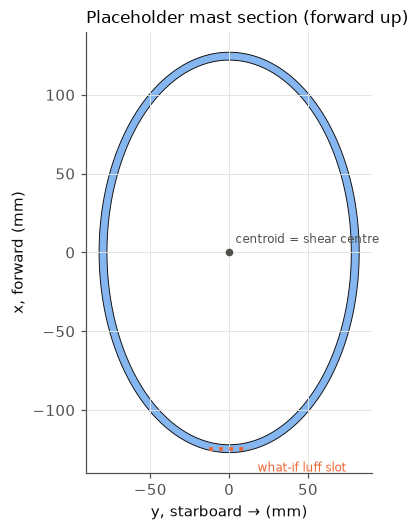

In [5]:
def mast_section(p, n=128, mesh=15.0):
    """Closed and slotted elliptical tube. Inputs in mm; returns SI (m^2, m^4) plus the shear-centre offset (m)."""
    a, b, t, s = p.mast_chord, p.mast_width, p.mast_wall, p.mast_slot
    closed = elliptical_hollow_section(d_x=a, d_y=b, t=t, n=n)
    slot = rectangular_section(d=s, b=3 * t).shift_section(x_offset=-a / 2 - 1.5 * t, y_offset=-s / 2)
    out = {}
    for name, g in [("closed", closed), ("slotted", closed - slot)]:
        sec = Section(g.create_mesh(mesh_sizes=[mesh]))
        sec.calculate_geometric_properties()
        sec.calculate_warping_properties()
        cx, cy = sec.get_c()
        ixx, iyy, _ = sec.get_ic()          # ixx = int y^2 dA (athwart bending), iyy = int x^2 dA (fore-aft)
        out[name] = {"A": sec.get_area() * 1e-6, "I_fa": iyy * 1e-12, "I_ath": ixx * 1e-12,
                     "J": sec.get_j() * 1e-12, "Cw": sec.get_gamma() * 1e-18,
                     "x_sc": (sec.get_sc()[0] - cx) * 1e-3, "section": sec}
    return out


SEC = mast_section(params)
if params.mast_override:
    MAST = {k: params.mast_override[k] for k in ("A", "I_fa", "I_ath")}
    MAST["J"] = params.mast_override.get("J", SEC["closed"]["J"])
else:
    MAST = {k: SEC["closed"][k] for k in ("A", "I_fa", "I_ath", "J")}

sec_rows = {}
for lab, v in [("closed oval (used by the frame)", SEC["closed"]), ("what-if: luff slot for an in-mast furler", SEC["slotted"])]:
    sec_rows[lab] = {"A (mm²)": v["A"] * 1e6, "mass (kg/m)": v["A"] * 2700, "I_fa (cm⁴)": v["I_fa"] * 1e8,
                     "I_ath (cm⁴)": v["I_ath"] * 1e8, "J (cm⁴)": v["J"] * 1e8, "Cw (cm⁶)": v["Cw"] * 1e12,
                     "shear centre fwd of centroid (mm)": v["x_sc"] * 1e3}
display(pd.DataFrame(sec_rows).T.style.format("{:.4g}"))
print(f"Frame uses: A = {MAST['A']*1e6:.0f} mm², I_fa = {MAST['I_fa']*1e8:.0f} cm⁴, I_ath = {MAST['I_ath']*1e8:.0f} cm⁴, "
      f"J = {MAST['J']*1e8:.0f} cm⁴ ({'maker' if params.mast_override else 'placeholder oval'})")

fig, ax = plt.subplots(figsize=(4.0, 5.2))
th = np.linspace(0, 2 * np.pi, 200)
a_, b_, t_ = params.mast_chord / 2, params.mast_width / 2, params.mast_wall
ax.fill(b_ * np.sin(th), a_ * np.cos(th), color="#86b6ef", ec="#0b0b0b", lw=0.6)
ax.fill((b_ - t_) * np.sin(th), (a_ - t_) * np.cos(th), color="white", ec="#0b0b0b", lw=0.6)
ax.plot([-params.mast_slot / 2, params.mast_slot / 2], [-a_ + t_ / 2] * 2, color=C_OPS_PD, lw=2.5, ls=":")
ax.text(18, -a_ - 12, "what-if luff slot", fontsize=8, color=C_OPS_PD)
ax.plot([0], [0], "o", color="#52514e", ms=4); ax.text(4, 6, "centroid = shear centre", fontsize=8, color="#52514e")
ax.set_aspect("equal"); ax.set_xlabel("y, starboard → (mm)"); ax.set_ylabel("x, forward (mm)")
ax.set_title("Placeholder mast section (forward up)", loc="left", fontsize=11)
plt.show()

---
## §3 Geometry, shared by both solvers

`rig_geometry` lays out nodes and members once, in boat axes. Pynite and OpenSees are both built
from it, so they can't drift apart.

- **Mast:** keel-stepped means pinned at the heel and held laterally at the partners. Twist is held
  at the heel. The mesh is no coarser than `h_max`, with a node at every level that matters.
- **Spreaders** are beams cantilevered from the mast, root free to rotate in the vertical plane, so they
  carry end thrust and fore-and-aft bending but no vertical load.
- **Caps are continuous wires clamped at the spreader tip:** V1 from the chainplate to the tip, V2 from
  the tip to the masthead.
- **Forward and aft lowers** run from their own chainplates straight to the spreader root.
- **Two stays:** the forestay from the bowsprit end to the masthead, and the staysail stay from the
  foredeck to its tang. In the stay-sag case (§10) each becomes a chain of segments so the headsails' load
  can act along it.
- **Every wire has its own chainplate node, fully fixed.** Its reaction is that wire's tension, and
  its turnbuckle can be set without dragging the others along.

In [6]:
GROUP_OF = {}   # wire segment name -> group
STAYS = ("forestay", "staysail_stay")


def rig_geometry(p, segmented_stays=False):
    nodes, beams, wires, supports = {}, [], [], {}
    zs1, z_stay = p.spreader_z_frac * p.I, p.staysail_z_frac * p.I
    z_head, z_top = p.I, p.I + p.mast_above_hounds
    z_bottom = p.z_heel if p.keel_stepped else 0.0
    z_mainhead = p.z_boom + p.P
    levels = sorted({z_bottom, 0.0, p.z_boom, zs1, z_stay, z_mainhead, p.z_boom + p.reef_fraction * p.P, z_head, z_top})
    zlist = [levels[0]]
    for z0, z1 in zip(levels[:-1], levels[1:]):
        n = max(1, math.ceil((z1 - z0) / p.h_max - 1e-9))
        zlist += list(np.linspace(z0, z1, n + 1)[1:])
    mast_nodes = []
    for k, z in enumerate(zlist):
        nm = f"M{k:02d}"
        nodes[nm] = (0.0, 0.0, float(z))
        mast_nodes.append(nm)

    def at(z):
        return min(mast_nodes, key=lambda n: abs(nodes[n][2] - z))

    key = {"bottom": mast_nodes[0], "partners": at(0.0), "boom": at(p.z_boom), "s1": at(zs1), "stay": at(z_stay),
           "mainhead": at(z_mainhead), "head": at(z_head), "top": mast_nodes[-1]}
    for a, b in zip(mast_nodes[:-1], mast_nodes[1:]):
        beams.append({"name": f"mast_{a}", "i": a, "j": b, "kind": "mast"})

    # supports: True = fixed, in BOAT axes (ux, uy, uz, rx, ry, rz)
    supports[key["bottom"]] = (True, True, True, False, False, True)
    if p.keel_stepped:
        supports[key["partners"]] = (True, True, False, False, False, False)

    sw = math.radians(p.sweep_deg)
    for side, s in (("P", 1.0), ("S", -1.0)):
        tip = f"T1{side}"
        nodes[tip] = (-p.spreader_len * math.sin(sw), s * p.spreader_len * math.cos(sw), zs1)
        beams.append({"name": f"spreader1_{side}", "i": key["s1"], "j": tip, "kind": "spreader"})

        def chain(group, pts, labels):
            cp = f"CP_{group}_{side}"
            cx, cy = p.chainplate[group]
            nodes[cp] = (cx, s * cy, 0.0)
            supports[cp] = (True,) * 6
            seq = [cp] + pts
            for seg, (a, b) in zip(labels, zip(seq[:-1], seq[1:])):
                wires.append({"name": f"{group}_{seg}_{side}", "i": a, "j": b, "group": group,
                              "bottom": a == cp, "side": side})

        chain("cap", [tip, key["head"]], ["V1", "V2"])
        chain("lowerF", [key["s1"]], ["D1F"])
        chain("lowerA", [key["s1"]], ["D1A"])
        bs = f"BS_{side}"
        nodes[bs] = (p.backstay_foot[0], s * p.backstay_foot[1], p.backstay_foot[2])
        supports[bs] = (True,) * 6
        wires.append({"name": f"backstay_{side}", "i": bs, "j": key["head"], "group": "backstay",
                      "bottom": True, "side": side})

    # The two stays: one straight member each, or a chain of segments when a headsail's load is to act along it
    # (the stay-sag case, §10). Interior nodes have only translational stiffness, so their rotations are held.
    stays = {}
    for group, tack, tack_xyz, top, nseg_s, pre in (
            ("forestay", "STEM", tuple(p.stem), key["head"], p.forestay_segments, "FS"),
            ("staysail_stay", "SSTACK", (p.staysail_tack_x, 0.0, 0.0), key["stay"], p.staysail_segments, "SS")):
        nodes[tack] = tack_xyz
        supports[tack] = (True,) * 6
        nseg = nseg_s if segmented_stays else 1
        seq = [tack]
        for k in range(1, nseg):
            nm = f"{pre}{k:02d}"
            nodes[nm] = tuple(np.add(tack_xyz, k / nseg * np.subtract(nodes[top], tack_xyz)))
            supports[nm] = (False, False, False, True, True, True)
            seq.append(nm)
        seq.append(top)
        for k, (a, b) in enumerate(zip(seq[:-1], seq[1:])):
            wires.append({"name": group if k == 0 else f"{group}_s{k+1:02d}", "i": a, "j": b,
                          "group": group, "bottom": k == 0, "side": "C"})
        stays[group] = seq
    for w in wires:
        GROUP_OF[w["name"]] = w["group"]
    return {"nodes": nodes, "beams": beams, "wires": wires, "supports": supports, "key": key, "stays": stays,
            "stay_interior": [n for seq in stays.values() for n in seq[1:-1]], "mast_nodes": mast_nodes,
            "z": {"s1": zs1, "stay": z_stay, "head": z_head, "mainhead": z_mainhead}}


def unit(a, b):
    v = np.subtract(b, a)
    return v / np.linalg.norm(v)


def seg_len(geo, w):
    return float(np.linalg.norm(np.subtract(geo["nodes"][w["j"]], geo["nodes"][w["i"]])))


def group_len(geo, group):
    return sum(seg_len(geo, w) for w in geo["wires"] if w["group"] == group and w["side"] in ("P", "C"))


GEO = rig_geometry(params)
print(f"{len(GEO['nodes'])} nodes, {len(GEO['beams'])} beams ({sum(b['kind']=='mast' for b in GEO['beams'])} mast), "
      f"{len(GEO['wires'])} wire segments")
for w in GEO["wires"]:
    if w["side"] in ("P", "C"):
        print(f"  {w['name']:<16} {w['i']:>12} -> {w['j']:<6} L = {seg_len(GEO, w):6.3f} m")

51 nodes, 40 beams (38 mast), 12 wire segments
  cap_V1_P             CP_cap_P -> T1P    L =  7.603 m
  cap_V2_P                  T1P -> M37    L =  7.731 m
  lowerF_D1F_P      CP_lowerF_P -> M20    L =  7.806 m
  lowerA_D1A_P      CP_lowerA_P -> M20    L =  7.827 m
  backstay_P               BS_P -> M37    L = 16.528 m
  forestay                 STEM -> M37    L = 16.123 m
  staysail_stay          SSTACK -> M20    L =  8.537 m


### The spreader tip must push the cap outboard

A spreader does its job only if the wire **bends outward** at the tip, so the tip carries
compression into the spreader. If the tip sits inside the straight line from chainplate to masthead,
the wire pulls the spreader outward and the geometry is wrong.

In [7]:
def wire_bend_check(geo):
    n = geo["nodes"]; rows = []
    for k, (a, tip, b) in enumerate([("CP_cap_P", "T1P", geo["key"]["head"])], start=1):
        pa, pt, pb = map(np.array, (n[a], n[tip], n[b]))
        f = (pt[2] - pa[2]) / (pb[2] - pa[2])
        y_line = pa[1] + f * (pb[1] - pa[1])
        rows.append({"spreader": k, "tip |y| (m)": abs(pt[1]), "straight-line |y| (m)": abs(y_line),
                     "deflection outboard (mm)": (abs(pt[1]) - abs(y_line)) * 1e3,
                     "wire angle at tip (deg)": math.degrees(math.acos(np.dot(unit(pa, pt), unit(pt, pb)))),
                     "cap angle to mast above the tip (deg)": math.degrees(math.atan2(abs(pt[1]), pb[2] - pt[2]))})
    return pd.DataFrame(rows).set_index("spreader")


BEND = wire_bend_check(GEO)
display(BEND.style.format("{:.3f}"))
assert (BEND["deflection outboard (mm)"] > 0).all(), "the spreader tip is inside the wire line: check its length"

,tip |y| (m),straight-line |y| (m),deflection outboard (mm),wire angle at tip (deg),cap angle to mast above the tip (deg)
spreader,,,,,
1,1.450,0.900,550.000,8.205,10.810


---
## §4 Loads: dock tune and the righting-moment case

**Dock tune** has no external load, only turnbuckle shortenings. In Pynite each one is an enforced
displacement of that wire's chainplate node, $\delta$ along the wire axis away from the mast (the
lack-of-fit method). OpenSees applies the same $\delta$ as an initial strain $\varepsilon_0 = \delta / L$
in the bottom segment, a separate route to the same physics.

**Sailing case.** Heel is to starboard, so the wind is from port, the port shrouds are to windward, and
the sail force acts toward $-y$. A cutter carries up to three sails, split **by area** at one pressure:

- $A_m = \tfrac12 P E$ (main), $A_g = \tfrac12 I J \cdot (LP/J)$ (genoa),
  $A_s = \tfrac12 I_s J_s \cdot (LP/J)_s$ (staysail), where $I_s$ is the staysail stay's tang height and
  $J_s$ its tack's distance forward of the mast.
- **Main:** triangular along the mast from the boom to the head of P, largest at the boom, centroid
  at $z_{boom} + P/3$.
- **Each headsail** is a triangle on its stay, centroid at a third of the tang height. Statics puts
  **1/3 of its force at the tang and 2/3 at the tack**. The tack share goes straight into the hull.
- The pressure is scaled so the moment about the deck equals $k \cdot RM_{30}$:
  $$F_m\,\bar z_m + F_g\,\tfrac{I}{3} + F_s\,\tfrac{I_s}{3} = k\,RM_{30}$$
  Check 6 confirms it from the reactions.

The main's distributed load becomes **consistent nodal loads** element by element. Both solvers get the
same nodal vector.

**Sail plans** (`sail_plan`): `"full"` (main, genoa and staysail), `"headsail_only"` (genoa alone),
`"main_only"`, `"reefed_main_only"`, and `"staysail_reefed_main"`, the cutter's heavy-weather rig: genoa
furled, a reefed main and the staysail. That last one is what a cutter is for, and it puts the headsail
load on the staysail stay instead of the masthead.

**What this case leaves out:** fore-and-aft drive force, sheet and halyard compression, rig
self-weight, pitching inertia, and the stays' sag tension, which §10 runs separately.

In [8]:
def rm_loads(p, geo, stay_sag=False):
    """Nodal loads in boat axes {node: [Fx, Fy, Fz, Mx, My, Mz]} for heel to starboard.
    stay_sag=True spreads each headsail's load along its segmented stay instead of lumping it at the ends."""
    reefed = p.sail_plan in ("reefed_main_only", "staysail_reefed_main")
    Pm = p.P * (p.reef_fraction if reefed else 1.0)                 # luff actually set
    z_st = geo["nodes"][geo["key"]["stay"]][2]
    A_m = 0.5 * Pm * p.E if p.sail_plan != "headsail_only" else 0.0
    A_g = 0.5 * p.I * p.J * p.headsail_LP_over_J if p.sail_plan in ("full", "headsail_only") else 0.0
    A_s = 0.5 * z_st * p.staysail_tack_x * p.staysail_LP_over_J2 if p.sail_plan in ("full", "staysail_reefed_main") else 0.0
    c = {"triangular": 1 / 3, "uniform": 1 / 2}[p.main_load_shape]
    zbar_m = p.z_boom + c * Pm
    M_target = p.RM_factor * p.RM30
    pr = M_target / (A_m * zbar_m + A_g * p.I / 3 + A_s * z_st / 3)     # N per m^2 of sail
    F_m, F_g, F_s = pr * A_m, pr * A_g, pr * A_s
    loads = {n: np.zeros(6) for n in geo["nodes"]}
    e_q = np.array([0.0, -1.0, 0.0])                    # toward starboard
    z0, z1 = p.z_boom, p.z_boom + Pm
    if p.main_load_shape == "triangular":
        w = lambda z: 2 * F_m / Pm * (1 - (z - z0) / Pm)
    else:
        w = lambda z: F_m / Pm
    if F_m > 0:
        for b in geo["beams"]:
            if b["kind"] != "mast":
                continue
            za, zb = geo["nodes"][b["i"]][2], geo["nodes"][b["j"]][2]
            if za < z0 - 1e-9 or zb > z1 + 1e-9:
                continue
            L, w1, w2 = zb - za, w(za), w(zb)
            mvec = np.cross([0.0, 0.0, 1.0], e_q)
            loads[b["i"]][:3] += L * (7 * w1 + 3 * w2) / 20 * e_q
            loads[b["j"]][:3] += L * (3 * w1 + 7 * w2) / 20 * e_q
            loads[b["i"]][3:] += L**2 * (3 * w1 + 2 * w2) / 60 * mvec
            loads[b["j"]][3:] -= L**2 * (2 * w1 + 3 * w2) / 60 * mvec
    for group, F in (("forestay", F_g), ("staysail_stay", F_s)):
        seq = geo["stays"][group]
        if F == 0:
            continue
        if stay_sag:
            # Triangular luff load, largest at the tack: w(s) = w0 (1 - s/L). Same resultant and moment about the
            # deck as the lumped 1/3 + 2/3 split. Truss-consistent nodal forces; the tack share goes into the hull.
            assert len(seq) > 2, "stay_sag needs rig_geometry(p, segmented_stays=True)"
            pts = [np.array(geo["nodes"][n]) for n in seq]
            s_ = np.concatenate([[0.0], np.cumsum([np.linalg.norm(b - a) for a, b in zip(pts[:-1], pts[1:])])])
            Lf = s_[-1]
            wf = lambda s, F=F, Lf=Lf: 2 * F / Lf * (1 - s / Lf)
            for k in range(len(seq) - 1):
                Ls, w1, w2 = s_[k + 1] - s_[k], wf(s_[k]), wf(s_[k + 1])
                loads[seq[k]][:3] += Ls * (2 * w1 + w2) / 6 * e_q
                loads[seq[k + 1]][:3] += Ls * (w1 + 2 * w2) / 6 * e_q
            loads[seq[0]][:] = 0.0
        else:
            loads[seq[-1]][:3] += F / 3 * e_q
    info = {"F_main": F_m, "F_genoa": F_g, "F_staysail": F_s, "head_share_on_rig": (F_g + F_s) / 3, "pressure_Pa": pr,
            "M_target": M_target, "zbar_main": zbar_m, "z_stay": z_st}
    return {n: v for n, v in loads.items() if np.any(v)}, info


LOADS, LINFO = rm_loads(params, GEO)
print(f"main {LINFO['F_main']/1e3:.2f} kN at z = {LINFO['zbar_main']:.2f} m;  genoa {LINFO['F_genoa']/1e3:.2f} kN "
      f"(1/3 at the masthead);  staysail {LINFO['F_staysail']/1e3:.2f} kN (1/3 at z = {LINFO['z_stay']:.2f} m);  "
      f"pressure {LINFO['pressure_Pa']:.0f} Pa")
M_check = sum(GEO["nodes"][n][2] * -v[1] for n, v in LOADS.items()) + sum(v[3] for v in LOADS.values())
print(f"moment of nodal loads about the deck = {M_check/1e3:.3f} kN*m   target = {LINFO['M_target']/1e3:.3f} kN*m")

main 4.36 kN at z = 6.30 m;  genoa 7.55 kN (1/3 at the masthead);  staysail 2.09 kN (1/3 at z = 7.59 m);  pressure 141 Pa
moment of nodal loads about the deck = 70.994 kN*m   target = 70.994 kN*m


---
## §5 Pynite model and solver

- **Mast and spreader members** use `add_section(A, Iy, Iz, J)`. For a vertical member Pynite puts
  local $z$ along global $Z$ (athwart), so **$I_z$ is fore-and-aft bending ($I_{fa}$)** and $I_y$ is
  athwart bending.
- **Wires** are `tension_only` members with negligible $I$ and every end moment released. Pynite's
  axial force is **positive in compression**, so tension = −`axial`.
- **Solver:** `analyze_PDelta` throughout. Pynite 1.0.1's P-Delta is **two-cycle**: it stops after the
  second geometric-stiffness update rather than iterating to convergence. The OpenSees corotational run in
  §9 is the reference.

**Dock tune by Newton iteration.** Five turnbuckles this time:
$\boldsymbol\delta = (\delta_{cap}, \delta_{fwd\,lower}, \delta_{aft\,lower}, \delta_{backstay}, \delta_{staysail\,stay})$,
with five bottom-segment tension targets. The Jacobian comes from unit perturbations. The forward lowers,
aft lowers and staysail stay all pull on the spreader root, so they interact strongly; the Newton handles
that because it solves for all five together.

In [9]:
TUNED = ("cap", "lowerF", "lowerA", "backstay", "staysail_stay")              # turnbuckles (unknowns)
TARGET_OF = {"cap": "cap", "lowerF": "lowerF", "lowerA": "lowerA", "backstay": "forestay",
             "staysail_stay": "staysail_stay"}                                  # tension each one sets


def build_pynite(p, geo, sec, deltas, loads=None):
    m = FEModel3D()
    m.add_material("Al", p.E_al, p.G_al, 0.33, 2700)
    m.add_material("Wire", p.E_wire, p.E_wire / 2.6, 0.3, 7950)
    m.add_section("mast", sec["A"], sec["I_ath"], sec["I_fa"], sec["J"])
    ss = p.spreader_section
    m.add_section("spreader", ss["A"], ss["I_horiz"], ss["I_vert"], ss["J"])
    for nm, xyz in geo["nodes"].items():
        m.add_node(nm, *to_solver(xyz))
    for nm, fix in geo["supports"].items():
        t = to_solver(fix[:3]); r = to_solver(fix[3:])
        m.def_support(nm, *(bool(abs(v)) for v in t), *(bool(abs(v)) for v in r))
    for nm in geo["stay_interior"]:
        # Pynite's first P-Delta cycle takes zero axial force, so a chain of pin-ended wire segments has no
        # sideways stiffness at its interior nodes. A 1 N/m spring removes the singularity; the wire's own
        # string stiffness there (T/L, about 1e4 N/m) is four orders larger.
        for dof in ("DX", "DY", "DZ"):
            m.def_support_spring(nm, dof, 1.0)
    for b in geo["beams"]:
        m.add_member(b["name"], b["i"], b["j"], "Al", b["kind"])
        if b["kind"] == "spreader" and p.release_spreader_root:
            m.def_releases(b["name"], Rzi=True)          # local z is horizontal for a horizontal member
    for w in geo["wires"]:
        size = p.wire[w["group"]]
        sname = f"wire_{size}"
        if sname not in m.sections:
            m.add_section(sname, wire_props(size)["A"], 1e-12, 1e-12, 1e-12)
        m.add_member(w["name"], w["i"], w["j"], "Wire", sname, tension_only=True)
        m.def_releases(w["name"], Ryi=True, Rzi=True, Rxj=True, Ryj=True, Rzj=True)
        d = deltas.get(w["group"], 0.0) if w["bottom"] else 0.0
        if d:
            cp, other = w["i"], w["j"]                    # chainplate end, mast end
            disp = to_solver(-d * unit(geo["nodes"][cp], geo["nodes"][other]))   # pull the chainplate away from the mast
            for comp, val in zip(("DX", "DY", "DZ"), disp):
                m.def_node_disp(cp, comp, float(val))
    m.add_load_combo("Dock", {})
    if loads:
        for nm, v in loads.items():
            F, M = to_solver(v[:3]), to_solver(v[3:])
            for comp, val in zip(("FX", "FY", "FZ", "MX", "MY", "MZ"), (*F, *M)):
                if abs(val) > 0:
                    m.add_node_load(nm, comp, float(val), case="Sail")
        m.add_load_combo("RM", {"Sail": 1.0})
    return m


def pynite_tensions(m, geo, combo):
    out = {}
    for w in geo["wires"]:
        mem = m.members[w["name"]]
        out[w["name"]] = 0.0 if not mem.active.get(combo, True) else -mem.axial(mem.L() / 2, combo)
    return out


def solve_pynite(p, geo, sec, deltas, loads=None, pdelta=True):
    m = build_pynite(p, geo, sec, deltas, loads)
    # Coincident chainplate nodes make Pynite's "is this node on the member?" angle test divide 0/0.
    # It returns NaN, which correctly means "no", so the warning is noise.
    with np.errstate(invalid="ignore"):
        (m.analyze_PDelta if pdelta else m.analyze)(check_stability=False)
    return m


def tune(p, geo, sec, pdelta=True, tol=1.0, max_iter=8, verbose=False):
    """Turnbuckle shortenings (m) that put the target tension in each tuned group's bottom segment."""
    target = np.array([p.pretension_pct[TARGET_OF[g]] / 100 * wire_props(p.wire[TARGET_OF[g]])["MBL"] for g in TUNED])
    probe = {g: next(w["name"] for w in geo["wires"]
                     if w["group"] == TARGET_OF[g] and w["bottom"] and w["side"] in ("P", "C")) for g in TUNED}

    def T_of(dvec):
        m = solve_pynite(p, geo, sec, dict(zip(TUNED, dvec)), None, pdelta)
        t = pynite_tensions(m, geo, "Dock")
        return np.array([t[probe[g]] for g in TUNED])

    # Start from each wire's own stretch, T L / EA, so every wire is taut. At delta = 0 every wire is
    # slack, and a tension-only Jacobian taken there is meaningless. A stay counts its whole length.
    def L0(g):
        if TARGET_OF[g] in STAYS:
            return group_len(geo, TARGET_OF[g])
        return seg_len(geo, next(w for w in geo["wires"] if w["name"] == probe[g]))
    d = np.array([target[k] * L0(g) / (wire_props(p.wire[TARGET_OF[g]])["A"] * p.E_wire)
                  for k, g in enumerate(TUNED)])
    T, h = T_of(d), 2e-4
    for it in range(max_iter):
        Jm = np.column_stack([(T_of(d + h * np.eye(len(TUNED))[k]) - T) / h for k in range(len(TUNED))])
        step = np.linalg.solve(Jm, target - T)
        for _ in range(6):                                # halve the step if a wire goes slack and the error grows
            T_new = T_of(d + step)
            if np.max(np.abs(T_new - target)) < np.max(np.abs(T - target)):
                break
            step = step / 2
        d, T = d + step, T_new
        if verbose:
            print(f"  iter {it+1}: max |T - target| = {np.max(np.abs(T - target)):.3e} N")
        if np.max(np.abs(T - target)) < tol:
            break
    return dict(zip(TUNED, d)), dict(zip(TUNED, T)), dict(zip(TUNED, target))


t0 = time.perf_counter()
DELTAS, T_TUNED, T_TARGET = tune(params, GEO, MAST, verbose=True)
print(f"tuned in {time.perf_counter()-t0:.1f} s")
display(pd.DataFrame({"sets tension in": [TARGET_OF[g] for g in TUNED],
                      "wire": [params.wire[TARGET_OF[g]] for g in TUNED],
                      "target (% MBL)": [params.pretension_pct[TARGET_OF[g]] for g in TUNED],
                      "target (kN)": [T_TARGET[g] / 1e3 for g in TUNED],
                      "target (lbf)": [T_TARGET[g] / LBF for g in TUNED],
                      "achieved (kN)": [T_TUNED[g] / 1e3 for g in TUNED],
                      "turnbuckle shortening (mm)": [DELTAS[g] * 1e3 for g in TUNED]},
                     index=[f"{g} turnbuckle" for g in TUNED])
        .style.format({"target (% MBL)": "{:.0f}", "target (kN)": "{:.2f}", "target (lbf)": "{:,.0f}",
                       "achieved (kN)": "{:.2f}", "turnbuckle shortening (mm)": "{:.2f}"}))

  iter 1: max |T - target| = 1.856e+02 N


  iter 2: max |T - target| = 1.576e-02 N
tuned in 9.3 s


,sets tension in,wire,target (% MBL),target (kN),target (lbf),achieved (kN),turnbuckle shortening (mm)
cap turnbuckle,cap,3/8 in,20,12.90,"2,900",12.90,30.94
lowerF turnbuckle,lowerF,5/16 in,10,4.72,"1,060",4.72,10.08
lowerA turnbuckle,lowerA,5/16 in,15,7.07,"1,590",7.07,13.06
backstay turnbuckle,forestay,3/8 in,20,12.90,"2,900",12.90,62.45
staysail_stay turnbuckle,staysail_stay,5/16 in,10,4.72,"1,060",4.72,11.61


The **turnbuckle shortening** is the total length taken out of the wire by the turnbuckle, from
just slack to tuned: the wire's own stretch (about 1.7 mm/m at 20% MBL, §1) plus the mast's shortening
and bending. Constructional stretch is extra and isn't modelled.

In [10]:
M_PY = solve_pynite(params, GEO, MAST, DELTAS, LOADS, pdelta=True)


def pynite_results(m, geo, combo):
    disp = {n: to_boat((m.nodes[n].DX[combo], m.nodes[n].DY[combo], m.nodes[n].DZ[combo])) for n in geo["nodes"]}
    rx = {n: np.array([*to_boat((m.nodes[n].RxnFX[combo], m.nodes[n].RxnFY[combo], m.nodes[n].RxnFZ[combo])),
                       *to_boat((m.nodes[n].RxnMX[combo], m.nodes[n].RxnMY[combo], m.nodes[n].RxnMZ[combo]))])
          for n in geo["supports"]}
    mast_N = {b["i"]: m.members[b["name"]].axial(m.members[b["name"]].L() / 2, combo)
              for b in geo["beams"] if b["kind"] == "mast"}
    return {"T": pynite_tensions(m, geo, combo), "disp": disp, "rxn": rx, "mast_N": mast_N}


RES = {c: pynite_results(M_PY, GEO, c) for c in ("Dock", "RM")}

---
## §6 Results: wire tensions and safety factors

SF is the wire's design MBL (the lowest catalog value) divided by its tension. Windward (port)
shrouds load up and leeward (starboard) ones unload. A leeward wire that reaches zero has gone
**slack**.

In [11]:
def tension_table(res_dock, res_rm, geo, p):
    rows = []
    for w in geo["wires"]:
        mbl = wire_props(p.wire[w["group"]])["MBL"]
        td, tr = res_dock["T"][w["name"]], res_rm["T"][w["name"]]
        rows.append({"segment": w["name"], "wire": p.wire[w["group"]], "MBL (kN)": mbl / 1e3,
                     "dock (kN)": td / 1e3, "RM case (kN)": tr / 1e3,
                     "RM % MBL": 100 * tr / mbl, "SF (RM)": mbl / tr if tr > 1 else np.inf,
                     "slack in RM case": "SLACK" if tr < 1.0 else ""})
    return pd.DataFrame(rows).set_index("segment")


TT = tension_table(RES["Dock"], RES["RM"], GEO, params)
display(TT.style.format({"MBL (kN)": "{:.1f}", "dock (kN)": "{:.2f}", "RM case (kN)": "{:.2f}",
                         "RM % MBL": "{:.1f}", "SF (RM)": "{:.2f}"}))

head = GEO["key"]["head"]
dh = RES["RM"]["disp"][head]
Nmax = {c: max(RES[c]["mast_N"].values()) for c in RES}
print(f"masthead displacement, RM case: fwd {dh[0]*1e3:+.1f} mm, port {dh[1]*1e3:+.1f} mm, up {dh[2]*1e3:+.2f} mm")
print(f"max mast compression: dock {Nmax['Dock']/1e3:.1f} kN, RM case {Nmax['RM']/1e3:.1f} kN")

,wire,MBL (kN),dock (kN),RM case (kN),RM % MBL,SF (RM),slack in RM case
segment,,,,,,,
cap_V1_P,3/8 in,64.5,12.90,19.28,29.9,3.34,
cap_V2_P,3/8 in,64.5,13.14,19.65,30.5,3.28,
lowerF_D1F_P,5/16 in,47.2,4.72,11.14,23.6,4.23,
lowerA_D1A_P,5/16 in,47.2,7.07,13.56,28.8,3.48,
backstay_P,5/16 in,47.2,5.23,7.40,15.7,6.37,
cap_V1_S,3/8 in,64.5,12.90,6.47,10.0,9.97,
cap_V2_S,3/8 in,64.5,13.14,6.59,10.2,9.79,
lowerF_D1F_S,5/16 in,47.2,4.72,0.00,0.0,inf,SLACK
lowerA_D1A_S,5/16 in,47.2,7.07,0.63,1.3,75.01,


masthead displacement, RM case: fwd -93.9 mm, port -102.0 mm, up -4.69 mm
max mast compression: dock 74.3 kN, RM case 75.7 kN


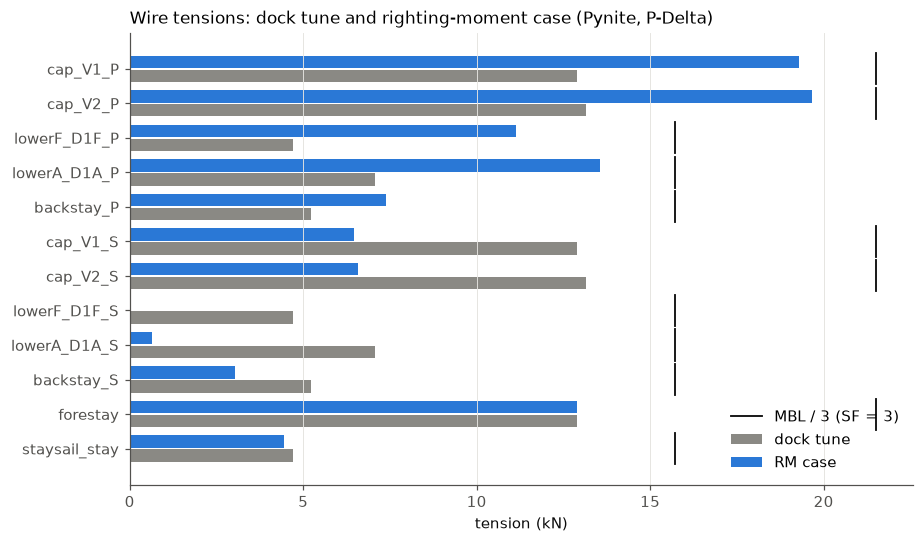

In [12]:
def plot_tensions(tt):
    segs = list(tt.index)
    y = np.arange(len(segs))
    fig, ax = plt.subplots(figsize=(8.5, 0.32 * len(segs) + 1.2))
    ax.barh(y + 0.2, tt["dock (kN)"], height=0.36, color=C_GREY, label="dock tune")
    ax.barh(y - 0.2, tt["RM case (kN)"], height=0.36, color=C_PYNITE, label="RM case")
    for k, s in enumerate(segs):
        ax.plot([tt.loc[s, "MBL (kN)"] / 3] * 2, [k - 0.45, k + 0.45], color="#0b0b0b", lw=1.2)
    ax.plot([], [], color="#0b0b0b", lw=1.2, label="MBL / 3 (SF = 3)")
    ax.set_yticks(y, segs); ax.invert_yaxis()
    ax.set_xlabel("tension (kN)"); ax.grid(axis="y", visible=False)
    ax.set_title("Wire tensions: dock tune and righting-moment case (Pynite, P-Delta)", loc="left", fontsize=11)
    ax.legend(loc="lower right", frameon=False)
    plt.tight_layout(); plt.show()


plot_tensions(TT)

### What the tensions show (default placeholders)

- **The dock tune bows the mast forward, about 50 mm at the spreader.** The staysail stay pulls the
  spreader root forward with 2.15 kN, and the forward lowers add 0.66 kN. The aft lowers answer only
  1.45 kN, because they lead just 0.10 of their tension aft. To straighten the mast with the aft lowers
  alone, each would need about 13.8 kN, 29% of MBL (§7 prints the arithmetic). So a rigger can't tune
  this pre-bend out with the lowers. How much of it the real boat has depends on where its staysail tang
  and aft-lower chainplates actually are.
- **The caps are the most loaded wires with full sails:** the windward cap's upper segment V2 carries
  19.7 kN (30% of MBL, SF 3.3) and V1 19.3 kN.
- **The aft lowers work harder than the forward lowers** (13.6 against 11.1 kN to windward). They're
  tuned harder, and they carry part of the staysail stay's pull as well as the side load.
- **To leeward, the forward lower goes slack and the aft lower drops to 0.6 kN.** The leeward side of
  the lower mast is held by the cap alone. That happens in every sailing case.
- **The forestay and staysail stay barely change** (12.9 and 4.5 kN), because in this case only the
  headsails' one-third shares reach the tangs. §10's stay-sag cases run the loads along the stays, and
  they change the picture.
- **These SFs are against design MBL.** The 5/16 in figure rests on one catalog (§1), so the lowers'
  and backstays' margins are the least certain numbers here.

---
## §7 Mast bend and the deformed rig

Displacements are measured from the **as-drawn geometry, in which every wire is stress-free**, so the
masthead's dock movement includes the forestay's own stretch: that's **rake**, set on a real boat by the
forestay length. The bend plot removes it by measuring from the chord through the partners and the
masthead, which is what you see sighting up the mast.

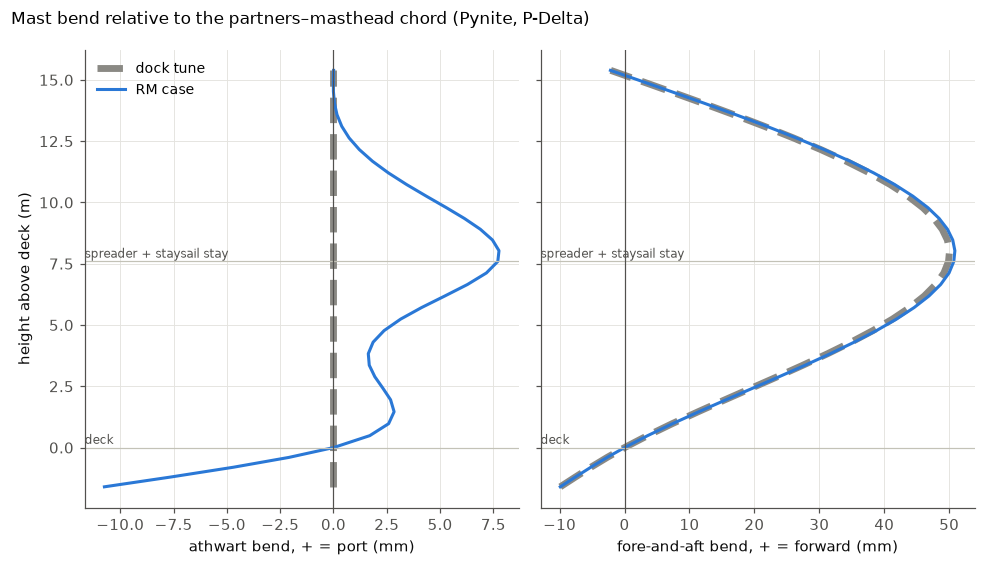

Dock: masthead moves  -93.9 mm fwd,   -0.0 mm port (chord rake +0.35° aft)
RM  : masthead moves  -93.9 mm fwd, -102.0 mm port (chord rake +0.35° aft)
dock pre-bend: largest forward bow 50.1 mm at z = 8.0 m
fore-and-aft pulls at the spreader root: lowerF_D1F_P +0.33 kN, lowerA_D1A_P -0.72 kN, lowerF_D1F_S +0.33 kN, lowerA_D1A_S -0.72 kN, staysail_stay +2.15 kN
aft lowers lead only 0.102 of their tension aft; to cancel 2.82 kN forward they would each need 13.8 kN = 29% of MBL


In [13]:
def mast_curve(res, geo, comp, chord=True):
    """Mast displacement along `comp` against height. chord=True subtracts the straight line through the
    partners (z = 0) and the masthead, leaving the bend a sailor sees by sighting up the mast."""
    zs = np.array([geo["nodes"][n][2] for n in geo["mast_nodes"]])
    u = np.array([res["disp"][n][comp] for n in geo["mast_nodes"]])
    if chord:
        h = geo["key"]["head"]
        u = u - res["disp"][h][comp] * zs / geo["nodes"][h][2]
    return zs, u


def level_lines(ax, x_text):
    marks = [(GEO["z"]["s1"], "spreader"), (0.0, "deck")]
    if abs(GEO["z"]["stay"] - GEO["z"]["s1"]) > 0.05:
        marks.append((GEO["z"]["stay"], "staysail stay"))
    else:
        marks[0] = (GEO["z"]["s1"], "spreader + staysail stay")
    for zz, t in marks:
        ax.axhline(zz, color="#c3c2b7", lw=0.8)
        ax.text(x_text, zz + 0.15, t, fontsize=8, color="#52514e")


def plot_bend(curves, title):
    fig, axs = plt.subplots(1, 2, figsize=(9, 5.2), sharey=True)
    for ax, comp, lab in zip(axs, (1, 0), ("athwart bend, + = port (mm)", "fore-and-aft bend, + = forward (mm)")):
        for k, (name, (res, color, ls)) in enumerate(curves.items()):
            z, u = mast_curve(res, GEO, comp)
            ax.plot(u * 1e3, z, color=color, ls=ls, label=name, lw=4.5 if k == 0 else 2.0,
                    alpha=0.45 if k == 0 and len(curves) > 2 else 1.0)
        level_lines(ax, ax.get_xlim()[0])
        ax.axvline(0, color="#52514e", lw=0.8)
        ax.set_xlabel(lab)
    axs[0].set_ylabel("height above deck (m)")
    axs[0].legend(frameon=False, loc="upper left", fontsize=9)
    fig.suptitle(title, x=0.01, ha="left", fontsize=11)
    plt.tight_layout(); plt.show()


plot_bend({"dock tune": (RES["Dock"], C_GREY, "--"), "RM case": (RES["RM"], C_PYNITE, "-")},
          "Mast bend relative to the partners–masthead chord (Pynite, P-Delta)")
for c in ("Dock", "RM"):
    d_ = RES[c]["disp"][head]
    print(f"{c:4s}: masthead moves {d_[0]*1e3:+6.1f} mm fwd, {d_[1]*1e3:+6.1f} mm port "
          f"(chord rake {math.degrees(math.atan2(-d_[0], GEO['nodes'][head][2])):+.2f}° aft)")
zb, ub = mast_curve(RES["Dock"], GEO, 0)
print(f"dock pre-bend: largest forward bow {ub.max()*1e3:.1f} mm at z = {zb[np.argmax(ub)]:.1f} m")

# What it would take to straighten it with the aft lowers alone: the fore-and-aft pulls at the spreader root, from the
# dock tensions, and the aft-lower tension that would cancel them (node statics, ignoring the mast's own bending).
root = GEO["key"]["s1"]
fx = {w["name"]: RES["Dock"]["T"][w["name"]] * unit(GEO["nodes"][root], GEO["nodes"][w["i"]])[0]
      for w in GEO["wires"] if w["j"] == root}
lever_aft = -unit(GEO["nodes"][root], GEO["nodes"]["CP_lowerA_P"])[0]
fwd_pull = sum(v for k, v in fx.items() if not k.startswith("lowerA"))
T_aft_needed = fwd_pull / (2 * lever_aft)
print(f"fore-and-aft pulls at the spreader root: " + ", ".join(f"{k} {v/1e3:+.2f} kN" for k, v in fx.items()))
print(f"aft lowers lead only {lever_aft:.3f} of their tension aft; to cancel {fwd_pull/1e3:.2f} kN forward they would each need "
      f"{T_aft_needed/1e3:.1f} kN = {100*T_aft_needed/wire_props(params.wire['lowerA'])['MBL']:.0f}% of MBL")

**Linear against P-Delta.** The same model run linear, for comparison. The amplification of sway by the
axial load grows as about $1/(1 - 1/\lambda)$, so it matters only as the buckling factor $\lambda$ (§8)
approaches 1.

In [14]:
M_LIN = solve_pynite(params, GEO, MAST, DELTAS, LOADS, pdelta=False)
RES_LIN = {c: pynite_results(M_LIN, GEO, c) for c in ("Dock", "RM")}
display(pd.DataFrame({lab: {"masthead athwart (mm)": r["RM"]["disp"][head][1] * 1e3,
                            "spreader root athwart (mm)": r["RM"]["disp"][GEO["key"]["s1"]][1] * 1e3,
                            "windward cap V1 (kN)": r["RM"]["T"]["cap_V1_P"] / 1e3,
                            "leeward cap V1 (kN)": r["RM"]["T"]["cap_V1_S"] / 1e3,
                            "windward aft lower (kN)": r["RM"]["T"]["lowerA_D1A_P"] / 1e3}
                      for lab, r in (("linear", RES_LIN), ("P-Delta", RES))})
        .style.format("{:.1f}").set_caption("RM case, Pynite"))

,linear,P-Delta
masthead athwart (mm),-101.3,-102.0
spreader root athwart (mm),-43.1,-43.3
windward cap V1 (kN),19.3,19.3
leeward cap V1 (kN),6.5,6.5
windward aft lower (kN),13.4,13.6


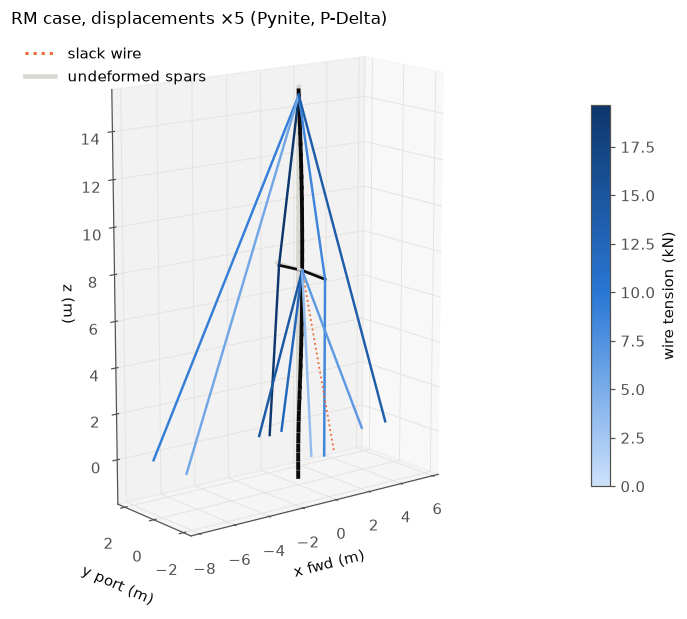

In [15]:
def plot_rig3d(geo, res, scale=20.0, title=""):
    n = geo["nodes"]
    P_ = lambda nm, s=0.0: np.add(n[nm], s * np.array(res["disp"][nm]))
    Tmax = max(res["T"].values())
    cmap = mcolors.LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#2a78d6", "#0d366b"])
    fig = plt.figure(figsize=(8, 9)); ax = fig.add_subplot(projection="3d")
    for b in geo["beams"]:
        a0, b0 = P_(b["i"]), P_(b["j"]); a1, b1 = P_(b["i"], scale), P_(b["j"], scale)
        ax.plot(*zip(a0, b0), color="#d8d7d2", lw=3 if b["kind"] == "mast" else 2)
        ax.plot(*zip(a1, b1), color="#0b0b0b", lw=2.5 if b["kind"] == "mast" else 1.8)
    for w in geo["wires"]:
        t = res["T"][w["name"]]
        a1, b1 = P_(w["i"], scale), P_(w["j"], scale)
        if t < 1.0:
            ax.plot(*zip(a1, b1), color=C_OPS_PD, lw=1.2, ls=":")
        else:
            ax.plot(*zip(a1, b1), color=cmap(0.15 + 0.85 * t / Tmax), lw=1.6)
    ax.plot([], [], color=C_OPS_PD, ls=":", label="slack wire")
    ax.plot([], [], color="#d8d7d2", lw=3, label="undeformed spars")
    ax.set_xlabel("x fwd (m)"); ax.set_ylabel("y port (m)"); ax.set_zlabel("z (m)")
    xs = [v[0] for v in n.values()]; zs = [v[2] for v in n.values()]
    ax.set_ylim(-2.5, 2.5); ax.set_yticks([-2, 0, 2])
    ax.set_box_aspect((np.ptp(xs), 5.0, np.ptp(zs)))
    ax.view_init(elev=14, azim=-128)                     # from forward, on the starboard bow
    sm = cm.ScalarMappable(cmap=cmap, norm=mcolors.Normalize(0, Tmax / 1e3))
    fig.colorbar(sm, ax=ax, shrink=0.5, pad=0.08, label="wire tension (kN)")
    ax.legend(loc="upper left", frameon=False)
    ax.set_title(title, loc="left", fontsize=11)
    plt.show()


plot_rig3d(GEO, RES["RM"], scale=5, title="RM case, displacements ×5 (Pynite, P-Delta)")

---
## §8 Buckling: linear eigenvalue from Pynite's $K$ and $K_g$

After the P-Delta solve, Pynite's `Kg(first_step=False)` builds the geometric stiffness from each
member's axial force. The buckling load factor $\lambda$ is the smallest positive root of

$$\left(K + \lambda K_g\right)\phi = 0$$

taken over the free DOFs. $\lambda$ scales **every** axial force together, pretension included.

The hand estimate treats each mast panel as a pinned Euler column, $P_{cr} = \pi^2 E I / L^2$, on the
weaker axis and the panel's peak compression. **A single-spreader rig has long panels,** about 7.6 m
here against the Oceanis's 5–6 m, and that is where its buckling margin goes.

**Torsional-flexural check.** For the closed oval it reduces to the Euler load, because the shear centre
sits at the centroid. It's still run, with the slotted what-if beside it, using Timoshenko & Gere's
result in the AISC form for singly-symmetric members:

$$P_T = \frac{GJ + \pi^2 E C_w / L^2}{r_0^2},\qquad r_0^2 = x_0^2 + \frac{I_{fa} + I_{ath}}{A},\qquad H = 1 - \frac{x_0^2}{r_0^2}$$

$$P_{TF} = \frac{P_e + P_T}{2H}\left[1 - \sqrt{1 - \frac{4 P_e P_T H}{(P_e + P_T)^2}}\right],\qquad P_e = \frac{\pi^2 E I_{ath}}{L^2}$$

In [16]:
def buckling_factor(m, combo, nmodes=3):
    D1, _, _ = _partition_D(m)
    K = m.K(combo, sparse=True, check_stability=False).toarray()
    Kg = m.Kg(combo, sparse=True, first_step=False).toarray()   # Pynite 1.0.1's dense branch has a zeros(n, n) bug
    K11, Kg11 = K[np.ix_(D1, D1)], Kg[np.ix_(D1, D1)]
    vals, vecs = sla.eig(K11, -Kg11)
    vals = np.real_if_close(vals)
    ok = np.isfinite(vals) & (np.abs(np.imag(vals)) < 1e-9) & (np.real(vals) > 1e-6)
    order = np.argsort(np.real(vals[ok]))
    lam = np.real(vals[ok])[order][:nmodes]
    phi = np.real(vecs[:, ok][:, order[:nmodes]])
    full = np.zeros((len(m.nodes) * 6, phi.shape[1])); full[D1, :] = phi
    return lam, full


PANEL_NAMES = ("deck–spreader", "spreader–head")


def panel_levels(p, geo):
    return [0.0 if p.keel_stepped else geo["nodes"][geo["key"]["bottom"]][2], geo["z"]["s1"], geo["z"]["head"]]


def euler_panels(p, geo, res, sec):
    zl = panel_levels(p, geo); rows = []
    for (za, zb), nm in zip(zip(zl[:-1], zl[1:]), PANEL_NAMES):
        N = max(v for n, v in res["mast_N"].items() if za - 1e-9 <= geo["nodes"][n][2] < zb)
        L = zb - za
        Pcr = math.pi**2 * p.E_al * min(sec["I_fa"], sec["I_ath"]) / L**2
        rows.append({"panel": nm, "L (m)": L, "peak N (kN)": N / 1e3, "Euler Pcr (kN)": Pcr / 1e3, "Pcr / N": Pcr / N})
    return pd.DataFrame(rows).set_index("panel")


def mode_kind(m, geo, phi, k, r_twist):
    """'flexural' if mast sway dominates, 'torsional' if twist about the mast axis (times r_twist) does."""
    ids = [m.nodes[n].ID for n in geo["mast_nodes"]]
    sway = max(np.hypot(phi[i * 6 + 0, k], phi[i * 6 + 2, k]) for i in ids)      # solver X and Z
    twist = max(abs(phi[i * 6 + 4, k]) for i in ids) * r_twist                   # rotation about solver Y (up)
    return "flexural" if sway >= twist else "torsional"


LAM, PHI = buckling_factor(M_PY, "RM", 6)
LAM_DOCK, PHI_DOCK = buckling_factor(M_PY, "Dock", 6)
r_tw = params.mast_chord / 2e3
KINDS = [mode_kind(M_PY, GEO, PHI, k, r_tw) for k in range(len(LAM))]
display(pd.DataFrame({"λ RM case": LAM, "kind (RM)": KINDS,
                      "λ dock": LAM_DOCK, "kind (dock)": [mode_kind(M_PY, GEO, PHI_DOCK, k, r_tw) for k in range(len(LAM_DOCK))]},
                     index=pd.RangeIndex(1, len(LAM) + 1, name="mode")).style.format({"λ RM case": "{:.2f}", "λ dock": "{:.2f}"}))
display(euler_panels(params, GEO, RES["RM"], MAST).style.format("{:.2f}"))


def torsional_flexural(p, geo, res, sec_props):
    """Open-section check per panel (Timoshenko & Gere; the AISC E4 form). Twist couples with athwart bending
    through the shear-centre offset x0 on the section's fore-aft symmetry axis."""
    zl = panel_levels(p, geo); rows = []
    for (za, zb), nm in zip(zip(zl[:-1], zl[1:]), PANEL_NAMES):
        N = max(v for n, v in res["mast_N"].items() if za - 1e-9 <= geo["nodes"][n][2] < zb)
        L = zb - za
        for label, sp in sec_props.items():
            A, x0 = sp["A"], sp["x_sc"]
            r0sq = x0**2 + (sp["I_fa"] + sp["I_ath"]) / A
            H = 1 - x0**2 / r0sq
            Pe = math.pi**2 * p.E_al * sp["I_ath"] / L**2
            PT = (p.G_al * sp["J"] + math.pi**2 * p.E_al * sp["Cw"] / L**2) / r0sq
            PTF = (Pe + PT) / (2 * H) * (1 - math.sqrt(max(0.0, 1 - 4 * Pe * PT * H / (Pe + PT)**2)))
            rows.append({"panel": nm, "section": label, "peak N (kN)": N / 1e3, "P_e (kN)": Pe / 1e3,
                         "P_T (kN)": PT / 1e3, "P_TF (kN)": PTF / 1e3, "P_TF / N": PTF / N})
    return pd.DataFrame(rows).set_index(["panel", "section"])


TF_SECS = {"closed oval (as modelled)": {**SEC["closed"], **{k: MAST[k] for k in ("A", "I_fa", "I_ath")}},
           "what-if: slotted for in-mast furling": SEC["slotted"]}
TF = torsional_flexural(params, GEO, RES["RM"], TF_SECS)
display(TF.style.format("{:.2f}"))

,λ RM case,kind (RM),λ dock,kind (dock)
mode,,,,
1,3.01,flexural,3.05,flexural
2,5.71,flexural,5.78,flexural
3,5.78,flexural,5.83,flexural
4,9.46,flexural,9.79,flexural
5,10.48,flexural,10.79,flexural
6,12.76,flexural,13.11,flexural


,L (m),peak N (kN),Euler Pcr (kN),Pcr / N
panel,,,,
deck–spreader,7.59,75.69,136.54,1.80
spreader–head,7.59,47.19,136.54,2.89


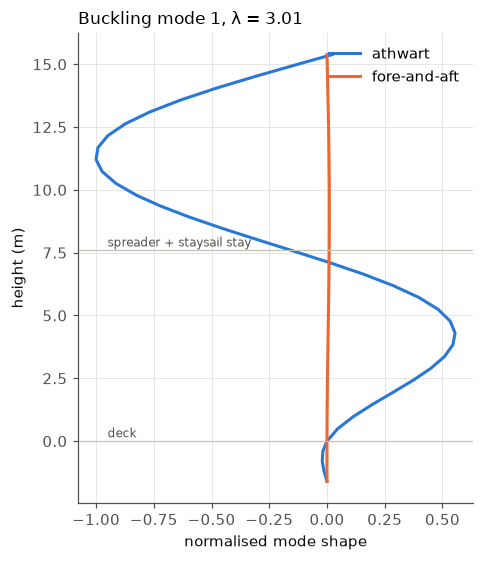

In [17]:
def plot_mode(m, geo, phi, lam, k=0):
    ids = {nm: m.nodes[nm].ID for nm in geo["mast_nodes"]}
    z = np.array([geo["nodes"][n][2] for n in geo["mast_nodes"]])
    u = np.array([to_boat(phi[ids[n] * 6:ids[n] * 6 + 3, k]) for n in geo["mast_nodes"]])
    u = u / np.max(np.abs(u))
    fig, ax = plt.subplots(figsize=(4.5, 5.2))
    ax.plot(u[:, 1], z, color=C_PYNITE, label="athwart")
    ax.plot(u[:, 0], z, color=C_OPS_PD, label="fore-and-aft")
    level_lines(ax, -0.95)
    ax.set_xlabel("normalised mode shape"); ax.set_ylabel("height (m)")
    ax.set_title(f"Buckling mode {k+1}, λ = {lam[k]:.2f}", loc="left", fontsize=11)
    ax.legend(frameon=False, loc="upper right"); plt.tight_layout(); plt.show()


plot_mode(M_PY, GEO, PHI, LAM, 0)

### What the buckling numbers say (placeholder section and geometry)

- **First mode: λ ≈ 3.0, flexural,** at the dock and sailing alike, because pretension supplies almost all
  of the mast's compression (74 kN at the dock, 76 kN with full sails). That's lower than the Oceanis's
  4.5. The single spreader leaves two 7.6 m panels, and the pinned-panel Euler estimate for the lower one
  is only 1.8 times its compression. The frame does better than that floor because the mast is continuous
  and the taut wires stiffen it.
- **A single column at λ = 3 would sway 1.5 times its linear value.** The rig shows only 0.7% more
  masthead sway than a linear run (101.3 against 102.0 mm), because the wires' string stiffness offsets
  most of the mast's softening.
- **Torsional-flexural buckling doesn't arise for the closed oval.** Its shear centre is at the centroid,
  so $P_{TF}$ is just the Euler load; $P_T$ is about 75,000 kN.
- **The slotted what-if fails that check** ($P_{TF}/N = 0.54$ in the lower panel). Cutting a luff slot
  drops $J$ from about 2,980 to 2.5 cm⁴ and moves the shear centre 233 mm forward. An in-mast furling
  retrofit would need a section with internal walls, like the Oceanis's Z900E, not a slotted plain tube.

---
## §9 Cross-check: OpenSeesPy

**How it runs.** The model goes to OpenSeesPy as JSON, runs in a separate Python process, and comes back the same way, as with CalculiX or Elmer. The notebook uses the first interpreter that can import `openseespy`: the one named in the environment variable `RIGFRAME_OPENSEES_PYTHON`, the notebook's own, or a sidecar venv at `~/python-venvs/opensees-py312`. OpenSeesPy 3.8's Windows build links `python312.dll`, so on Windows that has to be Python 3.12; on Linux and Colab, 3.12 or later. If none is found, these checks report **SKIP**.

**License.** OpenSeesPy is free "for research, education, and internal use"; commercial
redistribution needs a license. It isn't GPL, but it isn't OSI open source either.

**The OpenSees model:**
- Same nodes. Mast and spreaders are `elasticBeamColumn` with the same section values; the spreader
  root release is `-releasez 1`.
- Wires are `corotTruss` on `InitStrainMaterial(Elastic(E, 0, Eneg=0))`, so each wire is
  tension-only. The bottom segment's initial strain is $\delta/L$, taken from Pynite's tune.
- Two stages: pretension, then `loadConst` and the sail loads ramped in ten steps.
- Two runs: with the **`PDelta`** transformation, and with **`Corotational`**, the reference.

**What the comparison found:**

- **Corotational OpenSees and P-Delta Pynite agree within 0.9% on every wire but the forestay,** and
  within 0.5% on masthead sway (check 8).
- **The forestay is 1.8% apart, and the dock bow explains it.** A bowed mast's chord is shorter than the
  mast: about 0.7 mm here, from the 50 mm pre-bend. OpenSees tracks that and puts the masthead 0.65 mm
  lower, which takes about 0.3 kN out of the forestay. Pynite's linear-strain elements can't see it.
  It's the same second-order term that makes a sagging stay stretch. The printout above gives the
  numbers, and check 8 gives the forestay a 2.5% band for this reason.
- **OpenSees's own `PDelta` transformation runs 2.4–3.9% high** on the caps, backstay and forestay
  (information table after §12), more than on the Oceanis. The corotational run is the reference.

In [18]:
OPS_SCRIPT = r'''
import json, sys
import openseespy.opensees as ops

def run(model, transf):
    ops.wipe(); ops.model("basic", "-ndm", 3, "-ndf", 6)
    tag = {}
    for k, (nm, xyz) in enumerate(model["nodes"].items(), start=1):
        tag[nm] = k; ops.node(k, *xyz)
    for nm, fix in model["fix"].items():
        ops.fix(tag[nm], *fix)
    ttags = {}
    for k, b in enumerate(model["beams"], start=1):
        vz = tuple(round(v, 12) for v in b["vecxz"])
        if vz not in ttags:
            ttags[vz] = len(ttags) + 1
            ops.geomTransf(transf, ttags[vz], *vz)
        extra = ["-releasez", 1] if b.get("release_z_i") else []
        ops.element("elasticBeamColumn", k, tag[b["i"]], tag[b["j"]], b["A"], b["E"], b["G"], b["J"],
                    b["Iy"], b["Iz"], ttags[vz], *extra)
    nb = len(model["beams"])
    for k, w in enumerate(model["wires"], start=1):
        ops.uniaxialMaterial("Elastic", 2 * k - 1, w["E"], 0.0, 0.0)
        ops.uniaxialMaterial("InitStrainMaterial", 2 * k, 2 * k - 1, w["eps0"])
        ops.element("Truss" if transf == "Linear" else "corotTruss", nb + k, tag[w["i"]], tag[w["j"]], w["A"], 2 * k)
    nw, base = len(model["wires"]), len(tag) + 1
    for k, sp in enumerate(model.get("springs", [])):      # weak grounding springs (same role as in Pynite)
        g, mt = base + k, 2 * nw + 1 + k
        ops.node(g, *ops.nodeCoord(tag[sp["node"]])); ops.fix(g, 1, 1, 1, 1, 1, 1)
        ops.uniaxialMaterial("Elastic", mt, sp["k"])
        ops.element("zeroLength", nb + nw + 1 + k, g, tag[sp["node"]], "-mat", mt, mt, mt, "-dir", 1, 2, 3)

    def solve(nsteps):
        ops.constraints("Transformation"); ops.numberer("RCM"); ops.system("UmfPack")
        ops.test("NormDispIncr", 1e-10, 200); ops.algorithm("Newton")
        ops.integrator("LoadControl", 1.0 / nsteps); ops.analysis("Static")
        for s in range(nsteps):
            if ops.analyze(1) != 0:
                ops.algorithm("KrylovNewton")
                if ops.analyze(1) != 0:
                    raise RuntimeError(f"no convergence at step {s}")
                ops.algorithm("Newton")

    def collect():
        ops.reactions()
        return {"disp": {nm: ops.nodeDisp(t)[:3] for nm, t in tag.items()},
                "T": {w["name"]: ops.eleResponse(nb + k, "axialForce")[0] for k, w in enumerate(model["wires"], start=1)},
                "rxn": {nm: ops.nodeReaction(tag[nm]) for nm in model["fix"]},
                "mast_N": {b["i"]: ops.eleResponse(k, "localForce")[0]          # i-end axial, + = compression
                           for k, b in enumerate(model["beams"], start=1) if b["kind"] == "mast"},
                "lf": [ops.eleResponse(k, "localForce") for k in range(1, len(model["beams"]) + 1)]}  # N,Vy,Vz,T,My,Mz at i then j

    ops.timeSeries("Constant", 1); ops.pattern("Plain", 1, 1)      # stage 1: pretension only
    solve(1)
    dock = collect()
    ops.loadConst("-time", 0.0)
    ops.timeSeries("Linear", 2); ops.pattern("Plain", 2, 2)
    for nm, v in model["loads"].items():
        ops.load(tag[nm], *v)
    solve(model.get("nsteps", 10))
    return {"Dock": dock, "RM": collect()}

model = json.load(open(sys.argv[1]))
out = {tr: run(model, tr) for tr in model["transfs"]}
json.dump(out, open(sys.argv[2], "w"))
'''

def find_opensees_python():
    """An interpreter that can import openseespy: $RIGFRAME_OPENSEES_PYTHON, this one, or a sidecar venv.
    None means the OpenSees cross-check is skipped."""
    import sys
    home = Path.home() / "python-venvs" / "opensees-py312"
    for c in (os.environ.get("RIGFRAME_OPENSEES_PYTHON"), sys.executable, home / "Scripts" / "python.exe", home / "bin" / "python"):
        if c and Path(c).exists() and subprocess.run([str(c), "-c", "import openseespy.opensees"],
                                                     capture_output=True).returncode == 0:
            return Path(c)
    return None


OPS_PY = find_opensees_python()
print("OpenSees cross-check:", "will run" if OPS_PY else "openseespy not found, so it will SKIP")


def pynite_local_z(m, name):
    T = m.members[name].T()
    return tuple(float(v) for v in T[2, :3])         # third row = local z in global coordinates


def opensees_model(p, geo, sec, deltas, loads, m_ref):
    model = {"nodes": {n: to_solver(xyz) for n, xyz in geo["nodes"].items()}, "fix": {}, "beams": [], "wires": [],
             "loads": {}, "transfs": ["PDelta", "Corotational"]}
    for nm, fix in geo["supports"].items():
        t, r = to_solver(fix[:3]), to_solver(fix[3:])
        model["fix"][nm] = [int(bool(abs(v))) for v in (*t, *r)]
    ss = p.spreader_section
    for b in geo["beams"]:
        if b["kind"] == "mast":
            A, Iy, Iz, J = sec["A"], sec["I_ath"], sec["I_fa"], sec["J"]
        else:
            A, Iy, Iz, J = ss["A"], ss["I_horiz"], ss["I_vert"], ss["J"]
        model["beams"].append({"i": b["i"], "j": b["j"], "kind": b["kind"], "A": A, "E": p.E_al, "G": p.G_al,
                               "J": J, "Iy": Iy, "Iz": Iz, "vecxz": pynite_local_z(m_ref, b["name"]),
                               "release_z_i": b["kind"] == "spreader" and p.release_spreader_root})
    for w in geo["wires"]:
        L = seg_len(geo, w)
        d = deltas.get(w["group"], 0.0) if w["bottom"] else 0.0
        wp = wire_props(p.wire[w["group"]])
        model["wires"].append({"name": w["name"], "i": w["i"], "j": w["j"], "A": wp["A"], "E": p.E_wire,
                               "eps0": d / L})
    for nm, v in loads.items():
        model["loads"][nm] = [*to_solver(v[:3]), *to_solver(v[3:])]
    model["springs"] = [{"node": nm, "k": 1.0} for nm in geo["stay_interior"]]
    return model


def run_opensees(model):
    if OPS_PY is None:
        return None
    work = Path(tempfile.mkdtemp(prefix="rig_ops_"))           # a temporary folder, removed afterwards
    try:
        (work / "ops_rig.py").write_text(OPS_SCRIPT)
        (work / "model.json").write_text(json.dumps(model))
        r = subprocess.run([str(OPS_PY), "-I", str(work / "ops_rig.py"), str(work / "model.json"), str(work / "out.json")],
                           capture_output=True, text=True, timeout=600)
        if r.returncode != 0:
            raise RuntimeError(r.stderr[-3000:])
        raw = json.loads((work / "out.json").read_text())
    finally:
        shutil.rmtree(work, ignore_errors=True)
    out = {}
    for tr, cases in raw.items():
        out[tr] = {}
        for c, d in cases.items():
            out[tr][c] = {"T": d["T"], "disp": {n: to_boat(v) for n, v in d["disp"].items()},
                          "rxn": {n: np.array([*to_boat(v[:3]), *to_boat(v[3:])]) for n, v in d["rxn"].items()},
                          "mast_N": d["mast_N"], "lf": d.get("lf")}
    return out


t0 = time.perf_counter()
OPS = run_opensees(opensees_model(params, GEO, MAST, DELTAS, LOADS, M_PY))
print("OpenSees:", "openseespy not found -> SKIP" if OPS is None else f"ran in {time.perf_counter()-t0:.1f} s")

OpenSees cross-check: will run


OpenSees: ran in 1.1 s


,Pynite dock,OPS PDelta dock,Pynite RM,OPS PDelta RM,OPS corot RM
segment,,,,,
cap_V1_P,12.90,13.15,19.28,19.69,19.23
cap_V2_P,13.14,13.40,19.65,20.07,19.59
lowerF_D1F_P,4.72,4.70,11.14,11.17,11.14
lowerA_D1A_P,7.07,7.05,13.56,13.59,13.55
backstay_P,5.23,5.27,7.40,7.52,7.34
cap_V1_S,12.90,13.15,6.47,6.89,6.43
cap_V2_S,13.14,13.40,6.59,7.01,6.55
lowerF_D1F_S,4.72,4.70,0.00,0.00,0.00
lowerA_D1A_S,7.07,7.05,0.63,0.68,0.62


Dock bow shortening, partners to masthead: 0.71 mm (from the Pynite curve). OpenSees corotational puts the masthead 0.65 mm lower, which shortens the forestay by 0.61 mm: 0.29 kN of its tension. Pynite's dock forestay is 12.90 kN, corotational 12.68 kN.


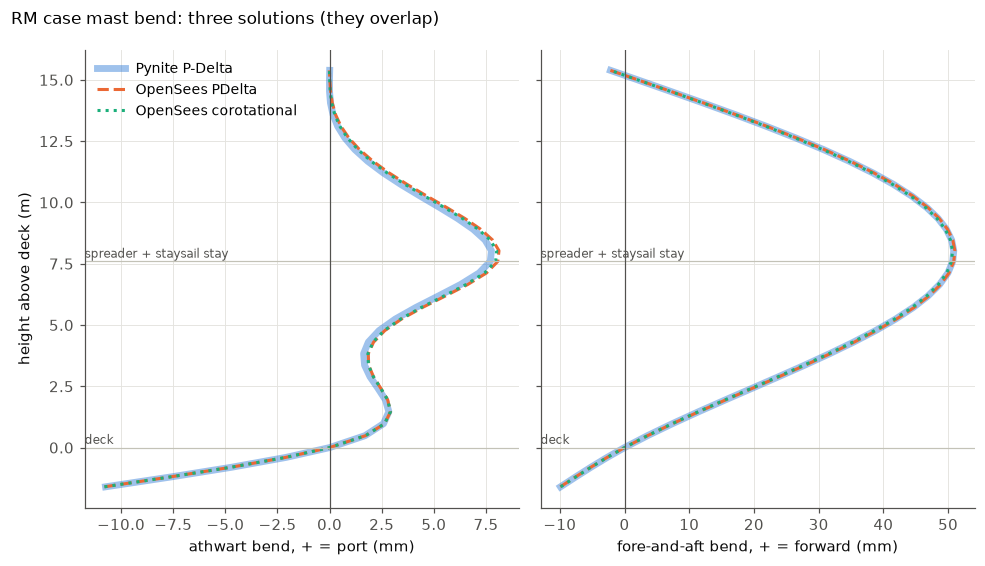

In [19]:
if OPS is not None:
    rows = []
    for w in GEO["wires"]:
        nm = w["name"]
        rows.append({"segment": nm,
                     "Pynite dock": RES["Dock"]["T"][nm] / 1e3, "OPS PDelta dock": OPS["PDelta"]["Dock"]["T"][nm] / 1e3,
                     "Pynite RM": RES["RM"]["T"][nm] / 1e3, "OPS PDelta RM": OPS["PDelta"]["RM"]["T"][nm] / 1e3,
                     "OPS corot RM": OPS["Corotational"]["RM"]["T"][nm] / 1e3})
    CMP = pd.DataFrame(rows).set_index("segment")
    display(CMP.style.format("{:.2f}").set_caption("wire tension (kN)"))

    # Why the forestay differs more than the other wires: bow shortening. A bowed mast's chord is shorter than
    # its length by about (1/2) * integral of (du/dz)^2 dz, a second-order term that linear strain leaves out.
    def bow_shortening(res):
        z_, ux = mast_curve(res, GEO, 0, chord=False)
        k = z_ >= 0.0
        return 0.5 * np.trapezoid(np.gradient(ux[k], z_[k])**2, z_[k])
    e_fs = unit(GEO["nodes"]["STEM"], GEO["nodes"][head])
    EA_fs = wire_props(params.wire["forestay"])["A"] * params.E_wire
    L_fs = group_len(GEO, "forestay")
    dz_head = OPS["Corotational"]["Dock"]["disp"][head][2] - RES["Dock"]["disp"][head][2]
    print(f"Dock bow shortening, partners to masthead: {bow_shortening(RES['Dock'])*1e3:.2f} mm (from the Pynite curve). "
          f"OpenSees corotational puts the masthead {abs(dz_head)*1e3:.2f} mm lower, which shortens the forestay by "
          f"{abs(dz_head*e_fs[2])*1e3:.2f} mm: {abs(dz_head*e_fs[2])*EA_fs/L_fs/1e3:.2f} kN of its tension. Pynite's dock forestay "
          f"is {RES['Dock']['T']['forestay']/1e3:.2f} kN, corotational {OPS['Corotational']['Dock']['T']['forestay']/1e3:.2f} kN.")
    plot_bend({"Pynite P-Delta": (RES["RM"], C_PYNITE, "-"),
               "OpenSees PDelta": (OPS["PDelta"]["RM"], C_OPS_PD, "--"),
               "OpenSees corotational": (OPS["Corotational"]["RM"], C_OPS_CR, ":")},
              "RM case mast bend: three solutions (they overlap)")

---
## §10 Load cases side by side

One table with every case run on the same tuned rig:

| Case | What it represents |
|---|---|
| Dock tune | Preload only |
| Full sails, RM ×1.0 | Main, genoa and staysail; the rig carries $RM_{30}$ |
| Full sails, RM ×1.5 | The same, with the gust or heel-beyond-30° factor that rig-sizing methods commonly apply |
| Genoa only, RM ×1.0 | The whole heeling moment through the genoa, so all of it at the masthead |
| Staysail + reefed main, RM ×1.0 | The cutter's heavy-weather rig: genoa furled, main reefed to `reef_fraction` of P, staysail set |
| Reefed main only, RM ×1.0 | The whole moment through a deeply reefed main, low on the mast |
| Stay sag, RM ×1.0 and ×1.5 | Full sails, with the genoa and staysail loads acting **along** the forestay and the staysail stay |
| Staysail + reefed main, stay sag, RM ×1.0 | The heavy-weather rig again, with the staysail's load along its stay: the case that loads the staysail stay and its tang |

**Why the stay-sag case needs the corotational solver.** A headsail pushes its stay sideways. A taut
wire that sags lengthens, so its tension rises. The extra length is second order,
$\Delta S = \tfrac12 \int (dy/ds)^2\,ds$, so a linearised P-Delta solve (Pynite) sees the sag but
**not the tension rise**. OpenSees's `corotTruss` does. On a cutter both stays do this, and the staysail
stay's rise lands at its tang, pulling the mast forward there.

**Hand bound.** If a stay's ends were rigid, the cable equation fixes its tension (Irvine,
*Cable Structures*, for small sag):

$$\frac{(T - T_0)\,L}{EA} = \frac{1}{2T^2}\int_0^L V(s)^2\,ds$$

with $V(s)$ the simple-beam shear of the luff load and $T_0$ the dock tension. The real ends move, so the
FE value should fall below it. Check 9 tests the equation against OpenSees on a single cable.

In [20]:
from scipy.integrate import cumulative_trapezoid
from scipy.optimize import brentq


def cable_T_fixed_ends(T0, L, EA, w_of_s, n=4000):
    """Tension in a pretensioned cable with rigid ends under a transverse load w(s), small-sag theory."""
    s_ = np.linspace(0.0, L, n + 1)
    w_ = w_of_s(s_)
    R0 = np.trapezoid((L - s_) * w_, s_) / L
    V = R0 - cumulative_trapezoid(w_, s_, initial=0.0)
    I2 = np.trapezoid(V**2, s_)
    return brentq(lambda T: (T - T0) * L / EA - I2 / (2 * T**2), T0, T0 + 1e8)


def stay_sag_mm(geo, res, group):
    """Largest sideways offset of a deformed stay from its deformed chord."""
    seq = geo["stays"][group]
    if len(seq) < 3:
        return np.nan
    P_ = [np.add(geo["nodes"][n], res["disp"][n]) for n in seq]
    a, b = P_[0], P_[-1]
    u = (b - a) / np.linalg.norm(b - a)
    return 1e3 * max(np.linalg.norm((q - a) - np.dot(q - a, u) * u) for q in P_[1:-1])


def summarize(label, solver, geo, p, res, lam=np.nan, bounds=(np.nan, np.nan)):
    T = res["T"]
    mbl = {w["name"]: wire_props(p.wire[w["group"]])["MBL"] for w in geo["wires"]}
    sf = {n: mbl[n] / t for n, t in T.items() if t > 500.0}
    gov = min(sf, key=sf.get)
    peak = lambda g: max(t for n, t in T.items() if GROUP_OF.get(n) == g)
    hd, sr = res["disp"][geo["key"]["head"]], res["disp"][geo["key"]["s1"]]
    return {"case": label, "solver": solver,
            "cap V1 wwd (kN)": T["cap_V1_P"] / 1e3, "cap V2 wwd (kN)": T["cap_V2_P"] / 1e3,
            "fwd lower wwd (kN)": T["lowerF_D1F_P"] / 1e3, "aft lower wwd (kN)": T["lowerA_D1A_P"] / 1e3,
            "forestay (kN)": peak("forestay") / 1e3, "forestay bound (kN)": bounds[0] / 1e3,
            "staysail stay (kN)": peak("staysail_stay") / 1e3, "staysail stay bound (kN)": bounds[1] / 1e3,
            "backstay wwd (kN)": T["backstay_P"] / 1e3,
            "min SF": sf[gov], "governing wire": gov, "mast N max (kN)": max(res["mast_N"].values()) / 1e3,
            "masthead fwd (mm)": hd[0] * 1e3, "masthead athwart (mm)": hd[1] * 1e3, "spreader root fwd (mm)": sr[0] * 1e3,
            "forestay sag (mm)": stay_sag_mm(geo, res, "forestay"), "staysail stay sag (mm)": stay_sag_mm(geo, res, "staysail_stay"),
            "λ": lam, "slack (< 0.5 kN)": ", ".join(n for n, t in T.items() if t < 500.0) or "none"}


def section_stress(N, M_fa, M_ath, kind, p=params):
    """Peak |stress| (Pa) in a mast or spreader section: |N|/A plus the two bending stresses combined at the
    worst point of an oval outline, sqrt((M_fa c_fa/I_fa)^2 + (M_ath c_ath/I_ath)^2). For a spreader, 'fa' is
    bending in the vertical plane (local z) and 'ath' bending in the horizontal plane."""
    if kind == "mast":
        A = MAST["A"]
        s1, s2 = M_fa * (p.mast_chord / 2e3) / MAST["I_fa"], M_ath * (p.mast_width / 2e3) / MAST["I_ath"]
    else:
        ss = p.spreader_section
        A = ss["A"]
        s1, s2 = M_fa * ss["c_vert"] / ss["I_vert"], M_ath * ss["c_horiz"] / ss["I_horiz"]
    return abs(N) / A + math.hypot(s1, s2)


def beam_stresses_pynite(m, geo, combo):
    """{beam: (sigma_max, N, M_fa, M_ath)} from Pynite, taking the worst of each element's ends and middle."""
    out = {}
    for b in geo["beams"]:
        mem = m.members[b["name"]]
        cands = []
        for x in (0.0, mem.L() / 2, mem.L()):
            N, Mz, My = mem.axial(x, combo), mem.moment("Mz", x, combo), mem.moment("My", x, combo)
            cands.append((section_stress(N, Mz, My, b["kind"]), N, Mz, My))
        out[b["name"]] = max(cands, key=lambda c: c[0])
    return out


def beam_stresses_ops(res, geo):
    """The same from OpenSees localForce: (N, Vy, Vz, T, My, Mz) at end i, then end j."""
    out = {}
    for b, lf in zip(geo["beams"], res["lf"]):
        cands = [(section_stress(lf[0], lf[5], lf[4], b["kind"]), lf[0], lf[5], lf[4]),
                 (section_stress(lf[6], lf[11], lf[10], b["kind"]), -lf[6], lf[11], lf[10])]
        out[b["name"]] = max(cands, key=lambda c: c[0])
    return out


t0 = time.perf_counter()
ROWS = [summarize("Dock tune", "Pynite P-Delta", GEO, params, RES["Dock"], LAM_DOCK[0])]
STRESS = {"Dock tune": {"geo": GEO, "p": params, "solver": "Pynite P-Delta", "T": RES["Dock"]["T"],
                        "s": beam_stresses_pynite(M_PY, GEO, "Dock"), "res": RES["Dock"], "info": None,
                        "lam": LAM_DOCK[0], "loads": {}}}
CASE_DEFS = [("Full sails, RM ×1.0", dict(sail_plan="full", RM_factor=1.0)),
             ("Full sails, RM ×1.5", dict(sail_plan="full", RM_factor=1.5)),
             ("Genoa only, RM ×1.0", dict(sail_plan="headsail_only", RM_factor=1.0)),
             (f"Staysail + reefed main ({params.reef_fraction:.0%} of P), RM ×1.0", dict(sail_plan="staysail_reefed_main", RM_factor=1.0)),
             (f"Reefed main only ({params.reef_fraction:.0%} of P), RM ×1.0", dict(sail_plan="reefed_main_only", RM_factor=1.0))]
for label, kw in CASE_DEFS:
    pc = replace(params, **kw)
    ld, inf_ = rm_loads(pc, GEO)
    mc_ = solve_pynite(pc, GEO, MAST, DELTAS, ld)
    r_ = pynite_results(mc_, GEO, "RM")
    lam_ = buckling_factor(mc_, "RM", 1)[0][0]
    ROWS.append(summarize(label, "Pynite P-Delta", GEO, pc, r_, lam_))
    STRESS[label] = {"geo": GEO, "p": pc, "solver": "Pynite P-Delta", "T": r_["T"], "s": beam_stresses_pynite(mc_, GEO, "RM"),
                     "res": r_, "info": inf_, "lam": lam_, "loads": ld}

# stay-sag case: both stays segmented, retuned (same targets), each headsail's load along its stay
GEO_FS = rig_geometry(params, segmented_stays=True)
DELTAS_FS, _, _ = tune(params, GEO_FS, MAST)
WP_STAY = {g: wire_props(params.wire[g]) for g in STAYS}
L_STAY = {g: group_len(GEO, g) for g in STAYS}
SAG = {}
SAG_DEFS = [("Stay sag, RM ×1.0", dict(sail_plan="full", RM_factor=1.0)),
            ("Stay sag, RM ×1.5", dict(sail_plan="full", RM_factor=1.5)),
            (f"Staysail + reefed main, stay sag, RM ×1.0", dict(sail_plan="staysail_reefed_main", RM_factor=1.0))]
for label, kw in SAG_DEFS:
    pc = replace(params, **kw)
    ld, inf = rm_loads(pc, GEO_FS, stay_sag=True)
    m_fs = solve_pynite(pc, GEO_FS, MAST, DELTAS_FS, ld)
    r_py = pynite_results(m_fs, GEO_FS, "RM")
    T_dock = pynite_results(m_fs, GEO_FS, "Dock")["T"]
    T0 = {g: T_dock[g] for g in STAYS}
    F_on = {"forestay": inf["F_genoa"], "staysail_stay": inf["F_staysail"]}
    bounds = tuple(cable_T_fixed_ends(T0[g], L_STAY[g], WP_STAY[g]["A"] * params.E_wire,
                                      lambda s, F=F_on[g], L=L_STAY[g]: 2 * F / L * (1 - s / L)) if F_on[g] > 0 else np.nan
                   for g in STAYS)
    SAG[label] = {"loads": ld, "info": inf, "pynite": r_py, "bounds": bounds, "T0": T0}
    if label == SAG_DEFS[0][0]:
        ROWS.append(summarize(label, "Pynite P-Delta", GEO_FS, pc, r_py, buckling_factor(m_fs, "RM", 1)[0][0], bounds))
    mod = opensees_model(pc, GEO_FS, MAST, DELTAS_FS, ld, m_fs)
    mod["transfs"] = ["Corotational"]
    o = run_opensees(mod)
    SAG[label]["ops"] = None if o is None else o["Corotational"]["RM"]
    if o is not None:
        ROWS.append(summarize(label, "OpenSees corotational", GEO_FS, pc, SAG[label]["ops"], np.nan, bounds))
        STRESS[label] = {"geo": GEO_FS, "p": pc, "solver": "OpenSees corotational",
                         "T": SAG[label]["ops"]["T"], "s": beam_stresses_ops(SAG[label]["ops"], GEO_FS),
                         "res": SAG[label]["ops"], "info": inf, "lam": np.nan, "bounds": bounds, "loads": ld}
    else:
        print(f"{label}: OpenSees openseespy not found, corotational row skipped")
SAG1 = SAG[SAG_DEFS[0][0]]

SUMMARY = pd.DataFrame(ROWS).set_index(["case", "solver"])
print(f"{len(ROWS)} cases in {time.perf_counter()-t0:.1f} s")
num = {c: "{:.1f}" for c in SUMMARY.columns if SUMMARY[c].dtype.kind == "f"}
num.update({"min SF": "{:.2f}", "λ": "{:.2f}"})
display(SUMMARY.style.format(num, na_rep="—")
        .set_caption("All cases on the same dock tune. wwd = windward (port). Pynite rows use two-cycle P-Delta; "
                     "the corotational rows include the stays' second-order stretch."))

10 cases in 41.4 s


### Mast and spreader stresses

For each element the stress is

$$\sigma_{max} = \frac{|N|}{A} + \sqrt{\left(\frac{M_{fa}\,c_{fa}}{I_{fa}}\right)^2 + \left(\frac{M_{ath}\,c_{ath}}{I_{ath}}\right)^2}$$

- **$N$** is the axial compression; **$M_{fa}$ and $M_{ath}$** the bending moments fore-and-aft and
  athwartships, each the worst of the element's ends and middle.
- **Section values:** the placeholder oval, with $c_{fa} = 127$ mm and $c_{ath} = 82.5$ mm.
- **Utilisation** is $\sigma_{max}/\sigma_y$ with an assumed $\sigma_y = 240$ MPa (`sigma_y_al`).
- **Spreaders** use the same formula on a placeholder airfoil section, so their numbers are indicative.
- **Solvers:** Pynite rows read moments from Pynite. The stay-sag rows read OpenSees `localForce`.

This is a first check of overall stress. It doesn't cover local buckling of the wall, stress
concentrations at the spreader root, tangs and sheave boxes, or fatigue.

In [21]:
def stress_row(label, d):
    geo, p_ = d["geo"], d["p"]
    mast = {b["name"]: b for b in geo["beams"] if b["kind"] == "mast"}
    spr = [b for b in geo["beams"] if b["kind"] == "spreader"]
    mk = max(mast, key=lambda n: d["s"][n][0]); sk = max((b["name"] for b in spr), key=lambda n: d["s"][n][0])
    sig, N, Mfa, Math = d["s"][mk]
    z_a, z_b = geo["nodes"][mast[mk]["i"]][2], geo["nodes"][mast[mk]["j"]][2]
    wu = {w["name"]: d["T"][w["name"]] / wire_props(p_.wire[w["group"]])["MBL"] for w in geo["wires"]}
    wk = max(wu, key=wu.get)
    return {"case": label, "solver": d["solver"],
            "mast σ max (MPa)": sig / 1e6, "mast util": sig / p_.sigma_y_al, "at z (m)": f"{z_a:.1f} to {z_b:.1f}",
            "N there (kN)": N / 1e3, "M_fa (kN·m)": abs(Mfa) / 1e3, "M_ath (kN·m)": abs(Math) / 1e3,
            "spreader σ max (MPa)": d["s"][sk][0] / 1e6, "spreader util": d["s"][sk][0] / p_.sigma_y_al,
            "most utilised wire": wk, "wire util": wu[wk]}


STRESS_TBL = pd.DataFrame([stress_row(k, v) for k, v in STRESS.items()]).set_index(["case", "solver"])


def util_shade(x):                                   # green within 25%, amber within 50%, red beyond
    c = "#c9ecd9" if x <= 0.25 else "#fbe3a6" if x <= 0.5 else "#f7c6c5"
    return f"background-color: {c}; color: #0b0b0b"


display(STRESS_TBL.style.format({"mast σ max (MPa)": "{:.0f}", "mast util": "{:.0%}", "N there (kN)": "{:.0f}",
                                 "M_fa (kN·m)": "{:.2f}", "M_ath (kN·m)": "{:.2f}", "spreader σ max (MPa)": "{:.0f}",
                                 "spreader util": "{:.0%}", "wire util": "{:.0%}"})
        .map(util_shade, subset=["mast util", "spreader util", "wire util"])
        .set_caption(f"Peak stresses per case. Spar utilisation = σ / {params.sigma_y_al/1e6:.0f} MPa (assumed yield); "
                     "wire utilisation = tension / design MBL. Green ≤ 25%, amber ≤ 50%, red beyond."))

,,mast σ max (MPa),mast util,at z (m),N there (kN),M_fa (kN·m),M_ath (kN·m),spreader σ max (MPa),spreader util,most utilised wire,wire util
case,solver,,,,,,,,,,
Dock tune,Pynite P-Delta,46,19%,7.1 to 7.6,74,4.02,0.00,29,12%,cap_V2_P,20%
"Full sails, RM ×1.0",Pynite P-Delta,51,21%,7.1 to 7.6,76,4.10,1.97,42,17%,cap_V2_P,30%
"Full sails, RM ×1.5",Pynite P-Delta,69,29%,0.0 to 0.5,85,2.19,5.63,47,19%,lowerA_D1A_P,40%
"Genoa only, RM ×1.0",Pynite P-Delta,48,20%,7.1 to 7.6,74,4.08,1.28,50,21%,cap_V2_P,38%
"Staysail + reefed main (60% of P), RM ×1.0",Pynite P-Delta,128,53%,0.0 to 0.5,85,2.14,13.88,31,13%,lowerA_D1A_P,40%
"Reefed main only (60% of P), RM ×1.0",Pynite P-Delta,160,67%,0.0 to 0.5,84,2.16,18.40,32,13%,lowerA_D1A_P,39%
"Stay sag, RM ×1.0",OpenSees corotational,78,32%,-0.4 to 0.0,105,6.52,3.55,50,21%,forestay,44%
"Stay sag, RM ×1.5",OpenSees corotational,105,44%,-0.4 to 0.0,122,9.45,5.51,65,27%,forestay,55%
"Staysail + reefed main, stay sag, RM ×1.0",OpenSees corotational,166,69%,-0.4 to 0.0,96,15.56,14.32,65,27%,lowerA_D1A_P,58%


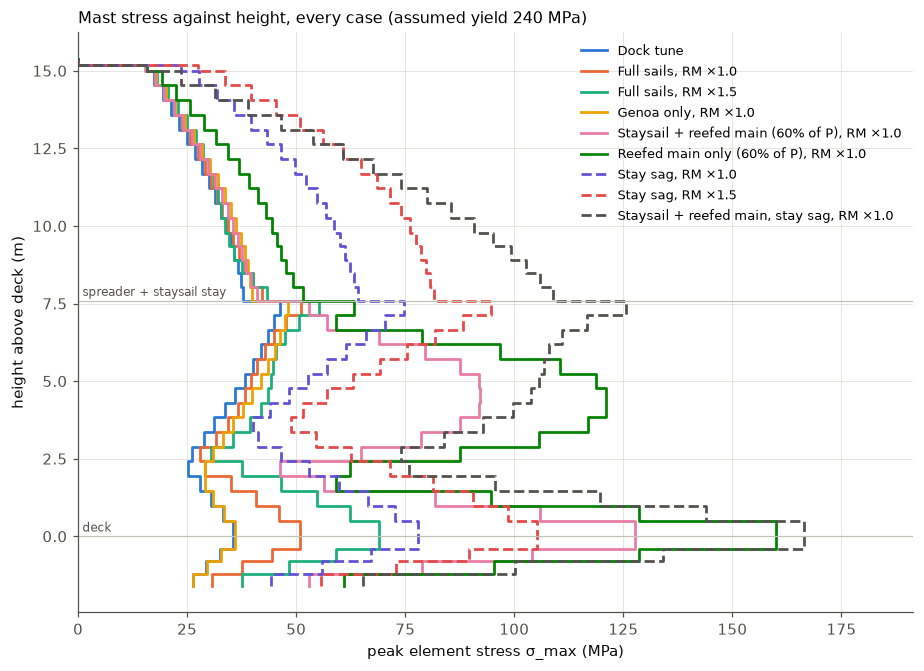

In [22]:
CASE_COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948", "#52514e"]
assert len(STRESS) <= len(CASE_COLOURS), "add a colour"
fig, ax = plt.subplots(figsize=(8.5, 6.2))
for (label, d), colr in zip(STRESS.items(), CASE_COLOURS):
    geo = d["geo"]
    zs, sg = [], []
    for b in geo["beams"]:
        if b["kind"] != "mast":
            continue
        za, zb = geo["nodes"][b["i"]][2], geo["nodes"][b["j"]][2]
        zs += [za, zb]; sg += [d["s"][b["name"]][0] / 1e6] * 2            # constant over each element
    ax.plot(sg, zs, color=colr, lw=1.8, ls="--" if d["solver"].startswith("OpenSees") else "-", label=label)
level_lines(ax, 1)
ax.set_xlabel("peak element stress σ_max (MPa)"); ax.set_ylabel("height above deck (m)")
ax.set_xlim(0, max(STRESS_TBL["mast σ max (MPa)"]) * 1.15)
ax.set_title(f"Mast stress against height, every case (assumed yield {params.sigma_y_al/1e6:.0f} MPa)",
             loc="left", fontsize=10.5)
ax.legend(frameon=False, fontsize=8.5, loc="upper right")
plt.tight_layout(); plt.show()

### What the stresses show (placeholder section, geometry and loads)

- **At the dock the peak is 46 MPa (19%), at the spreader root.** Half of it is compression (74 kN on
  3,211 mm² is 23 MPa). The rest is 4.0 kN·m of fore-and-aft bending: the pre-bend that the staysail
  stay pulls in.
- **Full sails stay modest: 51 MPa (21%), still at the spreader root,** and 69 MPa (29%) at RM ×1.5.
- **Any case that brings the whole moment in low loads the partners hard.** Reefed main only reaches
  160 MPa (67% of the assumed yield) with 18.4 kN·m of athwart bending at the partners. The lower panel is
  7.6 m long, with nothing between the deck and the spreader to share the load.
- **The governing case for the mast is the cutter's heavy-weather rig with the staysail's load on its
  stay: 166 MPa, 69%.** The partners carry 15.6 kN·m fore-and-aft and 14.3 kN·m athwart at once,
  because the staysail stay pulls the middle of the mast 133 mm forward while the reefed main pushes it
  sideways.
- **Stay sag with full sails** adds compression (105 kN at ×1.0, 122 kN at ×1.5) and peaks at 78 and
  105 MPa.
- **Spreaders stay below about 27%** on the placeholder airfoil.
- **Check 12:** Pynite and OpenSees agree on the full-sail peak to 0.3%.
- **Treat these as relative, not absolute.** The section is a placeholder and the yield is assumed. The
  pattern holds whatever the section, though: the partners in the reefed cases, and the staysail stay's
  forward pull.

### What the cases show (default placeholders)

- **The heavy-weather cutter rig, run with stay sag, is the governing case of the whole study.** With the
  staysail's 8.6 kN along its stay, the staysail stay rises from 4.7 to 18.6 kN (SF 2.5). Its forward
  pull bows the mast 133 mm forward at the tang. The windward aft lower reaches 27.5 kN, 58% of MBL,
  **SF 1.71, the lowest in the study,** and its chainplate is pulled up with 26.6 kN.
- **Why the aft lowers can't hold the tang.** They lead only 0.10 of their tension aft. Of the stay's
  8.5 kN forward pull at the tang, they answer about 3 kN, while carrying 27.5 kN along their length. The
  mast's bending carries the rest, which is where the 15.6 kN·m at the partners comes from. Running
  backstays or check stays are the usual answer on a cutter; IP Home Port lists neither for the IP40. This
  result rests on two placeholders, the tang height and the aft-lower chainplate position, so measure
  those first.
- **The same case with the load lumped at the tang** (Pynite row) shows the staysail stay at 4.6 kN and
  misses all of this. Run headsail loads along their stays.
- **With full sails, sag doubles the forestay** from 12.9 to 28.5 kN (rigid-end bound 31.9), raises the
  staysail stay from 4.7 to 7.5 kN, adds 38% to the mast's compression (76 to 105 kN), and pulls the
  masthead 46 mm forward. At RM ×1.5 the forestay governs (35.6 kN, SF 1.8). The forestay's size isn't
  published; it's assumed equal to the caps.
- **Pynite's own stay-sag row is the warning again.** It leaves the forestay at its dock tension and lets
  it sag 1.2 m. Use the corotational rows for any loaded stay.
- **Reefed main only** loads the windward aft lower to 18.3 kN (SF 2.6) and the mast to 67% at the partners.
- **Genoa only** puts everything on the caps: 24.5 kN, SF 2.6.
- **RM ×1.5** drops the minimum SF to 2.50 (the aft lower), and both leeward lowers go slack.

---
## §11 Interactive explorer

The sliders rerun the whole Pynite pipeline (tune, then the RM case) and redraw the tension plot. Each
move takes several seconds, because the tune is a five-unknown Newton solve. Widgets work in VS Code and
classic Jupyter; in a PDF export this cell shows only its last state.

In [23]:
try:
    import ipywidgets as W

    out = W.Output()

    def rerun(spreader_len, stay_frac, cap_pct, aft_lower_pct, gz30, sail_plan):
        p = replace(params, spreader_len=spreader_len, staysail_z_frac=stay_frac, GZ30=gz30, sail_plan=sail_plan,
                    pretension_pct={**params.pretension_pct, "cap": cap_pct, "lowerA": aft_lower_pct})
        with out:
            out.clear_output(wait=True)
            g = rig_geometry(p)
            if (wire_bend_check(g)["deflection outboard (mm)"] <= 0).any():
                print("The spreader tip falls inside the cap's line. Lengthen the spreader.")
                return
            d, _, _ = tune(p, g, MAST)
            ld, info = rm_loads(p, g)
            m = solve_pynite(p, g, MAST, d, ld)
            res = {c: pynite_results(m, g, c) for c in ("Dock", "RM")}
            tt = tension_table(res["Dock"], res["RM"], g, p)
            lam, _ = buckling_factor(m, "RM", 1)
            sm = max(beam_stresses_pynite(m, g, "RM").items(), key=lambda kv: kv[1][0])
            print(f"RM30 = {p.RM30/1e3:.1f} kN*m   min SF = {tt['SF (RM)'].min():.2f} ({tt['SF (RM)'].idxmin()})   "
                  f"slack: {', '.join(tt.index[tt['slack in RM case'] == 'SLACK']) or 'none'}   λ = {lam[0]:.2f}   "
                  f"peak spar stress {sm[1][0]/1e6:.0f} MPa ({sm[0]})")
            plot_tensions(tt)

    ui = W.interactive(rerun, {"manual": True, "manual_name": "Run"},
                       spreader_len=W.FloatSlider(value=params.spreader_len, min=1.0, max=2.0, step=0.05, description="spreader (m)"),
                       stay_frac=W.FloatSlider(value=params.staysail_z_frac, min=0.45, max=0.85, step=0.05, description="stay tang / I"),
                       cap_pct=W.FloatSlider(value=params.pretension_pct["cap"], min=5, max=30, step=1, description="cap % MBL"),
                       aft_lower_pct=W.FloatSlider(value=params.pretension_pct["lowerA"], min=5, max=30, step=1, description="aft lower %"),
                       gz30=W.FloatSlider(value=params.GZ30, min=0.3, max=1.2, step=0.05, description="GZ30 (m)"),
                       sail_plan=W.Dropdown(options=["full", "headsail_only", "staysail_reefed_main", "reefed_main_only", "main_only"],
                                            value=params.sail_plan, description="sail plan"))
    display(W.VBox([ui, out]))
except ImportError:
    print("ipywidgets not available; edit RigParams in §0 instead")

---
## Placeholders to replace, roughly in order of how much they move the answer

1. **$GZ_{30}$** (that is, $RM_{30}$). Every sailing-case load scales with it. Look for the boat's
   stability data from Island Packet, a surveyor's inclining test, or an IP owners' archive.
2. **The staysail stay's tang height and tack position** (`staysail_z_frac`, `staysail_tack_x`). They set
   how hard the staysail stay pulls the mast forward, and whether the aft lowers can answer it.
3. **The mast section.** Chord, width and wall, or the maker's section number for `mast_override`.
4. **Chainplate positions** (`chainplate`, `backstay_foot`), especially the aft lowers' fore-and-aft
   offset: their small lever is what limits the fore-and-aft support at the spreader root.
5. **Spreader height and length.**
6. **Forestay and staysail-stay wire sizes**, which IP Home Port doesn't list, and the MBL from each
   wire's certificate. The 5/16 in MBL rests on one catalog.
7. **Heel depth and boom height.**

---
## §12 Checks

Each check has a stated tolerance and the reason for it. The last cell raises if any check fails,
so a headless run fails loudly.

In [24]:
CHECKS = []


def check(name, value, ref, rel_tol, why, skip=False):
    if skip:
        CHECKS.append({"check": name, "value": np.nan, "reference": np.nan, "rel err": np.nan, "tol": rel_tol,
                       "result": "SKIP", "why tolerance": why}); return
    err = abs(value - ref) / max(abs(ref), 1e-30)
    CHECKS.append({"check": name, "value": value, "reference": ref, "rel err": err, "tol": rel_tol,
                   "result": "PASS" if err <= rel_tol else "FAIL", "why tolerance": why})


# 1. sectionproperties closed ellipse vs closed form pi/4 (a b^3 - ai bi^3), semi-axes
a, b, t = params.mast_chord / 2, params.mast_width / 2, params.mast_wall
cf_fa = math.pi / 4 * (b * a**3 - (b - t) * (a - t)**3) * 1e-12
cf_ath = math.pi / 4 * (a * b**3 - (a - t) * (b - t)**3) * 1e-12
check("1a sectionproperties closed tube I_fa", SEC["closed"]["I_fa"], cf_fa, 2e-3,
      "128-sided polygon under-fills the ellipse by ~cos(pi/128) on area; 0.2% covers it")
check("1b sectionproperties closed tube I_ath", SEC["closed"]["I_ath"], cf_ath, 2e-3, "same polygon error")

# 2. cantilever tip deflection PL^3/3EI on the mast section, Pynite (and OpenSees below)
Lc, Pc = 10.0, 1000.0
mc = FEModel3D(); mc.add_material("Al", params.E_al, params.G_al, 0.33, 2700)
mc.add_section("mast", MAST["A"], MAST["I_ath"], MAST["I_fa"], MAST["J"])
mc.add_node("a", 0, 0, 0); mc.add_node("b", 0, Lc, 0)
mc.add_member("c", "a", "b", "Al", "mast"); mc.def_support("a", *[True] * 6)
mc.add_node_load("b", "FX", Pc, "L"); mc.add_load_combo("C", {"L": 1}); mc.analyze()
check("2a Pynite cantilever tip, fore-and-aft", mc.nodes["b"].DX["C"], Pc * Lc**3 / (3 * params.E_al * MAST["I_fa"]), 1e-9,
      "Euler-Bernoulli element is exact for a tip load")

# 3. pinned column buckling from K, Kg vs pi^2 EI/L^2
mb = FEModel3D(); mb.add_material("Al", params.E_al, params.G_al, 0.33, 2700)
mb.add_section("mast", MAST["A"], MAST["I_ath"], MAST["I_fa"], MAST["J"])
nel = 20
for k in range(nel + 1):
    mb.add_node(f"n{k}", 0, Lc * k / nel, 0)
for k in range(nel):
    mb.add_member(f"e{k}", f"n{k}", f"n{k+1}", "Al", "mast")
mb.def_support("n0", True, True, True, False, True, False)        # pinned; twist (RY) held
mb.def_support(f"n{nel}", True, False, True, False, False, False)
mb.add_node_load(f"n{nel}", "FY", -1000.0, "L"); mb.add_load_combo("C", {"L": 1}); mb.analyze()
lam_b, phi_b = buckling_factor(mb, "C", 6)
kb = next(k for k in range(len(lam_b)) if max(np.hypot(phi_b[i * 6, k], phi_b[i * 6 + 2, k]) for i in range(nel + 1))
          >= max(abs(phi_b[i * 6 + 4, k]) for i in range(nel + 1)) * r_tw)
check("3  Pynite K/Kg pinned column vs Euler (first flexural mode)", lam_b[kb] * 1000.0, math.pi**2 * params.E_al * MAST["I_ath"] / Lc**2, 2e-3,
      "20 cubic elements: discretisation error ~1e-5; 0.2% leaves margin")

# 4. symmetric two-shroud lack of fit vs hand statics: mast fixed at the base (symmetry keeps it straight), two shrouds to the head
hL, yL, dl = 10.0, 1.5, 2e-3
wp = wire_props("5/16 in"); L4 = math.hypot(hL, yL); c4 = hL / L4
ms = FEModel3D(); ms.add_material("Al", params.E_al, params.G_al, 0.33, 2700); ms.add_material("W", params.E_wire, 40e9, 0.3, 7950)
ms.add_section("mast", MAST["A"], MAST["I_ath"], MAST["I_fa"], MAST["J"]); ms.add_section("w", wp["A"], 1e-12, 1e-12, 1e-12)
ms.add_node("base", 0, 0, 0); ms.add_node("head", 0, hL, 0); ms.add_node("cp", 0, 0, yL); ms.add_node("cs", 0, 0, -yL)
ms.add_member("mast", "base", "head", "Al", "mast"); ms.def_support("base", *[True] * 6)
for nm, cp in (("wp", "cp"), ("ws", "cs")):
    ms.add_member(nm, cp, "head", "W", "w", tension_only=True)
    ms.def_releases(nm, Ryi=True, Rzi=True, Rxj=True, Ryj=True, Rzj=True); ms.def_support(cp, *[True] * 6)
    u4 = unit((ms.nodes[cp].X, ms.nodes[cp].Y, ms.nodes[cp].Z), (0, hL, 0))
    for comp, val in zip(("DX", "DY", "DZ"), -dl * u4):
        if abs(val) > 0:
            ms.def_node_disp(cp, comp, float(val))
ms.add_load_combo("C", {}); ms.analyze(check_stability=False)
# compatibility: each wire stretch = dl - mast shortening * c ; mast force = 2 T c ; T = k_w (dl - c * 2 T c / k_m)
k_w, k_m = wp["A"] * params.E_wire / L4, MAST["A"] * params.E_al / hL
T_hand = k_w * dl / (1 + 2 * c4**2 * k_w / k_m)
check("4  lack-of-fit pretension vs hand", -ms.members["wp"].axial(1.0, "C"), T_hand, 1e-6,
      "linear statics with one compatibility equation; exact to solver precision")


# 5. global equilibrium of the rig, both cases (reactions + applied = 0)
def resultant(res, loads):
    F = sum(res["rxn"].values())
    for v in loads.values():
        F = F + np.asarray(v)
    return F


for label, res_, tol_, why_ in (("linear", RES_LIN, 1e-9, "linear statics: rounding only"),
                                ("P-Delta", RES, 2e-3, "Pynite's two-cycle P-Delta is not iterated to convergence; see §5")):
    for c, ld in (("Dock", {}), ("RM", LOADS)):
        R = resultant(res_[c], ld)
        scale = LINFO["F_main"] + LINFO["head_share_on_rig"] if c == "RM" else max(T_TARGET.values())
        resid = np.linalg.norm(R[:3]) / scale          # a ratio to zero, so judged as an absolute error
        CHECKS.append({"check": f"5  equilibrium {c}, {label}: |ΣF| / load scale", "value": resid, "reference": 0.0,
                       "rel err": resid, "tol": tol_, "result": "PASS" if resid <= tol_ else "FAIL",
                       "why tolerance": why_})

# 6. heeling moment carried by the supports = k*RM30  (moment of reactions about the boat x-axis at the deck)
Mx = {c: sum(r[3] + (GEO["nodes"][n][1] * r[2] - GEO["nodes"][n][2] * r[1]) for n, r in RES_LIN[c]["rxn"].items())
      for c in ("Dock", "RM")}
check("6  support moment about deck x-axis = k RM30 (linear solve)", -(Mx["RM"] - Mx["Dock"]), LINFO["M_target"], 1e-9,
      "statics of the load generator: the tack shares act at deck level, so the rig carries all of k RM30")

# 7. dock tune hits its targets
for g in TUNED:
    check(f"7  dock tune: {TARGET_OF[g]} via {g} turnbuckle", T_TUNED[g], T_TARGET[g], 1e-3, "Newton stops at |error| < 1 N")

# 8. Pynite P-Delta vs OpenSees corotational
skip = OPS is None
key_w = ["cap_V1_P", "cap_V2_P", "lowerF_D1F_P", "lowerA_D1A_P", "backstay_P", "forestay", "staysail_stay"]
for nm in key_w:
    tol8, why8 = (0.025, "the mast's dock bow shortens its chord (§9), which linear-strain P-Delta omits; "
                         "that is ~2% of the forestay's stretch") if nm == "forestay" else \
                 (0.01, "two-cycle P-Delta vs exact kinematics; 1% on a loaded wire")
    check(f"8  RM tension {nm}: Pynite vs OpenSees corotational", RES["RM"]["T"][nm],
          np.nan if skip else OPS["Corotational"]["RM"]["T"][nm], tol8, why8, skip)
check("8  RM masthead athwart: Pynite vs OpenSees corotational", RES["RM"]["disp"][head][1],
      np.nan if skip else OPS["Corotational"]["RM"]["disp"][head][1], 0.02,
      "displacement is the most sensitive output; 2%", skip)
check("8  dock max mast compression: Pynite vs OpenSees corotational", Nmax["Dock"],
      np.nan if skip else max(OPS["Corotational"]["Dock"]["mast_N"].values()), 0.01,
      "pretension by enforced support motion (Pynite) vs initial strain (OpenSees)", skip)

# 2b. the same cantilever in OpenSees
cant = None
if OPS_PY.exists():
    cant = run_opensees({"nodes": {"a": (0, 0, 0), "b": (0, Lc, 0)}, "fix": {"a": [1] * 6}, "wires": [],
                         "beams": [{"i": "a", "j": "b", "kind": "mast", "A": MAST["A"], "E": params.E_al, "G": params.G_al,
                                    "J": MAST["J"], "Iy": MAST["I_ath"], "Iz": MAST["I_fa"], "vecxz": (0.0, 0.0, 1.0)}],
                         "loads": {"b": [Pc, 0, 0, 0, 0, 0]}, "transfs": ["PDelta"], "nsteps": 1})
check("2b OpenSees cantilever tip, fore-and-aft", np.nan if cant is None else cant["PDelta"]["RM"]["disp"]["b"][0],
      Pc * Lc**3 / (3 * params.E_al * MAST["I_fa"]), 1e-9, "exact element; also confirms Iz = I_fa in OpenSees",
      cant is None)

# 9. cable equation (rigid ends) vs OpenSees corotational on a single pretensioned cable with the sag-case genoa load
Lc9, T09, n9 = L_STAY["forestay"], SAG1["T0"]["forestay"], 40
F9 = SAG1["info"]["F_genoa"]
fs_wp = WP_STAY["forestay"]
cab = None
if OPS_PY.exists():
    nodes9 = {f"c{k:02d}": (Lc9 * k / n9, 0.0, 0.0) for k in range(n9 + 1)}
    fix9 = {nm: ([1] * 6 if k in (0, n9) else [0, 0, 0, 1, 1, 1]) for k, nm in enumerate(nodes9)}
    w9 = lambda s: 2 * F9 / Lc9 * (1 - s / Lc9)
    loads9 = {nm: [0.0] * 6 for nm in nodes9}
    for k in range(n9):
        sa, sb = Lc9 * k / n9, Lc9 * (k + 1) / n9
        loads9[f"c{k:02d}"][2] += (sb - sa) * (2 * w9(sa) + w9(sb)) / 6
        loads9[f"c{k+1:02d}"][2] += (sb - sa) * (w9(sa) + 2 * w9(sb)) / 6
    cab = run_opensees({"nodes": nodes9, "fix": fix9, "beams": [], "transfs": ["Corotational"], "nsteps": 20,
                        "wires": [{"name": f"s{k:02d}", "i": f"c{k:02d}", "j": f"c{k+1:02d}", "A": fs_wp["A"],
                                   "E": params.E_wire, "eps0": T09 / (fs_wp["A"] * params.E_wire)} for k in range(n9)],
                        "loads": {k_: v for k_, v in loads9.items() if any(v)}})
T9_hand = cable_T_fixed_ends(T09, Lc9, fs_wp["A"] * params.E_wire, lambda s: 2 * F9 / Lc9 * (1 - s / Lc9))
check("9  cable equation vs OpenSees corotational, rigid-end forestay", np.nan if cab is None else
      max(cab["Corotational"]["RM"]["T"].values()), T9_hand, 0.01,
      "small-sag theory and 40 segments; tension also varies slightly along the cable", cab is None)

# 10. the sag-case loads carry the same heeling moment about the deck as the lumped case
ld10, inf10 = SAG1["loads"], SAG1["info"]
M10 = sum(GEO_FS["nodes"][n][2] * -v[1] - GEO_FS["nodes"][n][1] * v[2] for n, v in ld10.items()) + sum(v[3] for v in ld10.values())
check("10 stay-sag loads: moment about deck = k RM30", M10, inf10["M_target"], 1e-9,
      "a linear luff load on straight segments: the truss-consistent nodal forces reproduce its moment exactly")

# 11. St-Venant J of the closed tube against Bredt's thin-wall formula J = 4 A_m^2 / (closed integral of ds / t).
# The bore is the ellipse (a - t, b - t), which is not a parallel offset: the wall thins on the shoulders. So t(s) is
# measured along the midline's normal, from the bore to the outside, at each of 20,000 points.
am, bm = a - t / 2, b - t / 2
th11 = np.linspace(0, 2 * np.pi, 20001)[:-1]
mx, my = am * np.cos(th11), bm * np.sin(th11)
nx, ny = mx / am**2, my / bm**2; nn = np.hypot(nx, ny); nx, ny = nx / nn, ny / nn


def _near_root(A, B):
    """Distance along the midline normal to the ellipse (A, B): the root nearest the midline."""
    qa = (nx / A)**2 + (ny / B)**2; qb = 2 * (mx * nx / A**2 + my * ny / B**2); qc = (mx / A)**2 + (my / B)**2 - 1
    r = np.sqrt(qb**2 - 4 * qa * qc); l1, l2 = (-qb + r) / (2 * qa), (-qb - r) / (2 * qa)
    return np.where(np.abs(l1) < np.abs(l2), l1, l2)


t_s = _near_root(a, b) - _near_root(a - t, b - t)
ds11 = np.hypot(-am * np.sin(th11), bm * np.cos(th11)) * (2 * np.pi / len(th11))
J_bredt = 4 * (math.pi * am * bm)**2 / np.sum(ds11 / t_s) * 1e-12
check("11 sectionproperties J vs Bredt thin-wall, real wall t(s) (closed tube)", SEC["closed"]["J"], J_bredt, 1e-3,
      f"wall runs {t_s.min():.2f}–{t_s.max():.2f} mm; thin-wall theory drops O((t/b)^2) terms; a uniform-t Bredt "
      f"would be {4*(math.pi*am*bm)**2*t/np.sum(ds11)*1e-12/SEC['closed']['J']-1:+.1%} off")

# 12. peak mast stress, full sails x1.0: Pynite P-Delta against OpenSees corotational (independent moments)
if OPS is not None and OPS["Corotational"]["RM"].get("lf"):
    s_ops = beam_stresses_ops(OPS["Corotational"]["RM"], GEO)
    s_py = STRESS["Full sails, RM ×1.0"]["s"]
    mk_ = [b["name"] for b in GEO["beams"] if b["kind"] == "mast"]
    check("12 peak mast stress, full sails: Pynite vs OpenSees corotational", max(s_py[n][0] for n in mk_),
          max(s_ops[n][0] for n in mk_), 0.03, "tensions agree within 1%; moments are more sensitive, so 3%")
else:
    check("12 peak mast stress, full sails: Pynite vs OpenSees corotational", np.nan, np.nan, 0.03, "", True)
Pf, Pa, Lc_ = 1000.0, 500.0, 10.0           # the stress formula itself: a cantilever with tip loads both ways, at the root
check("12 section_stress formula vs hand, cantilever root", section_stress(0.0, Pf * Lc_, Pa * Lc_, "mast"),
      math.hypot(Pf * Lc_ * params.mast_chord / 2e3 / MAST["I_fa"], Pa * Lc_ * params.mast_width / 2e3 / MAST["I_ath"]),
      1e-12, "same algebra, written out by hand")

CHK = pd.DataFrame(CHECKS).set_index("check")
display(CHK.style.format({"value": "{:.6g}", "reference": "{:.6g}", "rel err": "{:.2e}", "tol": "{:.2g}"}))

,value,reference,rel err,tol,result,why tolerance
check,,,,,,
1a sectionproperties closed tube I_fa,2.21802e-05,2.2198e-05,8.03e-04,0.002,PASS,128-sided polygon under-fills the ellipse by ~cos(pi/128) on area; 0.2% covers it
1b sectionproperties closed tube I_ath,1.13975e-05,1.14066e-05,8.03e-04,0.002,PASS,same polygon error
"2a Pynite cantilever tip, fore-and-aft",0.214692,0.214692,3.88e-16,1e-09,PASS,Euler-Bernoulli element is exact for a tip load
3 Pynite K/Kg pinned column vs Euler (first flexural mode),78742.1,78742.1,8.44e-07,0.002,PASS,20 cubic elements: discretisation error ~1e-5; 0.2% leaves margin
4 lack-of-fit pretension vs hand,1006.06,1006.06,3.39e-16,1e-06,PASS,linear statics with one compatibility equation; exact to solver precision
"5 equilibrium Dock, linear: |ΣF| / load scale",4.67287e-12,0,4.67e-12,1e-09,PASS,linear statics: rounding only
"5 equilibrium RM, linear: |ΣF| / load scale",8.42565e-12,0,8.43e-12,1e-09,PASS,linear statics: rounding only
"5 equilibrium Dock, P-Delta: |ΣF| / load scale",9.4634e-05,0,9.46e-05,0.002,PASS,Pynite's two-cycle P-Delta is not iterated to convergence; see §5
"5 equilibrium RM, P-Delta: |ΣF| / load scale",0.000361449,0,3.61e-04,0.002,PASS,Pynite's two-cycle P-Delta is not iterated to convergence; see §5


### Information only: large-displacement effect and leeward slack

In [25]:
if OPS is not None:
    info = pd.DataFrame({nm: {"PDelta (kN)": OPS["PDelta"]["RM"]["T"][nm] / 1e3,
                              "corotational (kN)": OPS["Corotational"]["RM"]["T"][nm] / 1e3,
                              "corot − PDelta (%)": 100 * (OPS["Corotational"]["RM"]["T"][nm] / max(OPS["PDelta"]["RM"]["T"][nm], 1e-9) - 1)}
                         for nm in key_w}).T
    display(info.style.format("{:.2f}"))
    print(f"masthead athwart: PDelta {OPS['PDelta']['RM']['disp'][head][1]*1e3:+.1f} mm, "
          f"corotational {OPS['Corotational']['RM']['disp'][head][1]*1e3:+.1f} mm")
print("slack leeward wires in the RM case:", ", ".join(TT.index[TT["slack in RM case"] == "SLACK"]) or "none")

,PDelta (kN),corotational (kN),corot − PDelta (%)
cap_V1_P,19.69,19.23,-2.35
cap_V2_P,20.07,19.59,-2.36
lowerF_D1F_P,11.17,11.14,-0.26
lowerA_D1A_P,13.59,13.55,-0.26
backstay_P,7.52,7.34,-2.40
forestay,13.15,12.65,-3.85
staysail_stay,4.48,4.46,-0.50


masthead athwart: PDelta -102.5 mm, corotational -102.5 mm
slack leeward wires in the RM case: lowerF_D1F_S


In [26]:
n_fail = (CHK["result"] == "FAIL").sum(); n_pass = (CHK["result"] == "PASS").sum(); n_skip = (CHK["result"] == "SKIP").sum()
print(f"{n_pass} PASS, {n_fail} FAIL, {n_skip} SKIP")
assert n_fail == 0, CHK[CHK["result"] == "FAIL"]
print("ALL CHECKS OK")

30 PASS, 0 FAIL, 0 SKIP
ALL CHECKS OK


---
## §13 Report

This cell writes **`output/island-packet-40-1996/REPORT.md`**, and one four-panel
figure per load case to `output/island-packet-40-1996/assets/rig-ip40-case-*.svg`, which the report embeds: the deflected rig from astern
and from port coloured by utilisation with the sail loads drawn on, mast stress against height, and every
wire's % of MBL. The report breaks every load case down item by item, all from the results above. It overwrites the file each run; set `WRITE_REPORT = False`
to skip it. Treat the file as generated output and don't hand-edit it.

The report opens with a **rigging list**, written by the cell below: every wire with its quantity, size, model length, breaking load and the highest load any case puts on it, plus totals by wire size and what to check before ordering.

In [27]:
# ---- Rigging list for §13's report: every wire as it would be ordered ----------------------------------------
RIG_LABEL = {"forestay": ("Forestay (inside the genoa furler)", "bowsprit end to masthead"),
             "staysail_stay": ("Staysail stay (inner forestay)", "foredeck to its tang"),
             "backstay": ("Backstay legs (twin)", "transom quarter to the masthead"),
             "cap": ("Caps (uppers)", "chainplate, over the spreader tip, to the masthead (one wire)"),
             "lowerF": ("Forward lowers", "chainplate to the spreader root"),
             "lowerA": ("Aft lowers", "chainplate to the spreader root")}                   # group -> (name, where it runs), in the order the list shows them
RIG_PUBLISHED = {"cap", "lowerF", "lowerA", "backstay"}           # groups whose wire size is published rather than a placeholder
RIG_NOTE = ("The cap, lower and backstay sizes are IP Home Port's published figures. The forestay and staysail-stay sizes, "
            "and all the geometry behind the lengths, are placeholders.")


def rigging_list_rows():
    """One row per wire type. Lengths come from the first geometry that has the group (the base rig first), so wires
    that only a variant has (split backstays) still appear. Loads are the largest over every case, on either side."""
    geos = list({id(g): g for g in [GEO] + [d["geo"] for d in STRESS.values()]}.values())
    pieces = {}
    for geo in geos:
        for w in geo["wires"]:
            p_ = pieces.setdefault(w["group"], {"geo": geo, "length": {}, "sides": set()})
            if p_["geo"] is geo:
                p_["sides"].add(w["side"])
                p_["length"][w["side"]] = p_["length"].get(w["side"], 0.0) + seg_len(geo, w)
    rows = []
    for g in list(RIG_LABEL) + [g for g in pieces if g not in RIG_LABEL]:
        if g not in pieces:
            continue
        p_ = pieces[g]
        size = params.wire[g]
        peak, peak_case, dock = 0.0, "", None
        for label, d in STRESS.items():
            for name, t in d["T"].items():
                if GROUP_OF.get(name) == g and t > peak:
                    peak, peak_case = t, label
            if dock is None and label.endswith("Dock tune") and d["geo"] is p_["geo"]:
                dock = max(t for name, t in d["T"].items() if GROUP_OF.get(name) == g)
        rows.append({"group": g, "qty": 1 if "C" in p_["sides"] else len(p_["sides"]), "size": size,
                     "d_mm": float(WIRE.loc[size, "d_mm"]), "n_sources": int(WIRE.loc[size, "n_sources"]),
                     "length": max(p_["length"].values()), "mbl": wire_props(size)["MBL"],
                     "mbl_lbf": float(WIRE.loc[size, "MBL_design_lbf"]), "dock": dock, "peak": peak,
                     "case": peak_case.replace(" (60% of P)", ""), "base": p_["geo"] is GEO})
    return rows


def rigging_list_md():
    """The report's rigging list: a table per rig, totals by wire size, and what to check before ordering."""
    ft_in = lambda m: f"{round(m / 0.0254) // 12} ft {round(m / 0.0254) % 12} in"
    head = ["| Item and where it runs | Qty | Wire, 1x19 316 | Length, centre to centre (each) | Design MBL | Dock tune | "
            "Highest load in any case | Size |", "| --- | ---: | --- | --- | --- | --- | --- | --- |"]

    def line(r):
        name, run = RIG_LABEL.get(r["group"], (r["group"], ""))
        dock = "—" if r["dock"] is None else f"{r['dock']/1e3:.1f} kN ({100 * r['dock'] / r['mbl']:.0f}%)"
        return (f"| **{name}**: {run} | {r['qty']} | {r['size']} ({r['d_mm']:.1f} mm) | {r['length']:.2f} m ({ft_in(r['length'])}) | "
                f"{r['mbl']/1e3:.1f} kN ({r['mbl_lbf']:,.0f} lbf) | {dock} | {r['peak']/1e3:.1f} kN, SF {r['mbl'] / r['peak']:.1f} "
                f"({r['case']}) | {'published' if r['group'] in RIG_PUBLISHED else 'placeholder'} |")

    rows = rigging_list_rows()
    base, variant = [r for r in rows if r["base"]], [r for r in rows if not r["base"]]
    tot = {}
    for r in base:
        t = tot.setdefault(r["size"], {"pieces": 0, "len": 0.0, "d_mm": r["d_mm"], "n": r["n_sources"]})
        t["pieces"] += r["qty"]; t["len"] += r["qty"] * r["length"]
    out = ["## Rigging list", "",
           "Every piece of standing rigging in the model, laid out the way a rigging order is: what it is, how many, the wire "
           "and its length, with the breaking load and the highest load any case below puts on it. " + RIG_NOTE, ""]
    out += head + [line(r) for r in base]
    out += ["", "**Wire totals by size** (the pieces above, centre-to-centre lengths, before any allowance for terminals):", "",
            "| Wire | Pieces | Total length | MBL sources in the wire table |", "| --- | ---: | --- | ---: |"]
    out += [f"| {s} ({t['d_mm']:.1f} mm) 1x19 316 | {t['pieces']} | {t['len']:.1f} m ({t['len'] / 0.3048:.0f} ft) | {t['n']} |"
            for s, t in sorted(tot.items(), key=lambda kv: -kv[1]["d_mm"])]
    if variant:
        out += ["", "**Wires only the variant rig has** (split backstays: these are added, and the triatic dropped):", ""]
        out += head + [line(r) for r in variant]
    out += ["", "**Before ordering from this list:**", "",
            "- **The lengths are not cut lengths.** Each is measured in the model from the mast's centreline at the attachment "
            "height to the chainplate pin at deck level, along the wire. A real wire is made to its pin-to-pin length, tang to "
            "chainplate, with the turnbuckle and toggles at their working setting; tangs sit off the centreline and chainplate "
            "pins above the deck, so the real length differs by several centimetres even where the geometry is right.",
            "- **Measure the old wire,** pin to pin with its turnbuckle at the tuned setting, or have a rigger measure the spar "
            "and chainplates. Use this list for the sizes, the quantities and the loads to check fittings against.",
            "- **Terminals, toggles and turnbuckles aren't in the model.** Match them to the wire, and check that each fitting's "
            "rated load is at least the wire's MBL.",
            "- **MBL is the lowest of the catalogs in the wire table;** the totals table says how many catalogs each size rests "
            "on. Use the figure on the new wire's certificate.",
            "- **The highest load** is the largest tension any case in this report puts on that wire, at the placeholder GZ30. "
            "Port and starboard wires are the same length and see the same loads on opposite tacks.", ""]
    return out


In [28]:
WRITE_REPORT = True
REPORT_PATH = OUT / "REPORT.md"


def md_table(rows, cols, fmt=None, align=None):
    """rows: list of dicts. fmt: {col: format string or callable}. Right-aligns numbers."""
    fmt = fmt or {}
    def cell(r, c):
        v = r.get(c, "")
        f = fmt.get(c)
        if v is None or (isinstance(v, float) and not np.isfinite(v)):
            return "—"
        if callable(f):
            return f(v)
        return format(v, f) if f else str(v)
    al = [(align or {}).get(c, "r" if isinstance(rows[0].get(c), (int, float, np.floating)) else "l") for c in cols]
    head_ = "| " + " | ".join(cols) + " |"
    rule = "| " + " | ".join("---:" if a == "r" else "---" for a in al) + " |"
    body = ["| " + " | ".join(cell(r, c) for c in cols) + " |" for r in rows]
    return "\n".join([head_, rule] + body)


PANELS = [("heel to deck", -99.0, 0.0), ("deck to spreader", 0.0, GEO["z"]["s1"]),
          ("spreader to masthead", GEO["z"]["s1"], GEO["z"]["head"] + 1e-6)]
WIRE_LABEL = {"cap_V1": "cap V1 (chainplate to spreader tip)", "cap_V2": "cap V2 (spreader tip to masthead)",
              "lowerF_D1F": "forward lower (chainplate to spreader root)", "lowerA_D1A": "aft lower (chainplate to spreader root)",
              "backstay": "backstay leg", "forestay": "forestay (bowsprit to masthead)",
              "staysail_stay": "staysail stay (foredeck to tang)"}


def wire_label(name):
    base, side = (name[:-2], name[-1]) if name[-2] == "_" and name[-1] in "PS" else (name, "")
    lab = WIRE_LABEL.get(base, base)
    return f"{lab}, {'port (windward)' if side == 'P' else 'starboard (leeward)' if side == 'S' else ''}".rstrip(", ")


FIG_DIR = OUT / "assets"
FIG_DIR.mkdir(parents=True, exist_ok=True)
UTIL_CMAP = mcolors.LinearSegmentedColormap.from_list(
    "util", ["#f3c7a9", "#efa47a", "#eb7f4c", "#e0602a", "#c24a1a", "#962f0c", "#651c05"])
UTIL_MAX = 0.5                       # colour scale 0..50 % utilisation, shared by every case and every member
C_LOADS = "#2a78d6"                  # applied loads (kept off the warm utilisation ramp)
DISP_SCALE = 5.0                     # deflections drawn x5 in every case figure
SHORT = {"cap V1 (chainplate to spreader tip)": "cap V1", "cap V2 (spreader tip to masthead)": "cap V2",
         "forward lower (chainplate to spreader root)": "fwd lower", "aft lower (chainplate to spreader root)": "aft lower",
         "forestay (bowsprit to masthead)": "forestay", "staysail stay (foredeck to tang)": "staysail stay",
         "port (windward)": "wwd", "starboard (leeward)": "lwd"}


def case_figure(label, d, path):
    """Four panels for one load case: views from astern and from port (deflected, coloured by utilisation,
    loads as arrows), mast stress against height, and every wire's % MBL."""
    geo, p_, res, loads = d["geo"], d["p"], d["res"], d["loads"]
    n_, disp = geo["nodes"], res["disp"]
    P = lambda nm, sc: np.add(n_[nm], sc * np.asarray(disp[nm]))
    util_w = {w["name"]: d["T"][w["name"]] / wire_props(p_.wire[w["group"]])["MBL"] for w in geo["wires"]}
    util_b = {b["name"]: d["s"][b["name"]][0] / p_.sigma_y_al for b in geo["beams"]}
    colour = lambda u: UTIL_CMAP(min(u / UTIL_MAX, 1.0))
    z_lo, z_hi = geo["nodes"][geo["key"]["bottom"]][2] - 0.6, p_.I + p_.mast_above_hounds + 1.0
    fig = plt.figure(figsize=(16, 7.4))
    gs = fig.add_gridspec(1, 4, width_ratios=[1.05, 1.9, 1.0, 1.25], wspace=0.28)
    views = [(fig.add_subplot(gs[0]), lambda q: (-q[1], q[2]), "From astern (starboard to the right)"),
             (fig.add_subplot(gs[1]), lambda q: (q[0], q[2]), "Profile (bow to the right)")]
    for ax, proj, title in views:
        for b in geo["beams"]:                                  # undeformed ghost
            a0, b0 = proj(n_[b["i"]]), proj(n_[b["j"]])
            ax.plot([a0[0], b0[0]], [a0[1], b0[1]], color="#d8d7d2", lw=3 if b["kind"] == "mast" else 2, zorder=1)
        for w in geo["wires"]:
            a1, b1 = proj(P(w["i"], DISP_SCALE)), proj(P(w["j"], DISP_SCALE))
            if d["T"][w["name"]] < 500:
                ax.plot([a1[0], b1[0]], [a1[1], b1[1]], color="#8a8984", lw=1.0, ls=(0, (2, 2)), zorder=2)
            else:
                ax.plot([a1[0], b1[0]], [a1[1], b1[1]], color=colour(util_w[w["name"]]), lw=1.8, zorder=2)
        for b in geo["beams"]:
            a1, b1 = proj(P(b["i"], DISP_SCALE)), proj(P(b["j"], DISP_SCALE))
            ax.plot([a1[0], b1[0]], [a1[1], b1[1]], color=colour(util_b[b["name"]]),
                    lw=5 if b["kind"] == "mast" else 3, solid_capstyle="butt", zorder=3)
        # applied loads: arrows scaled to a common length per kN within the figure
        Fs = {nm: np.asarray(v[:3]) for nm, v in loads.items() if nm in n_ and np.linalg.norm(v[:3]) > 1.0}
        fmax = max((np.linalg.norm(f) for f in Fs.values()), default=1.0)
        for nm, f in Fs.items():
            tip = np.asarray(proj(P(nm, DISP_SCALE)))
            dvec = np.asarray(proj(f)) - np.asarray(proj((0.0, 0.0, 0.0)))
            if np.linalg.norm(dvec) < 1e-9 * fmax:
                continue
            tail = tip - dvec / fmax * 1.6
            ax.annotate("", xy=tip, xytext=tail, arrowprops=dict(arrowstyle="-|>", color=C_LOADS, lw=1.2), zorder=4)
        ax.axhline(0, color="#c3c2b7", lw=0.8)
        ax.set_aspect("equal"); ax.set_title(title, loc="left", fontsize=10)
        ax.tick_params(labelsize=8); ax.grid(color="#eceae4", lw=0.5)
    xs = [v[0] for v in n_.values()]
    views[0][0].set_xlim(-3.2, 4.4); views[0][0].set_ylim(z_lo, z_hi)       # room for the stays' sag to leeward
    views[1][0].set_xlim(min(xs) - 1.0, max(xs) + 1.0); views[1][0].set_ylim(z_lo, z_hi)
    views[0][0].set_ylabel("height (m)")
    views[0][0].plot([], [], color=C_LOADS, lw=1.2, label="applied sail load")
    views[0][0].plot([], [], color="#8a8984", lw=1.0, ls=(0, (2, 2)), label="slack wire")
    views[0][0].plot([], [], color="#d8d7d2", lw=3, label="undeformed spars")
    views[0][0].legend(loc="lower left", fontsize=7.5, frameon=False)

    ax = fig.add_subplot(gs[2])                                  # mast stress against height
    zs, sg = [], []
    for b in geo["beams"]:
        if b["kind"] == "mast":
            zs += [n_[b["i"]][2], n_[b["j"]][2]]; sg += [d["s"][b["name"]][0] / 1e6] * 2
    ax.plot(sg, zs, color="#52514e", lw=1.6)
    k_ = int(np.argmax(sg)); ax.plot([sg[k_]], [zs[k_]], "o", color=colour(sg[k_] * 1e6 / p_.sigma_y_al), ms=8, mec="#0b0b0b", mew=0.6)
    ax.annotate(f"peak {sg[k_]:.0f} MPa\n{100*sg[k_]*1e6/p_.sigma_y_al:.0f}% of yield", (sg[k_], zs[k_]),
                xytext=(-10, 10), textcoords="offset points", fontsize=8.5, ha="right",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
    for zz in sorted({geo["z"]["s1"], geo["z"]["stay"], 0.0}):
        ax.axhline(zz, color="#c3c2b7", lw=0.8)
    ax.set_xlim(0, max(120, 1.15 * max(sg))); ax.set_ylim(z_lo, z_hi)
    ax.set_xlabel("mast peak stress (MPa)", fontsize=9); ax.tick_params(labelsize=8)
    ax.set_title("Mast stress", loc="left", fontsize=10); ax.grid(color="#eceae4", lw=0.5)

    ax = fig.add_subplot(gs[3])                                  # every wire's % MBL (stay segments collapse to the highest)
    def short(name):
        s = wire_label(name)
        for a_, b_ in SHORT.items():
            s = s.replace(a_, b_)
        return s
    rows = []
    for w in geo["wires"]:
        if "_s" in w["name"][-4:]:
            continue
        u = max(v for k, v in util_w.items() if GROUP_OF.get(k) == w["group"]) if w["group"] in STAYS else util_w[w["name"]]
        rows.append((short(w["name"]), u))
    y = np.arange(len(rows))
    ax.barh(y, [100 * u for _, u in rows], color=[colour(u) for _, u in rows], height=0.7)
    for k, (_, u) in enumerate(rows):
        ax.text(100 * u + 0.8, k, f"{100*u:.0f}%" if u > 0.005 else "slack", va="center", fontsize=7.5)
    ax.set_yticks(y, [r for r, _ in rows], fontsize=7.5); ax.invert_yaxis()
    ax.set_xlim(0, max(60, 110 * max(u for _, u in rows))); ax.set_xlabel("% of MBL", fontsize=9); ax.tick_params(axis="x", labelsize=8)
    ax.set_title("Wire utilisation", loc="left", fontsize=10); ax.grid(axis="x", color="#eceae4", lw=0.5)

    sm = cm.ScalarMappable(cmap=UTIL_CMAP, norm=mcolors.Normalize(0, 100 * UTIL_MAX))
    cb = fig.colorbar(sm, ax=fig.axes[:2], orientation="horizontal", fraction=0.04, pad=0.08, aspect=40)
    cb.set_label("utilisation: wires % of MBL, spars % of assumed yield (scale tops out at 50%)", fontsize=8.5)
    cb.ax.tick_params(labelsize=8)
    inf = d["info"]
    sub = (f"k·RM30 {inf['M_target']/1e3:.1f} kN·m · main {inf['F_main']/1e3:.1f} kN · genoa {inf['F_genoa']/1e3:.1f} kN · "
           f"staysail {inf['F_staysail']/1e3:.1f} kN" if inf else "turnbuckle pretension only")
    fig.suptitle(f"{label}   ({d['solver']}; deflections ×{DISP_SCALE:.0f})\n{sub}", x=0.01, y=0.995, ha="left", fontsize=11)
    fig.savefig(path, bbox_inches="tight", facecolor="white", metadata={"Date": None})
    plt.close(fig)


def slug(text):
    s = "".join(ch if ch.isalnum() else "-" for ch in text.lower()).strip("-")
    while "--" in s:
        s = s.replace("--", "-")
    return s


def case_section(label, d, dock):
    geo, p_, res = d["geo"], d["p"], d["res"]
    out = [f"## {label}", "", f"*Solver: {d['solver']}.*", ""]
    fig_path = FIG_DIR / f"rig-ip40-case-{slug(label)}.svg"
    case_figure(label, d, fig_path)
    out += [f"![{label}]({fig_path.relative_to(OUT).as_posix()})", ""]
    inf = d["info"]
    if inf:
        out += ["### Loads applied", "", md_table([
            {"item": "Moment about the deck, k·RM30", "value": inf["M_target"] / 1e3, "unit": "kN·m"},
            {"item": "Sail pressure (common to every sail set)", "value": inf["pressure_Pa"], "unit": "Pa"},
            {"item": "Main force (triangular along the mast)", "value": inf["F_main"] / 1e3, "unit": "kN"},
            {"item": "Main load centroid height", "value": inf["zbar_main"], "unit": "m"},
            {"item": "Genoa force", "value": inf["F_genoa"] / 1e3, "unit": "kN"},
            {"item": "Staysail force", "value": inf["F_staysail"] / 1e3, "unit": "kN"},
            {"item": "Headsail share on the rig (1/3 at each tang, or along the stays in the sag case)",
             "value": inf["head_share_on_rig"] / 1e3, "unit": "kN"}],
            ["item", "value", "unit"], {"value": ".2f"}), ""]
    else:
        out += ["No sail load: turnbuckle pretension only.", ""]

    rows = []
    for w in geo["wires"]:
        if "_s" in w["name"][-4:]:
            continue                                          # segment 1 stands for each segmented stay
        mbl = wire_props(p_.wire[w["group"]])["MBL"]
        t = d["T"][w["name"]]
        t0 = dock["T"].get(w["name"], np.nan)
        rows.append({"wire": wire_label(w["name"]), "size": p_.wire[w["group"]], "MBL (kN)": mbl / 1e3,
                     "tension (kN)": t / 1e3, "tension (lbf)": t / LBF, "% MBL": 100 * t / mbl,
                     "SF": mbl / t if t > 500 else np.nan,
                     "change from dock (kN)": (t - t0) / 1e3 if label != "Dock tune" else np.nan,
                     "state": "slack" if t < 500 else ""})
    out += ["### Wires", "", md_table(rows, list(rows[0]), {"MBL (kN)": ".1f", "tension (kN)": ".2f", "tension (lbf)": ",.0f",
                                                           "% MBL": ".1f", "SF": ".2f", "change from dock (kN)": "+.2f"}), ""]
    if "bounds" in d:
        for g, bnd in zip(STAYS, d["bounds"]):
            ts = [t for n, t in d["T"].items() if GROUP_OF.get(n) == g]
            bound_txt = f"rigid-end cable bound {bnd/1e3:.1f} kN" if np.isfinite(bnd) else "no headsail set on it"
            out += [f"{g.replace('_', ' ').capitalize()} tension along its length: {min(ts)/1e3:.2f} to {max(ts)/1e3:.2f} kN; "
                    f"{bound_txt}; sag {stay_sag_mm(geo, res, g):.0f} mm.", ""]

    rows = []
    for nm, za, zb in PANELS:
        els = [b for b in geo["beams"] if b["kind"] == "mast" and za - 1e-9 <= geo["nodes"][b["i"]][2] < zb]
        if not els:
            continue
        b = max(els, key=lambda b: d["s"][b["name"]][0])
        sig, N, Mfa, Math = d["s"][b["name"]]
        rows.append({"mast panel": nm, "peak σ (MPa)": sig / 1e6, "utilisation": 100 * sig / p_.sigma_y_al,
                     "at z (m)": f"{geo['nodes'][b['i']][2]:.1f}–{geo['nodes'][b['j']][2]:.1f}",
                     "N (kN, compr.)": N / 1e3, "axial σ (MPa)": abs(N) / MAST["A"] / 1e6,
                     "M fore-aft (kN·m)": abs(Mfa) / 1e3, "M athwart (kN·m)": abs(Math) / 1e3})
    out += ["### Mast, panel by panel", "", md_table(rows, list(rows[0]), {
        "peak σ (MPa)": ".1f", "utilisation": lambda v: f"{v:.0f}%", "N (kN, compr.)": ".1f", "axial σ (MPa)": ".1f",
        "M fore-aft (kN·m)": ".2f", "M athwart (kN·m)": ".2f"}), ""]

    rows = []
    for b in geo["beams"]:
        if b["kind"] != "spreader":
            continue
        sig, N, Mv, Mh = d["s"][b["name"]]
        rows.append({"spreader": "port" if b["name"][-1] == "P" else "starboard",
                     "compression (kN)": N / 1e3, "peak σ (MPa)": sig / 1e6, "utilisation": 100 * sig / p_.sigma_y_al,
                     "M vertical plane (kN·m)": abs(Mv) / 1e3, "M horizontal plane (kN·m)": abs(Mh) / 1e3})
    out += ["### Spreaders (placeholder section)", "", md_table(rows, list(rows[0]), {
        "compression (kN)": ".2f", "peak σ (MPa)": ".1f", "utilisation": lambda v: f"{v:.0f}%",
        "M vertical plane (kN·m)": ".3f", "M horizontal plane (kN·m)": ".3f"}), ""]

    # loads the rig puts on the hull (minus the support reactions)
    rx = {n: -np.asarray(v) for n, v in res["rxn"].items()}
    fit = []
    for side, sn in (("P", "port (windward)"), ("S", "starboard (leeward)")):
        for g, gn in (("cap", "cap chainplate"), ("lowerF", "forward lower chainplate"), ("lowerA", "aft lower chainplate")):
            fit.append((f"CP_{g}_{side}", f"{gn}, {sn}"))
    fit += [(geo["key"]["bottom"], "mast step (heel)"), (geo["key"]["partners"], "partners (deck collar)"),
            ("STEM", "bowsprit end (forestay tack)"), ("SSTACK", "staysail stay tack (foredeck)"),
            ("BS_P", "backstay chainplate, port"), ("BS_S", "backstay chainplate, starboard")]
    rows = [{"hull fitting": nm, "up (kN)": rx[n][2] / 1e3, "toward port (kN)": rx[n][1] / 1e3, "forward (kN)": rx[n][0] / 1e3,
             "resultant (kN)": np.linalg.norm(rx[n][:3]) / 1e3} for n, nm in fit if n in rx]
    out += ["### Loads into the hull", "",
            "Forces the rig puts on each hull fitting. A chainplate shows a positive \"up\": it is being pulled up. The "
            "mast step shows a negative one: it is being pushed down.", "",
            md_table(rows, ["hull fitting", "up (kN)", "toward port (kN)", "forward (kN)", "resultant (kN)"],
                     {"up (kN)": "+.2f", "toward port (kN)": "+.2f", "forward (kN)": "+.2f", "resultant (kN)": ".2f"}), ""]

    disp = res["disp"]
    pts = [(geo["key"]["head"], "masthead"), (geo["key"]["s1"], "spreader root")]
    if geo["key"]["stay"] != geo["key"]["s1"]:
        pts.append((geo["key"]["stay"], "staysail stay tang"))
    pts += [("T1P", "spreader tip, port"), (geo["key"]["boom"], "gooseneck")]
    rows = [{"point": nm, "forward (mm)": disp[n][0] * 1e3, "port (mm)": disp[n][1] * 1e3, "up (mm)": disp[n][2] * 1e3}
            for n, nm in pts]
    out += ["### Displacements (from the stress-free drawn geometry)", "",
            md_table(rows, list(rows[0]), {"forward (mm)": "+.1f", "port (mm)": "+.1f", "up (mm)": "+.1f"}), ""]
    if np.isfinite(d.get("lam", np.nan)):
        out += [f"First buckling load factor λ = {d['lam']:.2f}.", ""]
    return out


if WRITE_REPORT:
    dock = STRESS["Dock tune"]
    L = ["---", "title: Island Packet 40 rig 3D analysis, results report",
         "generated_by: notebooks/island-packet-40-1996.ipynb, section 13",
         f"generated: {time.strftime('%Y-%m-%d %H:%M')}", "units: SI (m, N, kN, MPa); wire sizes in inches", "---", "",
         "# Island Packet 40 rig: results report", "",
         "Written by the notebook from its own results; rerun the notebook to refresh it. The explanation of every "
         "term and load case is in [the companion note](https://github.com/rigframe/rigframe/releases/download/sample-reports/island-packet-40-1996-companion.pdf). I, J, P, E, "
         "displacement and the shroud, lower and backstay wire sizes are published; the mast section, spreader and "
         "chainplate geometry, the staysail stay, the forestay size and GZ30 are **placeholders** until measured.", "",
         f"Checks: {(CHK['result'] == 'PASS').sum()} pass, {(CHK['result'] == 'FAIL').sum()} fail, "
         f"{(CHK['result'] == 'SKIP').sum()} skipped.", "",
         "## Inputs", "",
         md_table([{"item": "I, J, P, E (m)", "value": f"{params.I:.2f}, {params.J:.2f}, {params.P:.2f}, {params.E:.2f}"},
                   {"item": "Displacement, GZ30 (placeholder), RM30",
                    "value": f"{params.displacement_kg:,.0f} kg, {params.GZ30} m, {params.RM30/1e3:.1f} kN·m"},
                   {"item": "Mast (placeholder oval)", "value": f"{params.mast_chord:.0f} × {params.mast_width:.0f} × "
                                                                 f"{params.mast_wall:.1f} mm: A {MAST['A']*1e6:.0f} mm², "
                                                                 f"I_fa {MAST['I_fa']*1e8:.0f} cm⁴, I_ath {MAST['I_ath']*1e8:.0f} cm⁴, "
                                                                 f"J {MAST['J']*1e8:.0f} cm⁴"},
                   {"item": "Assumed aluminium yield", "value": f"{params.sigma_y_al/1e6:.0f} MPa"},
                   {"item": "Spreader height, length, sweep",
                    "value": f"{GEO['z']['s1']:.2f} m, {params.spreader_len} m, {params.sweep_deg:.0f}°"},
                   {"item": "Staysail stay: tack forward of mast, tang height",
                    "value": f"{params.staysail_tack_x:.2f} m, {GEO['z']['stay']:.2f} m"},
                   {"item": "Wire sizes (1x19 316)", "value": ", ".join(f"{g} {v}" for g, v in params.wire.items())},
                   {"item": "Dock tune targets", "value": ", ".join(f"{g} {v:.0f}% MBL" for g, v in params.pretension_pct.items())},
                   {"item": "Turnbuckle shortenings", "value": ", ".join(f"{g} {v*1e3:.1f} mm" for g, v in DELTAS.items())}],
                  ["item", "value"]), "",
         "## All cases at a glance", "",
         md_table([{"case": k, "solver": v["solver"].split()[0],
                    "mast peak σ (MPa)": STRESS_TBL.loc[(k, v["solver"]), "mast σ max (MPa)"],
                    "mast util": 100 * STRESS_TBL.loc[(k, v["solver"]), "mast util"],
                    "spreader util": 100 * STRESS_TBL.loc[(k, v["solver"]), "spreader util"],
                    "most utilised wire": wire_label(STRESS_TBL.loc[(k, v["solver"]), "most utilised wire"]),
                    "wire % MBL": 100 * STRESS_TBL.loc[(k, v["solver"]), "wire util"],
                    "min wire SF": 1 / STRESS_TBL.loc[(k, v["solver"]), "wire util"],
                    "mast compression (kN)": max(v["s"][b["name"]][1] for b in v["geo"]["beams"] if b["kind"] == "mast") / 1e3}
                   for k, v in STRESS.items()],
                  ["case", "solver", "mast peak σ (MPa)", "mast util", "spreader util", "most utilised wire", "wire % MBL",
                   "min wire SF", "mast compression (kN)"],
                  {"mast peak σ (MPa)": ".0f", "mast util": lambda v: f"{v:.0f}%", "spreader util": lambda v: f"{v:.0f}%",
                   "wire % MBL": ".0f", "min wire SF": ".2f", "mast compression (kN)": ".0f"}), ""]
    L += rigging_list_md()
    for k, v in STRESS.items():
        L += case_section(k, v, dock)
    L += ["## Checks", "", md_table([{"check": i, "result": r["result"], "rel err": r["rel err"], "tol": r["tol"]}
                                     for i, r in CHK.iterrows()], ["check", "result", "rel err", "tol"],
                                    {"rel err": ".1e", "tol": ".2g"}), ""]
    REPORT_PATH.write_text("\n".join(L), encoding="utf-8")
    print(f"wrote {REPORT_PATH} ({REPORT_PATH.stat().st_size/1e3:.0f} kB, {len(STRESS)} cases)")

wrote output\island-packet-40-1996\REPORT.md (48 kB, 9 cases)


---
## §14 Standalone 3D viewer

This cell writes **`output/island-packet-40-1996/viewer-3d.html`**, a single HTML page that opens in any
browser: the rig in 3D, every member coloured by utilisation (wire tension over design MBL, spar stress over
the assumed yield), one button per load case, a displacement-scale slider and hover details on every
member. It needs internet once to load Plotly from a CDN. It's generated output, rewritten on each run.

In [29]:
WRITE_HTML = True
HTML_PATH = OUT / "viewer-3d.html"


def html_geo(geo):
    names = list(geo["nodes"]); ix = {n: i for i, n in enumerate(names)}
    return {"nodes": names, "xyz": [[round(float(v), 4) for v in geo["nodes"][n]] for n in names], "head": ix[geo["key"]["head"]],
            "beams": [[ix[b["i"]], ix[b["j"]], int(b["kind"] == "mast"), b["name"]] for b in geo["beams"]],
            "wires": [[ix[w["i"]], ix[w["j"]], w["name"], params.wire[w["group"]],
                       round(wire_props(params.wire[w["group"]])["MBL"] / 1e3, 2), wire_props(params.wire[w["group"]])["A"]]
                      for w in geo["wires"]]}


HTML_DATA = {"geos": {"A": html_geo(GEO), "B": html_geo(GEO_FS)}, "sy": params.sigma_y_al / 1e6, "cases": []}
for label, d in STRESS.items():
    g = "A" if d["geo"] is GEO else "B"
    names = HTML_DATA["geos"][g]["nodes"]
    HTML_DATA["cases"].append({
        "l": label, "s": d["solver"], "g": g,
        "d": [[round(1e3 * float(v), 2) for v in d["res"]["disp"][n]] for n in names],
        "b": [[round(d["s"][b["name"]][0] / 1e6, 2), round(d["s"][b["name"]][1] / 1e3, 2),
               round(abs(d["s"][b["name"]][2]) / 1e3, 3), round(abs(d["s"][b["name"]][3]) / 1e3, 3)] for b in d["geo"]["beams"]],
        "w": [[round(max(d["T"][w["name"]], 0.0) / 1e3, 3), round(max(d["T"][w["name"]], 0.0) / wire_props(params.wire[w["group"]])["A"] / 1e6, 1)]
              for w in d["geo"]["wires"]]})
for g in HTML_DATA["geos"].values():
    for w in g["wires"]:
        w.pop()                                                   # wire area was only needed for stress above

HTML_TEMPLATE = r"""<!doctype html>
<html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">
<title>Island Packet 40 rig</title>
<style>
:root{--bg:#fbfaf7;--surface:#f1efe8;--ink:#0b0b0b;--muted:#6b6a65;--line:#d8d7d2;--accent:#2a78d6;--accent-ink:#fff}
@media (prefers-color-scheme: dark){:root:not([data-theme="light"]){--bg:#171716;--surface:#232321;--ink:#eeede8;--muted:#a3a29b;--line:#3a3a37;--accent:#5b9cf0;--accent-ink:#0b0b0b}}
:root[data-theme="dark"]{--bg:#171716;--surface:#232321;--ink:#eeede8;--muted:#a3a29b;--line:#3a3a37;--accent:#5b9cf0;--accent-ink:#0b0b0b}
*{box-sizing:border-box}
body{margin:0;background:var(--bg);color:var(--ink);font:14px/1.45 ui-sans-serif,-apple-system,"Segoe UI",sans-serif}
main{max-width:1100px;margin:0 auto;padding:16px}
h1{font-size:20px;font-weight:600;margin:0 0 4px}
.sub{color:var(--muted);font-size:13px;margin:0 0 12px}
.row{display:flex;flex-wrap:wrap;gap:6px;align-items:center;margin-bottom:10px}
button{font:inherit;font-size:12px;padding:4px 10px;border-radius:6px;border:1px solid var(--line);background:var(--surface);color:var(--ink);cursor:pointer}
button.on{background:var(--accent);color:var(--accent-ink);border-color:var(--accent)}
.cards{display:grid;grid-template-columns:repeat(auto-fit,minmax(170px,1fr));gap:10px;margin-bottom:8px}
.card{background:var(--surface);border-radius:8px;padding:8px 12px}
.lab{font-size:12px;color:var(--muted)}.val{font-size:18px;font-weight:600}.small{font-size:12px;color:var(--muted)}
#plot{width:100%;height:640px}
.note{font-size:12px;color:var(--muted);margin-top:6px}
</style></head><body><main>
<h1>Island Packet 40 rig: stress and utilisation in 3D</h1>
<p class="sub">1996 Island Packet 40 masthead cutter, one spreader set, staysail stay, twin backstays. Generated by
notebooks/island-packet-40-1996.ipynb (§14) on __DATE__. Geometry, mast section, staysail stay and GZ30 are placeholders.</p>
<div class="row" id="caseRow"></div>
<div class="row"><label class="lab" for="sc">Displacement ×</label><input type="range" id="sc" min="1" max="30" step="1" value="8" style="width:140px">
<span id="scOut" style="font-weight:600;min-width:22px">8</span>
<label class="lab" style="display:flex;align-items:center;gap:6px;margin-left:10px"><input type="checkbox" id="und" checked>Undeformed</label></div>
<div class="cards">
<div class="card"><div class="lab">Peak mast stress</div><div class="val" id="cMast">–</div><div class="small" id="cMastS">–</div></div>
<div class="card"><div class="lab">Most utilised wire</div><div class="val" id="cWire">–</div><div class="small" id="cWireS">–</div></div>
<div class="card"><div class="lab">Peak spreader stress</div><div class="val" id="cSpr">–</div><div class="small">placeholder section</div></div>
<div class="card"><div class="lab">Masthead movement</div><div class="val" id="cHead">–</div><div class="small">fwd / port, mm</div></div>
</div>
<div id="plot"></div>
<p class="note">Colour is utilisation on one scale: wires = tension ÷ design MBL; mast and spreaders = peak fibre stress ÷ __SY__ MPa
(assumed aluminium yield). Mast stress = |N|/A + combined two-axis bending on the placeholder oval. Dotted grey = slack wire.
Drag to rotate, scroll to zoom, hover any member. Stay-sag cases come from OpenSees corotational; the rest from Pynite P-Delta.</p>
</main>
<script src="https://cdn.jsdelivr.net/npm/plotly.js-dist-min@2.35.2/plotly.min.js"></script>
<script>
const D=__DATA__;
const RAMP=["#f3c7a9","#efa47a","#eb7f4c","#e0602a","#c24a1a","#962f0c","#651c05"],UMAX=0.5;
const css=n=>getComputedStyle(document.documentElement).getPropertyValue(n).trim();
let ci=1,scale=8,showU=true;
function col(u){const f=Math.max(0,Math.min(1,u/UMAX))*(RAMP.length-1),i=Math.floor(f),t=f-i;if(i>=RAMP.length-1)return RAMP[RAMP.length-1];
  const h=s=>[1,3,5].map(k=>parseInt(s.substr(k,2),16)),A=h(RAMP[i]),B=h(RAMP[i+1]);return "rgb("+A.map((v,k)=>Math.round(v+(B[k]-v)*t)).join(",")+")";}
function P(g,c,i,s){const p=g.xyz[i],d=c.d[i];return[p[0]+s*d[0]/1000,p[1]+s*d[1]/1000,p[2]+s*d[2]/1000];}
function seg(pts,o){return Object.assign({type:"scatter3d",mode:"lines",x:pts.map(p=>p[0]),y:pts.map(p=>p[1]),z:pts.map(p=>p[2]),showlegend:false},o);}
function nice(n){return n.replace(/_/g," ").replace(/ P$/," (port)").replace(/ S$/," (stbd)");}
const ALL=Object.values(D.geos).flatMap(g=>g.xyz),rng=k=>[Math.min(...ALL.map(p=>p[k]))-1,Math.max(...ALL.map(p=>p[k]))+1];
const RX=rng(0),RY=[-3,3],RZ=rng(2);
function build(){
  const c=D.cases[ci],g=D.geos[c.g],ink=css("--ink"),mut=css("--muted"),tr=[];
  if(showU){g.beams.forEach(b=>tr.push(seg([g.xyz[b[0]],g.xyz[b[1]]],{line:{color:"rgba(150,150,145,0.35)",width:b[2]?7:4},hoverinfo:"skip"})));
    g.wires.forEach(w=>tr.push(seg([g.xyz[w[0]],g.xyz[w[1]]],{line:{color:"rgba(150,150,145,0.25)",width:2},hoverinfo:"skip"})));}
  g.beams.forEach((b,k)=>{const r=c.b[k],u=r[0]/D.sy,isM=b[2]===1;
    const txt=`<b>${isM?"Mast element "+b[3].slice(6):nice(b[3])}</b><br>peak stress ${r[0].toFixed(1)} MPa · ${(100*u).toFixed(0)}% of ${D.sy} MPa<br>axial ${r[1].toFixed(1)} kN (compression)<br>M fore-aft ${r[2].toFixed(2)} kN·m · M athwart ${r[3].toFixed(2)} kN·m`;
    tr.push(seg([P(g,c,b[0],scale),P(g,c,b[1],scale)],{line:{color:r[0]<0.01?"rgba(150,150,145,0.6)":col(u),width:isM?11:7},text:[txt,txt],hovertemplate:"%{text}<extra></extra>"}));});
  g.wires.forEach((w,k)=>{const r=c.w[k],slack=r[0]<0.5,u=r[0]/w[4];
    const txt=`<b>${nice(w[2])}</b><br>${w[3]} 1x19 316 · MBL ${w[4].toFixed(1)} kN<br>tension ${r[0].toFixed(2)} kN · ${(100*u).toFixed(1)}% MBL<br>${slack?"slack":"SF "+(w[4]/r[0]).toFixed(2)} · wire stress ${r[1].toFixed(0)} MPa`;
    const a=P(g,c,w[0],scale),bb=P(g,c,w[1],scale),pts=[];for(let i=0;i<=6;i++){const f=i/6;pts.push([a[0]+f*(bb[0]-a[0]),a[1]+f*(bb[1]-a[1]),a[2]+f*(bb[2]-a[2])]);}
    tr.push(seg(pts,{line:{color:slack?"rgba(140,140,135,0.8)":col(u),width:slack?2:5,dash:slack?"dot":"solid"},text:pts.map(()=>txt),hovertemplate:"%{text}<extra></extra>"}));});
  tr.push({type:"scatter3d",mode:"markers",x:[0],y:[0],z:[RZ[0]],marker:{size:0.1,color:[0],cmin:0,cmax:100*UMAX,colorscale:RAMP.map((v,i)=>[i/(RAMP.length-1),v]),showscale:true,
    colorbar:{title:{text:"utilisation %",font:{color:mut,size:12}},tickfont:{color:mut,size:11},ticksuffix:"%",thickness:12,len:0.6,outlinewidth:0}},hoverinfo:"skip",showlegend:false});
  const ax=(t,r)=>({title:{text:t,font:{color:mut,size:12}},tickfont:{color:mut,size:11},gridcolor:"rgba(136,135,128,0.25)",zerolinecolor:"rgba(136,135,128,0.4)",showbackground:false,range:r});
  const sx=RX[1]-RX[0],sz=RZ[1]-RZ[0],m=Math.max(sx,sz);
  Plotly.react("plot",tr,{paper_bgcolor:"rgba(0,0,0,0)",margin:{l:0,r:0,t:0,b:0},uirevision:"keep",
    scene:{xaxis:ax("x fwd (m)",RX),yaxis:ax("y port (m)",RY),zaxis:ax("z (m)",RZ),aspectmode:"manual",aspectratio:{x:sx/m*1.05,y:6/m*1.05,z:sz/m*1.05},camera:{eye:{x:1.5,y:-1.35,z:0.35},center:{x:0,y:0,z:-0.05}}},
    hoverlabel:{bgcolor:css("--surface"),font:{color:ink,size:12},bordercolor:css("--line")}},{displaylogo:false,responsive:true});
  let mb=-1,mk=0,sb=-1;g.beams.forEach((b,k)=>{const s=c.b[k][0];if(b[2]===1&&s>mb){mb=s;mk=k;}if(b[2]===0&&s>sb){sb=s;}});
  let wu=-1,wk=0;g.wires.forEach((w,k)=>{const u=c.w[k][0]/w[4];if(u>wu){wu=u;wk=k;}});
  document.getElementById("cMast").textContent=`${mb.toFixed(0)} MPa · ${(100*mb/D.sy).toFixed(0)}%`;
  document.getElementById("cMastS").textContent=`at z ${g.xyz[g.beams[mk][0]][2].toFixed(1)} to ${g.xyz[g.beams[mk][1]][2].toFixed(1)} m`;
  document.getElementById("cWire").textContent=`${(100*wu).toFixed(0)}% MBL`;
  document.getElementById("cWireS").textContent=`${nice(g.wires[wk][2])}, SF ${(1/wu).toFixed(2)}`;
  document.getElementById("cSpr").textContent=`${sb.toFixed(0)} MPa · ${(100*sb/D.sy).toFixed(0)}%`;
  const hd=c.d[g.head];document.getElementById("cHead").textContent=`${hd[0].toFixed(0)} / ${hd[1].toFixed(0)}`;
}
const row=document.getElementById("caseRow");
D.cases.forEach((c,i)=>{const b=document.createElement("button");b.className=i===ci?"on":"";b.textContent=c.l;b.title=c.s;
  b.onclick=()=>{ci=i;[...row.children].forEach((x,j)=>x.classList.toggle("on",j===i));build();};row.appendChild(b);});
document.getElementById("sc").oninput=e=>{scale=+e.target.value;document.getElementById("scOut").textContent=scale;build();};
document.getElementById("und").onchange=e=>{showU=e.target.checked;build();};
if(window.Plotly){build();}else{document.getElementById("plot").textContent="Plotly could not load (offline?).";}
</script></body></html>
"""

if WRITE_HTML:
    html = (HTML_TEMPLATE.replace("__DATA__", json.dumps(HTML_DATA, separators=(",", ":")))
            .replace("__SY__", f"{params.sigma_y_al/1e6:.0f}").replace("__DATE__", time.strftime("%Y-%m-%d")))
    HTML_PATH.write_text(html, encoding="utf-8")
    print(f"wrote {HTML_PATH} ({HTML_PATH.stat().st_size/1e3:.0f} kB, {len(HTML_DATA['cases'])} cases)")

wrote output\island-packet-40-1996\viewer-3d.html (37 kB, 9 cases)


---
## §15 Companion figures

This cell redraws the nine figures in the companion note from the model's own geometry and results, as
`output/island-packet-40-1996/assets/rig-ip40-*.svg`, so they never go stale when `RigParams` changes. Set `WRITE_FIGURES = False` to skip.

In [30]:
WRITE_FIGURES = True
FIG_DIR = OUT / "assets"
FIG_DIR.mkdir(parents=True, exist_ok=True)
GROUP_COLOUR = {"cap": "#2a78d6", "lowerF": "#1baf7a", "lowerA": "#eda100", "backstay": "#6250d6",
                "forestay": "#eb6834", "staysail_stay": "#e34948"}
GROUP_NAME = {"cap": "caps", "lowerF": "forward lowers", "lowerA": "aft lowers", "backstay": "twin backstay",
              "forestay": "forestay", "staysail_stay": "staysail stay"}
INK, MUTED, HULL = "#0b0b0b", "#52514e", "#f1efe8"


def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"rig-ip40-{name}.svg", format="svg", bbox_inches="tight", facecolor="white",
                metadata={"Date": None})
    plt.close(fig)


def arrow(ax, x, y, dx, dy, colr=INK, lw=1.4, **kw):
    ax.annotate("", (x + dx, y + dy), (x, y), arrowprops=dict(arrowstyle="-|>", color=colr, lw=lw, shrinkA=0, shrinkB=0), **kw)


def wire_pts(geo, w, ax0, ax1):
    a, b = geo["nodes"][w["i"]], geo["nodes"][w["j"]]
    return [a[ax0], b[ax0]], [a[ax1], b[ax1]]


def fig_overview():
    n = GEO["nodes"]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.5, 7.0), gridspec_kw={"width_ratios": [1, 2.1]})
    zb, zt = n[GEO["mast_nodes"][0]][2], n[GEO["mast_nodes"][-1]][2]
    # transverse, looking forward from astern: starboard on the right
    hb = params.beam / 2
    a1.fill([-hb, hb, hb * 0.82, 0.35, 0.35, -0.35, -0.35, -hb * 0.82], [0, 0, -1.0, -1.15, -1.42, -1.42, -1.15, -1.0],
            color=HULL, ec="#c3c2b7", lw=0.8)
    a1.plot([0, 0], [zb, zt], color=INK, lw=3)
    for side in "PS":
        tip = n[f"T1{side}"]; a1.plot([0, -tip[1]], [tip[2]] * 2, color=INK, lw=2)
    for w in GEO["wires"]:
        if w["group"] in ("cap", "lowerF", "lowerA"):
            ys, zs = wire_pts(GEO, w, 1, 2); a1.plot([-v for v in ys], zs, color=GROUP_COLOUR[w["group"]], lw=1.3)
    a1.set_title("Looking forward from astern", loc="left", fontsize=10)
    a1.set_xlabel("starboard → (m)"); a1.set_ylabel("height above deck (m)"); a1.set_aspect("equal")
    # profile, x forward to the right (seen from starboard)
    a2.fill([params.backstay_foot[0], -7.6, -6.5, -2.5, 3.2, 4.45, 4.6, params.backstay_foot[0]],
            [0.0, -0.3, -0.9, -1.42, -1.42, -0.6, 0.0, 0.0], color=HULL, ec="#c3c2b7", lw=0.8)
    a2.plot([4.45, params.J], [0.05, 0.0], color=MUTED, lw=2.5)
    a2.plot([0, 0], [zb, zt], color=INK, lw=3)
    a2.plot([0, -params.E], [params.z_boom] * 2, color=MUTED, lw=2.5)
    seen = set()
    for w in GEO["wires"]:
        if w["side"] == "S":
            continue
        xs, zs = wire_pts(GEO, w, 0, 2)
        g = w["group"]
        a2.plot(xs, zs, color=GROUP_COLOUR[g], lw=1.5, label=None if g in seen else GROUP_NAME[g]); seen.add(g)
    for txt, (x, z) in {"masthead": (0.15, params.I + 0.3), "spreader": (0.15, GEO["z"]["s1"] + 0.25),
                        "bowsprit": (params.J - 0.4, -0.5), "boom": (-params.E + 0.2, params.z_boom + 0.25),
                        "partners": (0.15, -0.4), "heel": (0.15, zb - 0.1)}.items():
        a2.text(x, z, txt, fontsize=8, color=MUTED)
    a2.set_aspect("equal"); a2.set_xlabel("x, forward (m)"); a2.set_title("Profile, seen from starboard", loc="left", fontsize=10)
    a2.legend(frameon=False, fontsize=8, loc="upper left")
    fig.suptitle("Island Packet 40 rig as modelled (geometry beyond I, J, P, E is placeholder)", x=0.01, ha="left", fontsize=11)
    save_fig(fig, "overview")


def fig_heel_balance():
    th = math.radians(30)
    R = np.array([[math.cos(th), math.sin(th)], [-math.sin(th), math.cos(th)]])      # heel to starboard (clockwise)
    rot = lambda p: R @ np.asarray(p, float)
    hb = params.beam / 2
    hull = [[-hb, 1.25], [hb, 1.25], [hb * 0.97, 0.3], [hb * 0.75, -0.35], [0.55, -0.6], [0.4, -1.45], [-0.4, -1.45],
            [-0.55, -0.6], [-hb * 0.75, -0.35], [-hb * 0.97, 0.3]]
    fig, ax = plt.subplots(figsize=(6.4, 5.4))
    ax.fill(*np.array([rot(p) for p in hull]).T, color=HULL, ec=MUTED, lw=1.0, zorder=1)
    ax.plot(*np.array([rot([0, 1.25]), rot([0, 6.5])]).T, color=INK, lw=3, zorder=2)
    ax.axhline(0.0, color="#86b6ef", lw=1.2, zorder=0); ax.text(-3.3, 0.08, "waterline", fontsize=8, color="#2a78d6")
    G = rot([0.0, 0.15]); B = np.array([G[0] + 0.7, -0.45])
    ax.plot(*G, "o", color=INK, zorder=3); ax.text(G[0] - 0.35, G[1] + 0.1, "G", fontsize=11)
    ax.plot(*B, "o", color="#2a78d6", zorder=3); ax.text(B[0] + 0.12, B[1] - 0.05, "B", fontsize=11, color="#2a78d6")
    arrow(ax, G[0], G[1], 0, -1.5, INK); ax.text(G[0] - 0.55, G[1] - 1.45, "Δg", fontsize=10)
    arrow(ax, B[0], B[1] - 1.1, 0, 1.0, "#2a78d6"); ax.text(B[0] + 0.1, B[1] - 1.2, "buoyancy", fontsize=9, color="#2a78d6")
    for x_ in (G[0], B[0]):
        ax.plot([x_, x_], [-2.0, -2.5], color=C_OPS_PD, lw=0.8)
    ax.annotate("", (B[0], -2.4), (G[0], -2.4), arrowprops=dict(arrowstyle="<->", color=C_OPS_PD))
    ax.text((G[0] + B[0]) / 2, -2.75, "GZ", fontsize=10, color=C_OPS_PD, ha="center")
    ce = rot([0, 1.25 + 0.38 * 5.25])
    arrow(ax, ce[0] - 2.0, ce[1], 2.0, 0, C_PYNITE, lw=2); ax.text(ce[0] - 2.0, ce[1] + 0.2, "sail force F (at CE)", fontsize=9, color=C_PYNITE)
    k_ = rot([0, -1.0])
    arrow(ax, k_[0] + 2.0, k_[1], -2.0, 0, C_OPS_CR, lw=2); ax.text(k_[0] + 2.1, k_[1] - 0.08, "keel side force", fontsize=9, color=C_OPS_CR)
    ax.annotate("", (ce[0] + 0.6, ce[1]), (ce[0] + 0.6, k_[1]), arrowprops=dict(arrowstyle="<->", color=MUTED, lw=0.8))
    ax.text(ce[0] + 0.7, (ce[1] + k_[1]) / 2, "h", fontsize=10, color=MUTED)
    ax.text(-3.4, 6.2, f"Steady heel at 30°:  F h = Δ g GZ\n$RM_{{30}}$ = {params.displacement_kg:,.0f} kg × 9.81 × {params.GZ30} m"
                       f" = {params.RM30/1e3:.1f} kN·m\n(GZ is a placeholder)", fontsize=9, va="top")
    ax.set_aspect("equal"); ax.axis("off"); ax.set_xlim(-3.5, 5.0); ax.set_ylim(-3.0, 6.4)
    save_fig(fig, "heel-balance")


def wire_force_on_mast(geo, res, w):
    """Force (N, boat axes) that wire w puts on its mast-end node, from the wire's tension."""
    mast_end = w["j"]
    return res["T"][w["name"]] * unit(geo["nodes"][mast_end], geo["nodes"][w["i"]])


def fig_dock_tune():
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.5, 5.6), gridspec_kw={"width_ratios": [1, 1.6]})
    a1.plot([0, 0], [0, 6], color=INK, lw=3); a1.plot([0, 2.0], [6, 0.35], color=C_PYNITE, lw=1.6)
    a1.plot([2.0, 2.12], [0.35, 0.0], color=C_OPS_PD, lw=3)
    a1.plot([2.12], [0.0], "s", color=MUTED, ms=8)
    a1.text(2.25, 0.05, "chainplate", fontsize=8, color=MUTED); a1.text(2.25, 0.45, "δ = turnbuckle\nshortening", fontsize=8, color=C_OPS_PD)
    a1.text(1.15, 3.6, "wire fitted δ too short:\nT = EA δ / L, less what the\nmast gives back", fontsize=8, color=C_PYNITE)
    a1.set_title("(a) Pretension as lack of fit", loc="left", fontsize=10); a1.axis("off"); a1.set_xlim(-0.5, 4.2)
    n = GEO["nodes"]; res = RES["Dock"]
    a2.plot([0, 0], [0, params.I + params.mast_above_hounds], color=INK, lw=3)
    for w in GEO["wires"]:
        if w["side"] == "S":
            continue
        xs, zs = wire_pts(GEO, w, 0, 2); a2.plot(xs, zs, color=GROUP_COLOUR[w["group"]], lw=0.8, alpha=0.5)
    sc = 0.35                                                      # m of arrow per kN
    for node, lab in ((GEO["key"]["head"], "masthead"), (GEO["key"]["s1"], "spreader root")):
        z = n[node][2]; yoff = 0
        for w in GEO["wires"]:
            if w["j"] != node or w["side"] == "S":
                continue
            F = wire_force_on_mast(GEO, res, w) * (2 if w["side"] == "P" else 1)   # port + starboard pair
            if abs(F[0]) < 50:
                continue
            arrow(a2, 0, z + yoff, F[0] / 1e3 * sc, 0, GROUP_COLOUR[w["group"]], lw=2)
            a2.text(F[0] / 1e3 * sc + (0.1 if F[0] > 0 else -0.1), z + yoff, f"{F[0]/1e3:+.2f} kN", fontsize=8,
                    ha="left" if F[0] > 0 else "right", va="center", color=GROUP_COLOUR[w["group"]])
            yoff -= 0.55
    fig.text(0.40, -0.02, f"Fore-and-aft pulls on the mast at the dock (port and starboard pairs summed). Mast compression {Nmax['Dock']/1e3:.0f} kN.",
             fontsize=8, color=MUTED)
    a2.set_xlim(-4.5, 4.5); a2.set_xlabel("x, forward (m); arrows to scale"); a2.set_ylabel("height (m)")
    a2.set_title("(b) What the dock tune does to the mast", loc="left", fontsize=10)
    save_fig(fig, "dock-tune")


def fig_spreader_plan():
    n = GEO["nodes"]; res = RES["Dock"]; root = GEO["key"]["s1"]
    fig, ax = plt.subplots(figsize=(6.4, 5.6))
    th = np.linspace(0, 2 * np.pi, 100)
    ax.fill(0.0825 * np.sin(th), 0.127 * np.cos(th), color="#86b6ef", ec=INK, lw=0.6)
    for side in "PS":
        tip = n[f"T1{side}"]; ax.plot([0, -tip[1]], [0, tip[0]], color=INK, lw=2.5)
    net = np.zeros(3); sc = 0.45
    for w in GEO["wires"]:
        if w["j"] != root:
            continue
        cp = n[w["i"]]
        ax.plot([0, -cp[1]], [0, cp[0]], color=GROUP_COLOUR[w["group"]], lw=0.8, ls=":")
        F = wire_force_on_mast(GEO, res, w); net += F
        arrow(ax, 0, 0, -F[1] / 1e3 * sc, F[0] / 1e3 * sc, GROUP_COLOUR[w["group"]], lw=1.8)
        if w["side"] in ("P", "C"):
            ax.text(-F[1] / 1e3 * sc * 1.05 + (0.05 if w["side"] == "C" else -0.05), F[0] / 1e3 * sc * 1.08,
                    f"{GROUP_NAME[w['group']]}\n{np.hypot(F[0], F[1])/1e3:.2f} kN", fontsize=7.5, color=GROUP_COLOUR[w["group"]],
                    ha="left" if w["side"] == "C" else "right")
    arrow(ax, 0, 0, -net[1] / 1e3 * sc, net[0] / 1e3 * sc, INK, lw=2.5)
    ax.text(0.08, net[0] / 1e3 * sc + 0.06, f"net {net[0]/1e3:+.2f} kN fore-and-aft", fontsize=8.5, color=INK)
    ax.set_aspect("equal"); ax.set_xlabel("starboard → (m)"); ax.set_ylabel("forward (m)")
    ax.set_title("Plan at the spreader root, dock tune: horizontal pulls of the wires\n(dotted = direction to each chainplate)",
                 loc="left", fontsize=10)
    save_fig(fig, "spreader-plan")


def fig_stay_sag():
    src = SAG1["ops"] if SAG1["ops"] is not None else SAG1["pynite"]
    fig, ax = plt.subplots(figsize=(6.5, 5.6))
    for g in STAYS:
        seq = GEO_FS["stays"][g]
        P0 = np.array([GEO_FS["nodes"][k] for k in seq]); U = np.array([src["disp"][k] for k in seq])
        a, b = P0[0] + U[0], P0[-1] + U[-1]
        s_ = np.linalg.norm(P0 - P0[0], axis=1)
        chord_y = a[1] + (b[1] - a[1]) * s_ / s_[-1]
        sag = (P0[:, 1] + U[:, 1]) - chord_y
        ax.plot(-sag * 1e3, P0[:, 2], "-o", ms=3, color=GROUP_COLOUR[g],
                label=f"{GROUP_NAME[g]}: {SAG1['T0'][g]/1e3:.1f} → {max(t for n_, t in src['T'].items() if GROUP_OF.get(n_) == g)/1e3:.1f} kN")
    ax.axvline(0, color=MUTED, lw=0.8)
    ax.set_xlabel("sag to leeward (starboard) from the stay's own chord (mm, true scale)"); ax.set_ylabel("height (m)")
    ax.set_title("Stay sag, full sails, RM ×1.0 (OpenSees corotational)\nlegend: dock tension → sailing tension", loc="left", fontsize=10)
    ax.legend(frameon=False, fontsize=8.5, loc="upper right")
    save_fig(fig, "stay-sag")


def fig_load_cases():
    cases = [k for k in STRESS if k != "Dock tune" and not k.endswith("×1.5")]
    fig, axs = plt.subplots(1, len(cases), figsize=(2.1 * len(cases), 5.6), sharey=True)
    for ax, k in zip(axs, cases):
        d = STRESS[k]; geo = d["geo"]; ld = d["loads"]
        ax.plot([0, 0], [0, params.I], color=INK, lw=2)
        for g in STAYS:
            seq = geo["stays"][g]; ax.plot([0, 0], [0, geo["nodes"][seq[-1]][2]], color=GROUP_COLOUR[g], lw=0)
        Fmax = max(abs(v[1]) for v in ld.values())
        for nm, v in ld.items():
            if abs(v[1]) < 1e-6:
                continue
            z0 = geo["nodes"][nm][2]
            colr = (GROUP_COLOUR["forestay"] if nm.startswith("FS") or nm == geo["key"]["head"] else
                    GROUP_COLOUR["staysail_stay"] if nm.startswith("SS") or (nm == geo["key"]["stay"] and d["info"]["F_staysail"] > 0)
                    else C_PYNITE)
            arrow(ax, 1.2 * abs(v[1]) / Fmax, z0, -1.2 * abs(v[1]) / Fmax, 0, colr, lw=1.0)
        inf = d["info"]
        ax.set_title(k.replace(", RM", "\nRM").replace(" (", "\n("), fontsize=8, loc="left")
        ax.text(-0.15, -1.2, f"main {inf['F_main']/1e3:.1f}\ngenoa {inf['F_genoa']/1e3:.1f}\nstaysail {inf['F_staysail']/1e3:.1f} kN",
                fontsize=7, color=MUTED, va="top")
        ax.set_xlim(-0.3, 1.5); ax.set_xticks([]); ax.grid(False)
    axs[0].set_ylabel("height (m)"); axs[0].set_ylim(-3.2, params.I + 0.8)
    fig.suptitle("Where each case puts its sail load (arrows scaled within each panel; all act to starboard)",
                 x=0.01, ha="left", fontsize=10)
    save_fig(fig, "load-cases")


def fig_consistent_loads():
    fig, ax = plt.subplots(figsize=(7.0, 3.2))
    ax.plot([0, 4], [0, 0], color=INK, lw=4); ax.plot([0, 4], [0, 0], "o", color=INK, ms=7)
    w1, w2 = 1.2, 0.6
    ax.fill([0, 4, 4, 0], [0.25, 0.25, 0.25 + w2, 0.25 + w1], color="#cde2fb", ec=C_PYNITE)
    for x in np.linspace(0.2, 3.8, 7):
        h = w1 + (w2 - w1) * x / 4; arrow(ax, x, 0.25 + h, 0, -h + 0.02, C_PYNITE, lw=1)
    ax.text(0.05, 0.35 + w1, "$w_1$", fontsize=10, color=C_PYNITE); ax.text(3.75, 0.35 + w2, "$w_2$", fontsize=10, color=C_PYNITE)
    arrow(ax, 0, -0.2, 0, -0.9, C_OPS_PD, lw=2); arrow(ax, 4, -0.2, 0, -0.7, C_OPS_PD, lw=2)
    ax.text(0.1, -1.0, "$F_i = L(7w_1+3w_2)/20$\n$M_i = +L^2(3w_1+2w_2)/60$", fontsize=9, color=C_OPS_PD)
    ax.text(2.3, -1.0, "$F_j = L(3w_1+7w_2)/20$\n$M_j = -L^2(2w_1+3w_2)/60$", fontsize=9, color=C_OPS_PD)
    ax.text(1.7, -0.25, "L", fontsize=10)
    ax.set_xlim(-0.4, 4.6); ax.set_ylim(-1.7, 1.9); ax.axis("off")
    ax.set_title("A linearly varying load on one element and its consistent nodal loads", loc="left", fontsize=10)
    save_fig(fig, "consistent-loads")


def fig_p_delta():
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.0, 4.4), gridspec_kw={"width_ratios": [1, 1.6]})
    z = np.linspace(0, 1, 50)
    a1.plot([0, 0], [0, 1], color=MUTED, lw=1, ls="--"); a1.plot(0.15 * (1 - np.cos(np.pi * z / 2)), z, color=INK, lw=3)
    arrow(a1, 0.15, 1.3, 0, -0.28, C_OPS_PD, lw=2); a1.text(0.2, 1.2, "P", fontsize=11, color=C_OPS_PD)
    arrow(a1, -0.25, 0.95, 0.22, 0, C_PYNITE, lw=2); a1.text(-0.38, 1.0, "H", fontsize=11, color=C_PYNITE)
    a1.annotate("", (0.15, 0.6), (0.0, 0.6), arrowprops=dict(arrowstyle="<->", color=INK)); a1.text(0.02, 0.63, "Δ", fontsize=11)
    a1.text(-0.35, -0.15, "base moment = H L + P Δ", fontsize=9)
    a1.set_xlim(-0.45, 0.5); a1.set_ylim(-0.25, 1.4); a1.axis("off")
    a1.set_title("(a) P-Δ", loc="left", fontsize=10)
    lam = np.linspace(1.05, 12, 200)
    a2.plot(lam, 1 / (1 - 1 / lam), color=C_PYNITE)
    a2.plot([LAM[0]], [1 / (1 - 1 / LAM[0])], "o", color=C_OPS_PD)
    a2.text(LAM[0] + 0.3, 1 / (1 - 1 / LAM[0]) + 0.2, f"this rig, full sails: λ = {LAM[0]:.2f}", fontsize=9, color=C_OPS_PD)
    a2.set_ylim(0.9, 4); a2.set_xlabel("buckling load factor λ"); a2.set_ylabel("sway amplification 1/(1 − 1/λ)")
    a2.set_title("(b) Single-column amplification", loc="left", fontsize=10)
    save_fig(fig, "p-delta")


def fig_section():
    fig, axs = plt.subplots(1, 2, figsize=(7.4, 5.0))
    th = np.linspace(0, 2 * np.pi, 200)
    a_, b_, t_ = params.mast_chord / 2, params.mast_width / 2, params.mast_wall
    for ax, lab, v, slot in ((axs[0], "As modelled: closed oval", SEC["closed"], False),
                             (axs[1], "What-if: luff slot (in-mast furler)", SEC["slotted"], True)):
        ax.fill(b_ * np.sin(th), a_ * np.cos(th), color="#86b6ef", ec=INK, lw=0.6)
        ax.fill((b_ - t_) * np.sin(th), (a_ - t_) * np.cos(th), color="white", ec=INK, lw=0.6)
        if slot:
            ax.fill([-params.mast_slot / 2, params.mast_slot / 2, params.mast_slot / 2, -params.mast_slot / 2],
                    [-a_ - 2, -a_ - 2, -a_ + t_ + 2, -a_ + t_ + 2], color="white", ec="white")
        xsc = v["x_sc"] * 1e3
        ax.plot([0], [0], "o", color=MUTED, ms=4)
        ax.plot([0], [xsc], "+", color=C_OPS_PD, ms=14, mew=2)
        ax.text(-b_, -a_ - 40, f"A {v['A']*1e6:.0f} mm²   J {v['J']*1e8:.1f} cm⁴\nI_fa {v['I_fa']*1e8:.0f}   I_ath {v['I_ath']*1e8:.0f} cm⁴\n"
                f"shear centre {xsc:+.0f} mm fwd", fontsize=8, va="top")
        ax.set_aspect("equal"); ax.axis("off"); ax.set_title(lab, fontsize=10, loc="left")
        ax.set_ylim(-a_ - 110, max(a_ + 10, xsc + 20))
    axs[0].annotate("", (b_, a_ + 4), (-b_, a_ + 4), arrowprops=dict(arrowstyle="<->", lw=0.7))
    axs[0].text(-20, a_ + 8, f"{params.mast_width:.0f}", fontsize=8)
    fig.suptitle(f"Placeholder mast section, {params.mast_chord:.0f} × {params.mast_width:.0f} × {params.mast_wall:.1f} mm "
                 "(forward up; + = shear centre, ● = centroid)", x=0.01, ha="left", fontsize=10)
    save_fig(fig, "section")


if WRITE_FIGURES:
    FIG_DIR.mkdir(exist_ok=True)
    for f in (fig_overview, fig_heel_balance, fig_dock_tune, fig_spreader_plan, fig_stay_sag, fig_load_cases,
              fig_consistent_loads, fig_p_delta, fig_section):
        f()
    print("wrote", ", ".join(sorted(p.name for p in FIG_DIR.glob("rig-ip40-*.svg"))))

wrote rig-ip40-case-dock-tune.svg, rig-ip40-case-full-sails-rm-1-0.svg, rig-ip40-case-full-sails-rm-1-5.svg, rig-ip40-case-genoa-only-rm-1-0.svg, rig-ip40-case-reefed-main-only-60-of-p-rm-1-0.svg, rig-ip40-case-stay-sag-rm-1-0.svg, rig-ip40-case-stay-sag-rm-1-5.svg, rig-ip40-case-staysail-reefed-main-60-of-p-rm-1-0.svg, rig-ip40-case-staysail-reefed-main-stay-sag-rm-1-0.svg, rig-ip40-consistent-loads.svg, rig-ip40-dock-tune.svg, rig-ip40-heel-balance.svg, rig-ip40-load-cases.svg, rig-ip40-overview.svg, rig-ip40-p-delta.svg, rig-ip40-section.svg, rig-ip40-spreader-plan.svg, rig-ip40-stay-sag.svg
